In [ ]:
# Each line in this file has the format: date (in seconds since PSG start) stage (0-5, wake = 0, N1 = 1, N2 = 2, N3 = 3, REM = 5)

from pathlib import Path

import pandas as pd

folder = Path(r"C:\Users\Himanshu kumar\Downloads")

participant_ids = [
    9961348, 9106476, 5797046, 8686948, 8692923,
    8530312, 844359, 759667, 8173033, 8000685,
    781756, 8258170, 7749105, 6220552, 5498603,
    5132496, 5383425, 46343, 1449548, 4314139,
    4018081, 3997827, 2598705, 3509524, 1818471,
    1360686, 2638030, 1455390, 1066528, 4426783,
    9618981
]

# Valid labels from the file's documented encoding
valid_stages = [0, 1, 2, 3, 5]

for i, participant_id in enumerate(participant_ids, start=1):

    globals()[f"motionOriginal{i}"] = pd.read_csv(
        folder / f"{participant_id}_acceleration.txt",
        sep=r"\s+",
        header=None,
        names=["seconds", "acc_x", "acc_y", "acc_z"]
    )

    globals()[f"heartOriginal{i}"] = pd.read_csv(
        folder / f"{participant_id}_heartrate.txt",
        header=None,
        names=["seconds", "heart_rate_bpm"]
    )

    sleep = pd.read_csv(
        folder / f"{participant_id}_labeled_sleep.txt",
        sep=r"\s+",
        header=None,
        names=["seconds", "sleep_stage"]
    )

    # Keep only valid sleep-stage labels
    sleep = sleep[sleep["sleep_stage"].isin(valid_stages)].copy()

    globals()[f"sleepstageOriginal{i}"] = sleep

    print(f"\nParticipantt {i}: ID {participant_id}")
    print("Motion:", globals()[f"motionOriginal{i}"].shape)
    print("Heart rate:", globals()[f"heartOriginal{i}"].shape)
    print("Sleep stages:", sleep.shape)
    print("Stage counts:")
    print(sleep["sleep_stage"].value_counts().sort_index())


Participantt 1: ID 9961348
Motion: (1710000, 4)
Heart rate: (15993, 2)
Sleep stages: (720, 2)
Stage counts:
sleep_stage
0     71
1     60
2    369
3     26
5    194
Name: count, dtype: int64

Participantt 2: ID 9106476
Motion: (1639000, 4)
Heart rate: (8031, 2)
Sleep stages: (961, 2)
Stage counts:
sleep_stage
0     87
1     61
2    566
3    159
5     88
Name: count, dtype: int64

Participantt 3: ID 5797046
Motion: (1868000, 4)
Heart rate: (12329, 2)
Sleep stages: (939, 2)
Stage counts:
sleep_stage
0     79
1     52
2    531
3    129
5    148
Name: count, dtype: int64

Participantt 4: ID 8686948
Motion: (1535000, 4)
Heart rate: (6669, 2)
Sleep stages: (955, 2)
Stage counts:
sleep_stage
0     49
1     68
2    508
3    171
5    159
Name: count, dtype: int64

Participantt 5: ID 8692923
Motion: (1825000, 4)
Heart rate: (7569, 2)
Sleep stages: (936, 2)
Stage counts:
sleep_stage
0    110
1     38
2    439
3    142
5    207
Name: count, dtype: int64

Participantt 6: ID 8530312
Motion: (168500

In [2]:
# Remove rows with same seconds and same heart, motion, sleep stages, duplicated rows. [Eg.Second=0, sleep stage=Awake, second=0, Sleep stage awake for the same person]

for i in range(1, 32):

    # Heart rate: same timestamp + same BPM
    heart = globals()[f"heartOriginal{i}"]
    globals()[f"heart{i}"] = (
        heart.drop_duplicates().copy()
    )

    # Motion: same timestamp + same acceleration values
    motion = globals()[f"motionOriginal{i}"]
    globals()[f"motion{i}"] = (
        motion.drop_duplicates().copy()
    )

    # Sleep: same timestamp + same sleep stage
    sleep = globals()[f"sleepstageOriginal{i}"]
    globals()[f"sleepstage{i}"] = (
        sleep.drop_duplicates().copy()
    )

    print(
        f"Participant {i}: "
        f"Heart {len(heart)} -> {len(globals()[f'heart{i}'])}, "
        f"Motion {len(motion)} -> {len(globals()[f'motion{i}'])}, "
        f"Sleep {len(sleep)} -> {len(globals()[f'sleepstage{i}'])}"
    )

Participant 1: Heart 15993 -> 5553, Motion 1710000 -> 1710000, Sleep 720 -> 720
Participant 2: Heart 8031 -> 8031, Motion 1639000 -> 1639000, Sleep 961 -> 961
Participant 3: Heart 12329 -> 12329, Motion 1868000 -> 1868000, Sleep 939 -> 939
Participant 4: Heart 6669 -> 6669, Motion 1535000 -> 1535000, Sleep 955 -> 955
Participant 5: Heart 7569 -> 7569, Motion 1825000 -> 1825000, Sleep 936 -> 936
Participant 6: Heart 7129 -> 7129, Motion 1685000 -> 1685000, Sleep 947 -> 947
Participant 7: Heart 7156 -> 7156, Motion 1456000 -> 1456000, Sleep 897 -> 897
Participant 8: Heart 4372 -> 4372, Motion 1188000 -> 1188000, Sleep 475 -> 475
Participant 9: Heart 6022 -> 6022, Motion 1590000 -> 1590000, Sleep 955 -> 955
Participant 10: Heart 7037 -> 7037, Motion 1654292 -> 1654292, Sleep 957 -> 957
Participant 11: Heart 18015 -> 6009, Motion 1567000 -> 1567000, Sleep 981 -> 981
Participant 12: Heart 6380 -> 6380, Motion 295000 -> 295000, Sleep 889 -> 889
Participant 13: Heart 2379 -> 2379, Motion 4220

In [3]:
for i in range(1, 32):
    df = globals()[f"heart{i}"]
    print(f"heart{i}:")
    print(df.isnull().sum())
    print("-" * 30)

heart1:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart2:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart3:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart4:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart5:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart6:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart7:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart8:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart9:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart10:
seconds           0
heart_rate_bpm    0
dtype: int64
------------------------------
heart11:
seconds           0
heart_rate_bpm    0
dtype: int64
-----------------

In [4]:
for i in range(1, 32):
    df = globals()[f"motion{i}"]
    print(f"motion{i}:")
    print(df.isnull().sum())
    print("-" * 30)

motion1:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion2:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion3:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion4:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion5:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion6:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion7:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion8:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion9:
seconds    0
acc_x      0
acc_y      0
acc_z      0
dtype: int64
------------------------------
motion10:
seconds    0
acc_x      0
acc_y      0
acc_z 

In [5]:
heart1.info()

<class 'pandas.DataFrame'>
Index: 5553 entries, 0 to 15992
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   seconds         5553 non-null   float64
 1   heart_rate_bpm  5553 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 130.1 KB


In [6]:
motion1.info()

<class 'pandas.DataFrame'>
RangeIndex: 1710000 entries, 0 to 1709999
Data columns (total 4 columns):
 #   Column   Dtype  
---  ------   -----  
 0   seconds  float64
 1   acc_x    float64
 2   acc_y    float64
 3   acc_z    float64
dtypes: float64(4)
memory usage: 52.2 MB


In [7]:
import pandas as pd
import numpy as np
from collections import deque

participant_ids = [
    9961348, 9106476, 5797046, 8686948, 8692923,
    8530312, 844359, 759667, 8173033, 8000685,
    781756, 8258170, 7749105, 6220552, 5498603,
    5132496, 5383425, 46343, 1449548, 4314139,
    4018081, 3997827, 2598705, 3509524, 1818471,
    1360686, 2638030, 1455390, 1066528, 4426783,
    9618981
]

for i, participant_id in enumerate(participant_ids, start=1):

    heart = globals()[f"heart{i}"].copy()
    motion = globals()[f"motion{i}"].copy()
    sleep = globals()[f"sleepstage{i}"].copy()

    # Create 30-second epochs
    heart["epoch"] = (heart["seconds"] // 30) * 30
    motion["epoch"] = (motion["seconds"] // 30) * 30
    sleep["epoch"] = (sleep["seconds"] // 30) * 30

    # Heart-rate features
    heart_features = (
        heart.groupby("epoch")["heart_rate_bpm"]
        .agg(["mean", "min", "max", "std"])
        .reset_index()
        .rename(columns={
            "mean": "heart_rate_bpm_mean",
            "min": "heart_rate_bpm_min",
            "max": "heart_rate_bpm_max",
            "std": "heart_rate_bpm_std"
        })
    )

    # Acceleration magnitude
    motion["acc_magnitude"] = np.sqrt(
        motion["acc_x"]**2
        + motion["acc_y"]**2
        + motion["acc_z"]**2
    )


    # Motion features
    motion_features = (
        motion.groupby("epoch")
        .agg({
            "acc_x": ["mean", "std"],
            "acc_y": ["mean", "std"],
            "acc_z": ["mean", "std"],
            "acc_magnitude": ["mean", "std"]
        })
    )

    motion_features.columns = [
        "_".join(str(x) for x in col if x)
        for col in motion_features.columns
    ]

    motion_features = motion_features.reset_index()

    # Merge sensor features with sleep labels
    df = (
        sleep[["epoch", "sleep_stage"]]
        .merge(heart_features, on="epoch", how="left")
        .merge(motion_features, on="epoch", how="left")
    )


    # Sort chronologically and create lag features
    df = df.sort_values("epoch").reset_index(drop=True)

    df["motion_lag1"] = df["acc_magnitude_std"].shift(1)


    # =====================================================
    # NEW FEATURE 3: Heart-rate rolling standard deviation
    # 10 epochs = 5 minutes
    # =====================================================
    df["hr_rolling_std_5min"] = (
        df["heart_rate_bpm_mean"]
        .rolling(10, min_periods=2)
        .std()
    )

    # Range of epoch-level mean HR during the recent window
    df["hr_range_5min"] = (
        df["heart_rate_bpm_mean"]
            .rolling(10, min_periods=2).max()
        - df["heart_rate_bpm_mean"]
            .rolling(10, min_periods=2).min()
    )

    # 3. Heart-rate range within each 30-second epoch
    df["hr_range"] = (
        df["heart_rate_bpm_max"]
        - df["heart_rate_bpm_min"]
    )

    df["hr_rolling_mean_2min"] = (
    df["heart_rate_bpm_mean"]
    .rolling(4, min_periods=2)
    .mean()
)

    df["hr_rolling_std_2min"] = (
        df["heart_rate_bpm_mean"]
        .rolling(4, min_periods=2)
        .std()
    )

    # =====================================================
    # NEW FEATURE 4: Movement rolling standard deviation
    # 10 epochs = 5 minutes
    # =====================================================
    df["acc_rolling_std_5min"] = (
        df["acc_magnitude_std"]
        .rolling(10, min_periods=2)
        .mean()
    )

    df["acc_rolling_mean_5min"] = (
    df["acc_magnitude_mean"]
    .rolling(10, min_periods=2)
    .mean()
)

    df["acc_rolling_std_2min"] = (
        df["acc_magnitude_std"]
        .rolling(4, min_periods=2)
        .mean()
    )

    df["acc_rolling_mean_2min"] = (
    df["acc_magnitude_mean"]
    .rolling(4, min_periods=2)
    .mean()
)

    # =====================================================
    # ADDITIONAL FEATURES
    # =====================================================
    
    # 1. Change in heart rate from previous epoch
    df["hr_change_abs"] = (
        df["heart_rate_bpm_mean"]
        .diff()
        .abs()
    )
    
    # 2. Change in movement variability from previous epoch
    df["motion_change_abs"] = (
        df["acc_magnitude_std"]
        .diff()
        .abs()
    )
    

    df.insert(0, "participant_id", participant_id)

    # Save each patient's dataframe
    globals()[f"df{i}"] = df

    print(f"df{i} — Participant {participant_id}: {df.shape}")


# Convert sleep stages in df1 to df30:
# 0 = Wake, 1 = NREM, 2 = REM

for i in range(1, 32):
    df = globals()[f"df{i}"]

    df["sleep_stage"] = df["sleep_stage"].replace({
    0: 0,  # Wake
    1: 1,  # N1 -> sleep
    2: 1,  # N2 -> sleep
    3: 1,  # N3 -> sleep
    5: 2   # REM -> REM
}).astype(int)

    globals()[f"df{i}"] = df

print("All df1–df31 converted.")

# Check labels across all dataframes
for i in range(1, 32):
    print(f"\ndf{i}:")
    print(
        globals()[f"df{i}"]["sleep_stage"]
        .value_counts()
        .sort_index()
    )

df1 — Participant 9961348: (720, 27)
df2 — Participant 9106476: (961, 27)
df3 — Participant 5797046: (939, 27)
df4 — Participant 8686948: (955, 27)
df5 — Participant 8692923: (936, 27)
df6 — Participant 8530312: (947, 27)
df7 — Participant 844359: (897, 27)
df8 — Participant 759667: (475, 27)
df9 — Participant 8173033: (955, 27)
df10 — Participant 8000685: (957, 27)
df11 — Participant 781756: (981, 27)
df12 — Participant 8258170: (889, 27)
df13 — Participant 7749105: (945, 27)
df14 — Participant 6220552: (955, 27)
df15 — Participant 5498603: (744, 27)
df16 — Participant 5132496: (465, 27)
df17 — Participant 5383425: (786, 27)
df18 — Participant 46343: (554, 27)
df19 — Participant 1449548: (953, 27)
df20 — Participant 4314139: (961, 27)
df21 — Participant 4018081: (510, 27)
df22 — Participant 3997827: (958, 27)
df23 — Participant 2598705: (954, 27)
df24 — Participant 3509524: (417, 27)
df25 — Participant 1818471: (958, 27)
df26 — Participant 1360686: (948, 27)
df27 — Participant 2638030

In [8]:
pd.set_option("display.max_columns", None)
print(df1.head())

   participant_id  epoch  sleep_stage  heart_rate_bpm_mean  \
0         9961348      0            0            54.166667   
1         9961348     30            0            51.400000   
2         9961348     60            0            54.857143   
3         9961348     90            0            61.600000   
4         9961348    120            0            53.166667   

   heart_rate_bpm_min  heart_rate_bpm_max  heart_rate_bpm_std  acc_x_mean  \
0                52.0                56.0            1.471960   -0.350555   
1                50.0                55.0            2.190890   -0.325065   
2                51.0                58.0            2.672612   -0.322746   
3                56.0                68.0            5.899152   -0.296158   
4                51.0                56.0            2.316607   -0.299043   

   acc_x_std  acc_y_mean  acc_y_std  acc_z_mean  acc_z_std  \
0   0.069524   -0.169875   0.551100   -0.651698   0.329779   
1   0.004364    0.289874   0.007880   -0

In [9]:
import pandas as pd

dfs = [globals()[f"df{i}"] for i in range(1, 31)]

for i, df in enumerate(dfs, start=1):
    print(f"\n========== df{i} ==========")

    missing = df[df.isna().any(axis=1)]

    print("Total rows with missing values:", len(missing))
    display(missing)


========== df1 ==========
Total rows with missing values: 12


,participant_id,epoch,sleep_stage,heart_rate_bpm_mean,heart_rate_bpm_min,heart_rate_bpm_max,heart_rate_bpm_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,acc_magnitude_mean,acc_magnitude_std,motion_lag1,hr_rolling_std_5min,hr_range_5min,hr_range,hr_rolling_mean_2min,hr_rolling_std_2min,acc_rolling_std_5min,acc_rolling_mean_5min,acc_rolling_std_2min,acc_rolling_mean_2min,hr_change_abs,motion_change_abs
0,9961348,0,0,54.166667,52.0,56.0,1.471960,-0.350555,0.069524,-0.169875,0.551100,-0.651698,0.329779,0.995303,0.053709,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97,9961348,2910,0,NaN,NaN,NaN,NaN,-0.230314,0.154175,-0.176127,0.203386,-0.924554,0.112422,1.003624,0.096631,0.311583,12.859950,39.500000,NaN,84.350000,3.430379,0.122395,1.014669,0.179777,1.027453,NaN,0.214952
98,9961348,2940,0,NaN,NaN,NaN,NaN,-0.268553,0.042441,-0.244393,0.045704,-0.921488,0.016097,0.992277,0.022874,0.096631,7.632504,23.666667,NaN,82.400000,0.848528,0.120784,1.014339,0.153740,1.018249,NaN,0.073757
99,9961348,2970,0,NaN,NaN,NaN,NaN,-0.319721,0.121477,-0.055489,0.112877,-0.926427,0.051811,0.994528,0.068183,0.022874,4.199666,12.095238,NaN,NaN,NaN,0.120869,1.014324,0.124818,1.010931,NaN,0.045309
100,9961348,3000,0,58.000000,58.0,58.0,NaN,-0.323357,0.096921,-0.067435,0.077032,-0.928273,0.036038,0.993284,0.028325,0.068183,10.865518,31.666667,0.0,NaN,NaN,0.117250,1.013976,0.054003,0.995928,NaN,0.039858
591,9961348,17730,1,NaN,NaN,NaN,NaN,-0.378185,0.248389,-0.285403,0.345585,-0.750411,0.180318,0.997189,0.082021,0.072157,4.075111,11.800000,NaN,59.977778,3.162512,0.017055,0.998258,0.039587,0.998967,NaN,0.009864
592,9961348,17760,1,57.800000,46.0,68.0,9.444575,-0.539216,0.009430,0.027222,0.016910,-0.831919,0.006166,0.991964,0.002166,0.082021,4.053510,11.800000,22.0,58.577778,2.718115,0.017070,0.997678,0.039602,0.997524,NaN,0.079855
706,9961348,21180,2,NaN,NaN,NaN,NaN,-0.311437,0.501123,-0.138279,0.327218,-0.671679,0.352306,1.009484,0.173955,0.032788,3.320182,11.833333,NaN,62.633333,6.383399,0.022521,0.999858,0.054167,1.001445,NaN,0.141167
707,9961348,21210,0,NaN,NaN,NaN,NaN,-0.548693,0.003356,-0.096211,0.005404,-0.821102,0.003375,0.992255,0.003171,0.173955,3.549399,11.833333,NaN,61.250000,8.367430,0.022697,0.999206,0.053780,0.999839,NaN,0.170784
708,9961348,21240,1,88.666667,86.0,92.0,3.055050,-0.549015,0.002673,-0.094046,0.004452,-0.821299,0.003063,0.992382,0.002879,0.003171,9.556864,33.333333,6.0,72.000000,23.570226,0.022843,0.998558,0.053198,0.998290,NaN,0.000292



========== df2 ==========
Total rows with missing values: 1


,participant_id,epoch,sleep_stage,heart_rate_bpm_mean,heart_rate_bpm_min,heart_rate_bpm_max,heart_rate_bpm_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,acc_magnitude_mean,acc_magnitude_std,motion_lag1,hr_rolling_std_5min,hr_range_5min,hr_range,hr_rolling_mean_2min,hr_rolling_std_2min,acc_rolling_std_5min,acc_rolling_mean_5min,acc_rolling_std_2min,acc_rolling_mean_2min,hr_change_abs,motion_change_abs
0,9106476,420,0,70.2,68.0,77.0,3.898718,-0.549861,0.00178,0.279175,0.002139,-0.791457,0.002618,1.003344,0.00227,NaN,NaN,NaN,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



========== df3 ==========
Total rows with missing values: 1


,participant_id,epoch,sleep_stage,heart_rate_bpm_mean,heart_rate_bpm_min,heart_rate_bpm_max,heart_rate_bpm_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,acc_magnitude_mean,acc_magnitude_std,motion_lag1,hr_rolling_std_5min,hr_range_5min,hr_range,hr_rolling_mean_2min,hr_rolling_std_2min,acc_rolling_std_5min,acc_rolling_mean_5min,acc_rolling_std_2min,acc_rolling_mean_2min,hr_change_abs,motion_change_abs
0,5797046,660,0,66.0,60,72,6.572671,-0.503801,0.130116,-0.728207,0.205144,-0.106957,0.378199,0.997879,0.041368,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (50 outputs left out)


========== df29 ==========
Total rows with missing values: 151


,participant_id,epoch,sleep_stage,heart_rate_bpm_mean,heart_rate_bpm_min,heart_rate_bpm_max,heart_rate_bpm_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,acc_magnitude_mean,acc_magnitude_std,motion_lag1,hr_rolling_std_5min,hr_range_5min,hr_range,hr_rolling_mean_2min,hr_rolling_std_2min,acc_rolling_std_5min,acc_rolling_mean_5min,acc_rolling_std_2min,acc_rolling_mean_2min,hr_change_abs,motion_change_abs
0,1066528,0,0,52.166667,51.0,54.0,0.983192,0.404753,0.001955,0.452500,0.005259,-0.794632,0.003119,1.000029,0.001948,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
325,1066528,9750,0,NaN,NaN,NaN,NaN,-0.209865,0.001239,0.186300,0.004025,-0.947193,0.001868,0.987899,0.001763,0.006587,8.841964,31.333333,NaN,57.857143,5.006119,0.004176,0.989554,0.002850,0.987945,NaN,0.004824
326,1066528,9780,1,56.666667,52.0,61.0,4.509250,-0.206196,0.001077,0.181384,0.001546,-0.948529,0.001537,0.987486,0.001631,0.001763,8.998268,31.333333,9.0,59.079365,3.425373,0.004191,0.989090,0.002878,0.987808,NaN,0.000132
380,1066528,11400,1,58.500000,58.0,59.0,0.547723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001209,0.740279,2.066667,1.0,58.150000,0.513881,0.001166,0.988694,0.001186,0.988647,0.9,NaN
381,1066528,11430,1,59.000000,59.0,59.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.751205,2.400000,0.0,58.233333,0.637704,0.001169,0.988696,0.001187,0.988622,0.5,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
947,1066528,28410,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.106350,NaN,NaN,NaN,NaN,NaN,0.068313,0.996240,0.068313,0.996240,NaN,NaN
948,1066528,28440,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.068313,0.996240,0.068313,0.996240,NaN,NaN
949,1066528,28470,0,69.000000,69.0,69.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.414214,2.000000,0.0,NaN,NaN,0.068313,0.996240,NaN,NaN,NaN,NaN
950,1066528,28500,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.414214,2.000000,NaN,NaN,NaN,0.068313,0.996240,NaN,NaN,NaN,NaN



========== df30 ==========
Total rows with missing values: 1


,participant_id,epoch,sleep_stage,heart_rate_bpm_mean,heart_rate_bpm_min,heart_rate_bpm_max,heart_rate_bpm_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,acc_magnitude_mean,acc_magnitude_std,motion_lag1,hr_rolling_std_5min,hr_range_5min,hr_range,hr_rolling_mean_2min,hr_rolling_std_2min,acc_rolling_std_5min,acc_rolling_mean_5min,acc_rolling_std_2min,acc_rolling_mean_2min,hr_change_abs,motion_change_abs
0,4426783,0,0,65.833333,60.0,72.0,6.047038,-0.754361,0.404151,0.120156,0.307627,-0.331757,0.235851,1.00014,0.081854,NaN,NaN,NaN,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df13.shape

(945, 27)

In [11]:
import numpy as np
import pandas as pd

for i in range(1, 32):
    df = globals()[f"df{i}"].copy()

    df = df.sort_values("epoch").reset_index(drop=True)

    # Select numeric columns only
    numeric_cols = df.select_dtypes(include="number").columns.tolist()

    # Exclude participant ID and target label
    exclude_cols = ["participant_id", "sleep_stage"]
    numeric_cols = [
        col for col in numeric_cols
        if col not in exclude_cols
    ]

    # Save original NaN positions in first row
    first_row_nan_mask = df.loc[:0, numeric_cols].isna()

    # Linear interpolation only inside gaps
    df[numeric_cols] = df[numeric_cols].interpolate(
        method="linear",
        limit_area="inside"
    )

    # Restore original NaNs in first row
    df.loc[:0, numeric_cols] = df.loc[:0, numeric_cols].mask(
        first_row_nan_mask
    )

    globals()[f"df{i}"] = df

    print(f"df{i}: {df.shape}")

df1: (720, 27)
df2: (961, 27)
df3: (939, 27)
df4: (955, 27)
df5: (936, 27)
df6: (947, 27)
df7: (897, 27)
df8: (475, 27)
df9: (955, 27)
df10: (957, 27)
df11: (981, 27)
df12: (889, 27)
df13: (945, 27)
df14: (955, 27)
df15: (744, 27)
df16: (465, 27)
df17: (786, 27)
df18: (554, 27)
df19: (953, 27)
df20: (961, 27)
df21: (510, 27)
df22: (958, 27)
df23: (954, 27)
df24: (417, 27)
df25: (958, 27)
df26: (948, 27)
df27: (948, 27)
df28: (955, 27)
df29: (952, 27)
df30: (980, 27)
df31: (862, 27)


In [12]:
for i in range(1, 32):

    current_df = globals()[f"df{i}"]

    
    print("\n" + "=" * 60)
    print(f"DATAFRAME df{i}")
    print("=" * 60)

    print(f"\n--- df{i} MISSING VALUES ---")
    print(current_df.isna().sum())


DATAFRAME df1

--- df1 MISSING VALUES ---
participant_id           0
epoch                    0
sleep_stage              0
heart_rate_bpm_mean      0
heart_rate_bpm_min       0
heart_rate_bpm_max       0
heart_rate_bpm_std       0
acc_x_mean               0
acc_x_std                0
acc_y_mean               0
acc_y_std                0
acc_z_mean               0
acc_z_std                0
acc_magnitude_mean       0
acc_magnitude_std        0
motion_lag1              1
hr_rolling_std_5min      1
hr_range_5min            1
hr_range                 0
hr_rolling_mean_2min     1
hr_rolling_std_2min      1
acc_rolling_std_5min     1
acc_rolling_mean_5min    1
acc_rolling_std_2min     1
acc_rolling_mean_2min    1
hr_change_abs            1
motion_change_abs        1
dtype: int64

DATAFRAME df2

--- df2 MISSING VALUES ---
participant_id           0
epoch                    0
sleep_stage              0
heart_rate_bpm_mean      0
heart_rate_bpm_min       0
heart_rate_bpm_max       0
heart_rate

In [13]:
import pandas as pd

# Combine 20 participants for training
data = pd.concat(
    [df1, df2, df3, df4, df5, df7, df9, df10, df11, df12,
    df14, df15, df16, df17, df18, df20, df22, df24,
    df25, df27, df28, df30, df31],
    ignore_index=True
)

# Sort by epoch: 0, then 30, then 60, and so on
data = data.sort_values(
    by=["epoch", "participant_id"]
).reset_index(drop=True)

# Test df's -> df19, df21, df23, df26, df29, df8, df6

In [14]:
data.head(10)

,participant_id,epoch,sleep_stage,heart_rate_bpm_mean,heart_rate_bpm_min,heart_rate_bpm_max,heart_rate_bpm_std,acc_x_mean,acc_x_std,acc_y_mean,acc_y_std,acc_z_mean,acc_z_std,acc_magnitude_mean,acc_magnitude_std,motion_lag1,hr_rolling_std_5min,hr_range_5min,hr_range,hr_rolling_mean_2min,hr_rolling_std_2min,acc_rolling_std_5min,acc_rolling_mean_5min,acc_rolling_std_2min,acc_rolling_mean_2min,hr_change_abs,motion_change_abs
0,781756,0,0,62.833333,59.0,67.0,3.371449,-0.287940,0.301375,-0.039588,0.356382,-0.831532,0.220901,1.013684,0.121787,NaN,NaN,NaN,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3509524,0,0,83.285714,76.0,86.0,3.592320,-0.028238,0.136421,-0.468277,0.122814,-0.848780,0.119326,0.993591,0.034511,NaN,NaN,NaN,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4426783,0,0,65.833333,60.0,72.0,6.047038,-0.754361,0.404151,0.120156,0.307627,-0.331757,0.235851,1.000140,0.081854,NaN,NaN,NaN,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5132496,0,0,114.000000,112.0,117.0,2.000000,0.063828,0.217851,-0.771754,0.452269,-0.217605,0.414080,1.019645,0.174960,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5383425,0,0,66.000000,65.0,67.0,1.095445,-0.319083,0.015016,0.801316,0.016516,-0.497949,0.025418,0.996488,0.005168,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,8258170,0,0,58.714286,58.0,59.0,0.487950,-0.073005,0.071568,-0.017029,0.218244,-0.971589,0.074021,1.001312,0.070951,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,9618981,0,0,56.285714,55.0,57.0,0.951190,-0.438257,0.008788,0.397593,0.018949,-0.793251,0.019363,0.989991,0.011105,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,9961348,0,0,54.166667,52.0,56.0,1.471960,-0.350555,0.069524,-0.169875,0.551100,-0.651698,0.329779,0.995303,0.053709,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,781756,30,0,54.500000,53.0,56.0,1.048809,-0.302657,0.004717,-0.207028,0.004469,-0.930492,0.004282,1.000163,0.003532,0.121787,5.892557,8.333333,3.0,58.666667,5.892557,0.062659,1.006923,0.062659,1.006923,8.333333,0.118255
9,3509524,30,0,79.200000,78.0,80.0,0.836660,-0.141547,0.219668,-0.148249,0.159316,-0.925735,0.137184,0.994909,0.039506,0.034511,2.889036,4.085714,2.0,81.242857,2.889036,0.037009,0.994250,0.037009,0.994250,4.085714,0.004995


In [15]:
data.isnull().sum()

participant_id            0
epoch                     0
sleep_stage               0
heart_rate_bpm_mean       0
heart_rate_bpm_min        0
heart_rate_bpm_max        0
heart_rate_bpm_std        1
acc_x_mean                1
acc_x_std                 1
acc_y_mean                1
acc_y_std                 1
acc_z_mean                1
acc_z_std                 1
acc_magnitude_mean        1
acc_magnitude_std         1
motion_lag1              24
hr_rolling_std_5min      23
hr_range_5min            23
hr_range                  0
hr_rolling_mean_2min     23
hr_rolling_std_2min      23
acc_rolling_std_5min     24
acc_rolling_mean_5min    24
acc_rolling_std_2min     24
acc_rolling_mean_2min    24
hr_change_abs            23
motion_change_abs        24
dtype: int64

In [16]:
x,y = data.shape
print('Row numbers:',x)
print('Column numbers:',y)

Row numbers: 19733
Column numbers: 27


In [17]:
data.sleep_stage.value_counts(normalize=True)

sleep_stage
1    0.704809
2    0.213602
0    0.081589
Name: proportion, dtype: float64

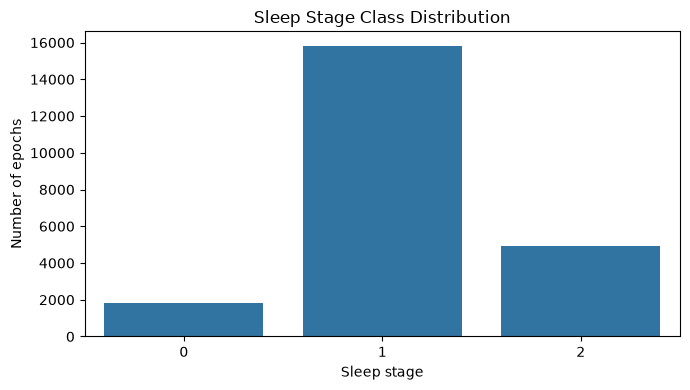

In [18]:
# 1. Target distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.countplot(data=data, x='sleep_stage', order=sorted(data['sleep_stage'].unique()))
plt.title("Sleep Stage Class Distribution")
plt.xlabel("Sleep stage")
plt.ylabel("Number of epochs")
plt.tight_layout()
plt.show()

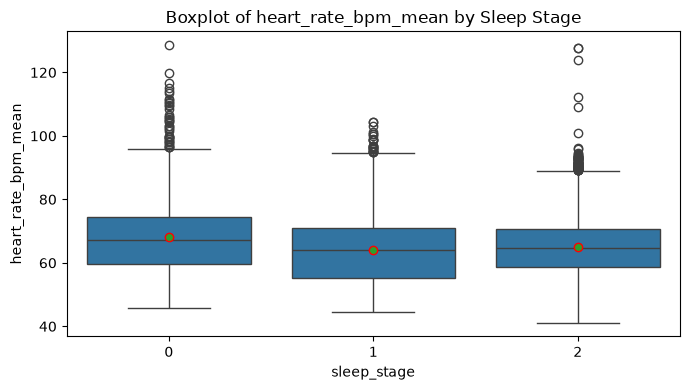

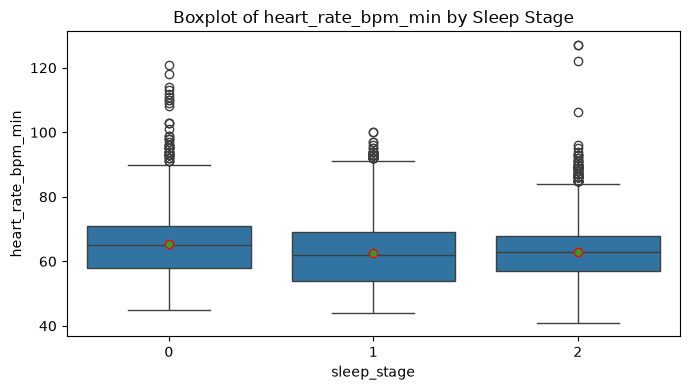

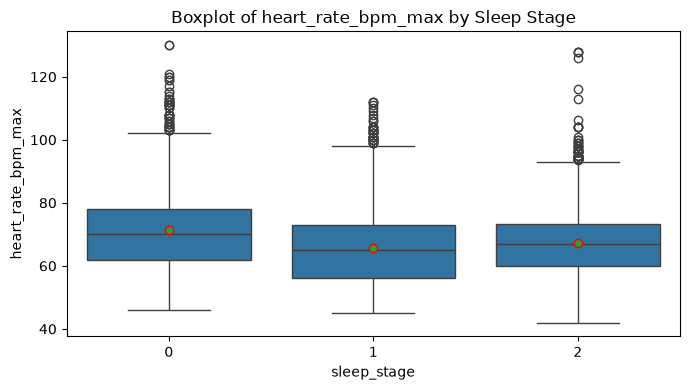

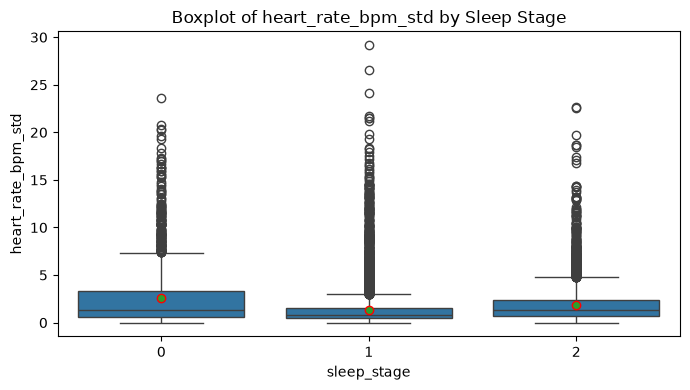

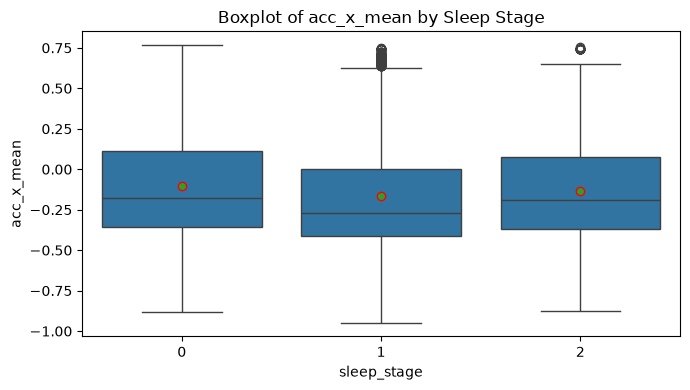

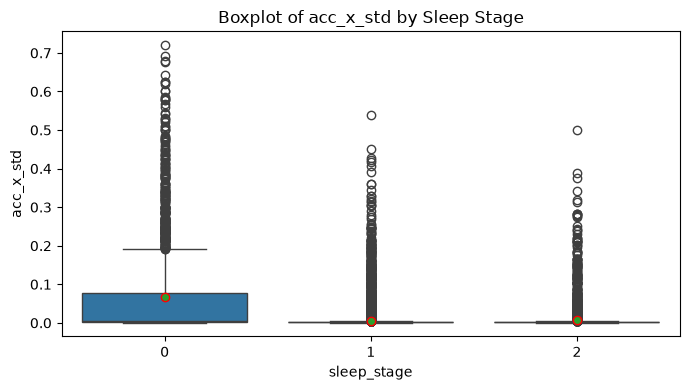

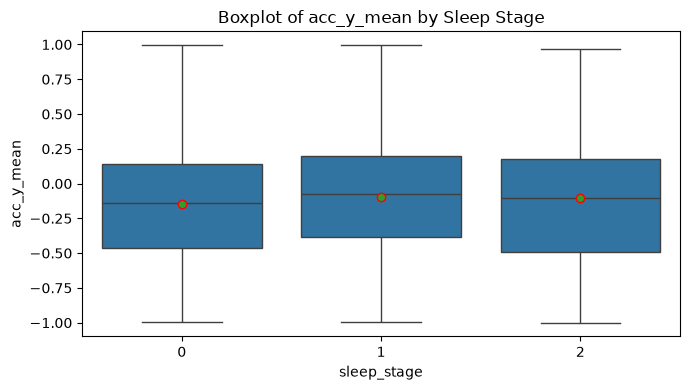

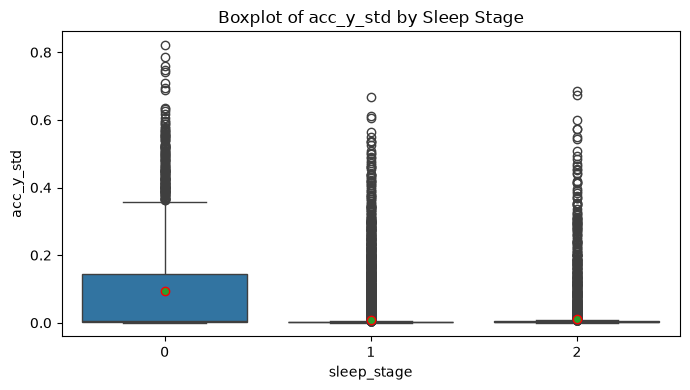

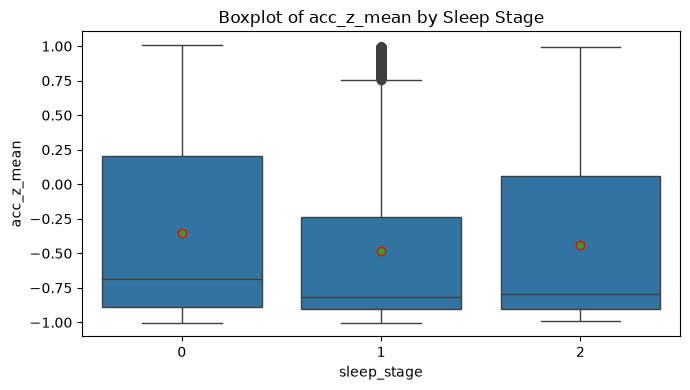

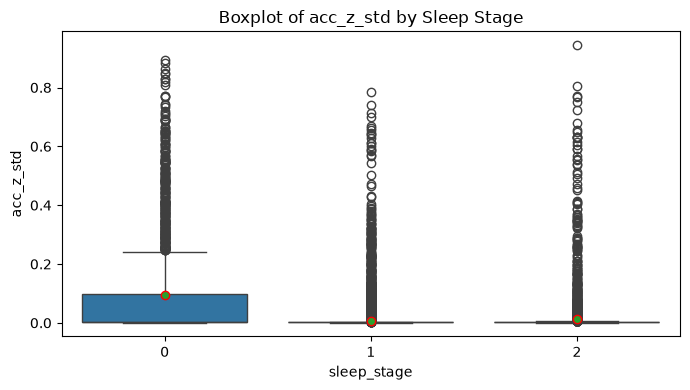

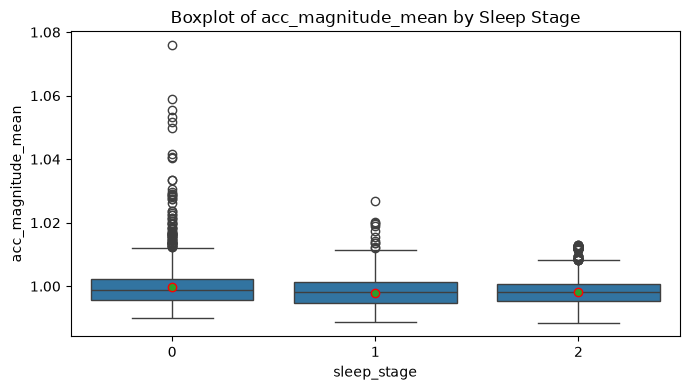

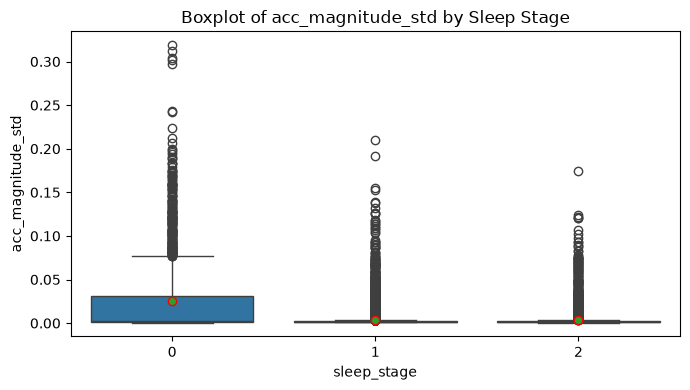

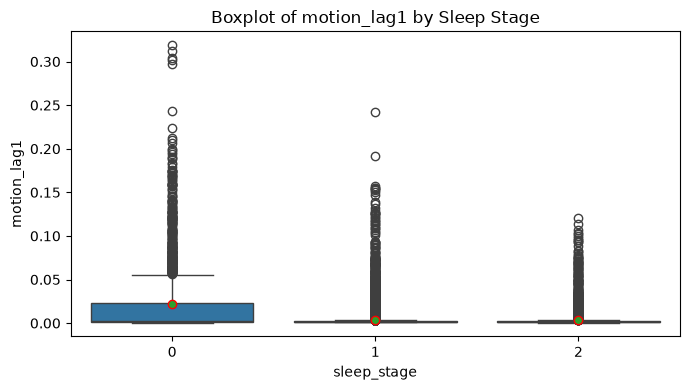

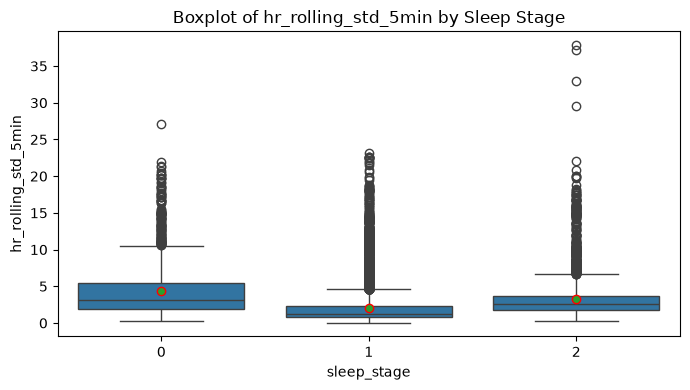

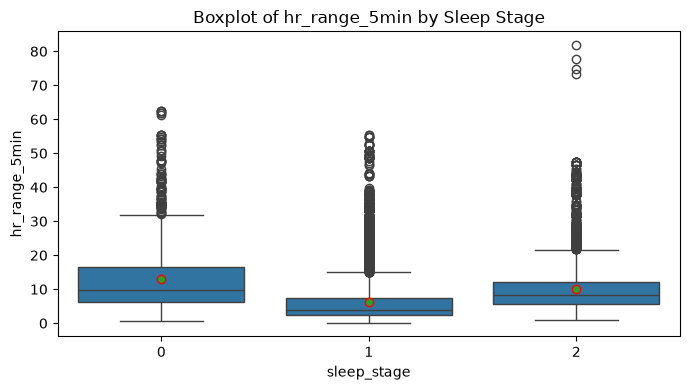

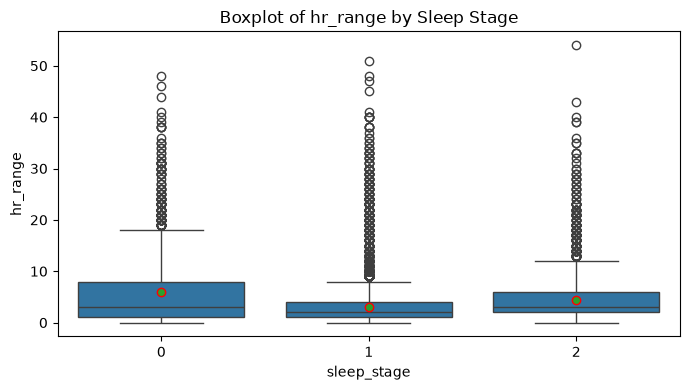

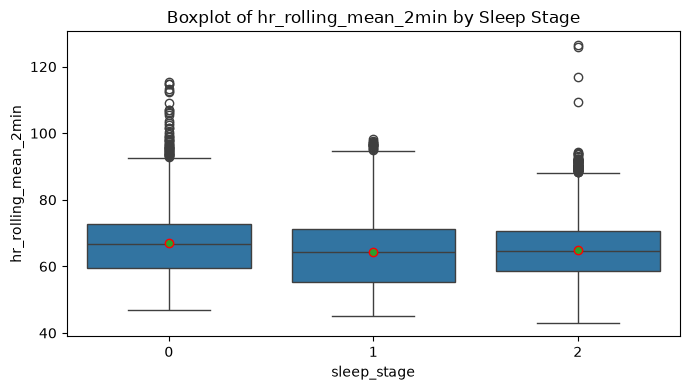

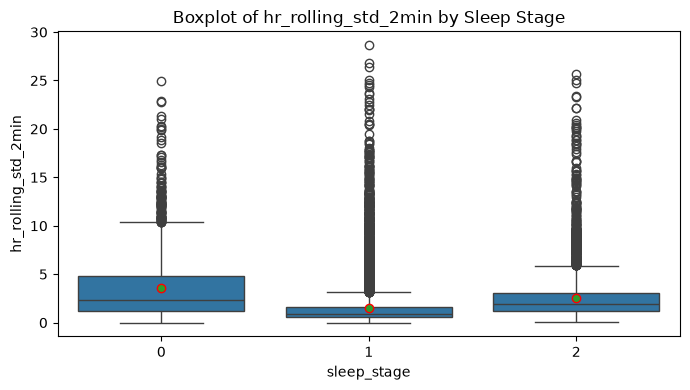

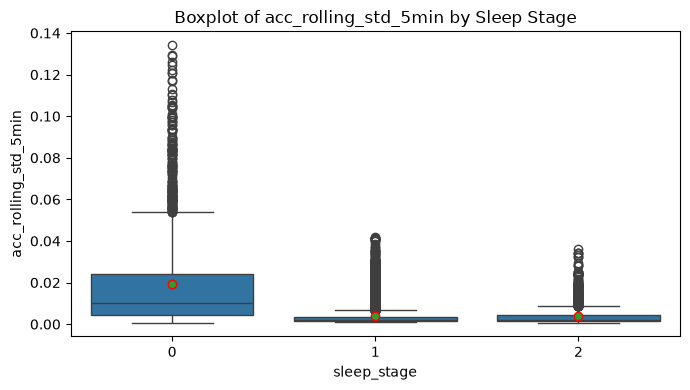

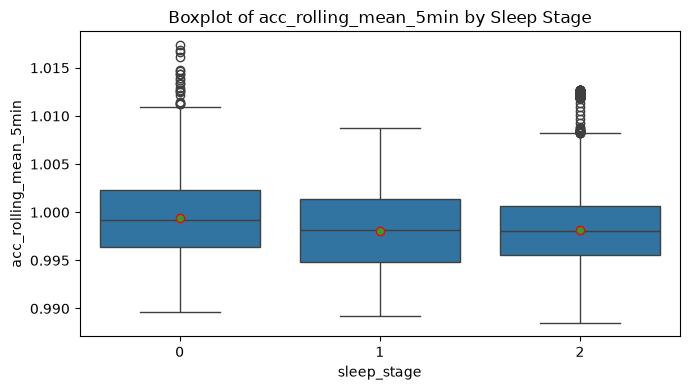

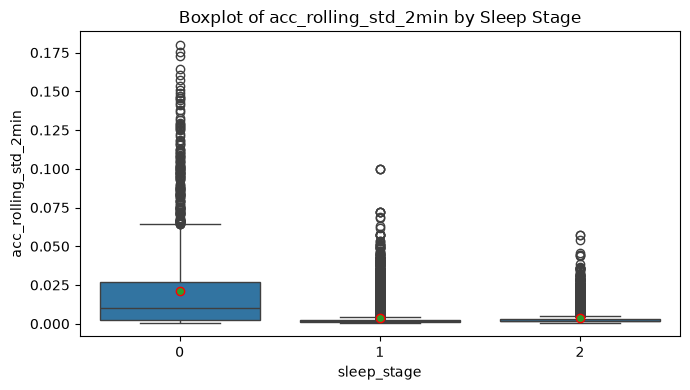

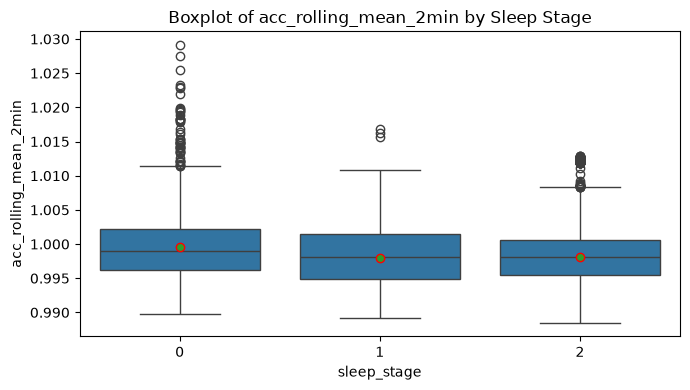

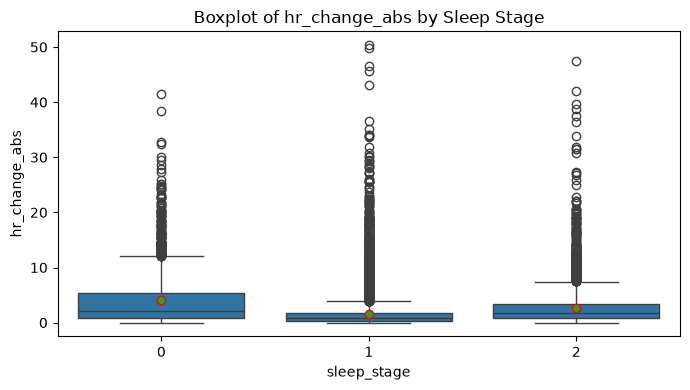

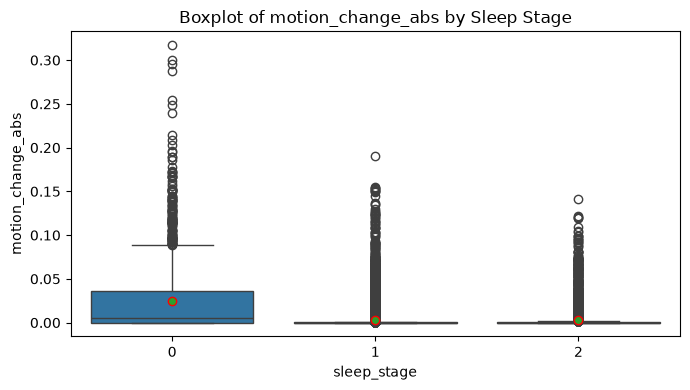

In [59]:
# Identify numeric sensor features
exclude = {'sleep_stage', 'epoch', 'participant_id'}

feature_cols = [
    c for c in data.select_dtypes(include=np.number).columns
    if c not in exclude
]


# 2. Feature distributions across sleep stages
for col in feature_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=data, x='sleep_stage', y=col, showmeans=True, meanprops = {'marker':'o','markeredgecolor':'red'})
    plt.title(f"Boxplot of {col} by Sleep Stage")
    plt.tight_layout()
    plt.show()

In [60]:
print("Features with missing values:")
print(' ')
print(data.isna().sum())

Features with missing values:
 
participant_id            0
epoch                     0
sleep_stage               0
heart_rate_bpm_mean       0
heart_rate_bpm_min        0
heart_rate_bpm_max        0
heart_rate_bpm_std        6
acc_x_mean                1
acc_x_std                 1
acc_y_mean                1
acc_y_std                 1
acc_z_mean                1
acc_z_std                 1
acc_magnitude_mean        1
acc_magnitude_std         1
motion_lag1              26
hr_rolling_std_5min      53
hr_range_5min            53
hr_range                  0
hr_rolling_mean_2min     30
hr_rolling_std_2min      30
acc_rolling_std_5min     51
acc_rolling_mean_5min    51
acc_rolling_std_2min     26
acc_rolling_mean_2min    26
hr_change_abs            30
motion_change_abs        26
dtype: int64


In [61]:
exclude = {'participant_id'}

x = [
    c for c in data.select_dtypes(include=np.number).columns
    if c not in exclude
]

print(data[x].describe().T)

                         count          mean          std           min  \
epoch                  20121.0  14257.668108  8215.649299  0.000000e+00   
sleep_stage            20121.0      1.164654     0.555360  0.000000e+00   
heart_rate_bpm_mean    20121.0     64.626645    10.496518  4.116667e+01   
heart_rate_bpm_min     20121.0     62.932242    10.123876  4.100000e+01   
heart_rate_bpm_max     20121.0     66.536205    11.300927  4.200000e+01   
heart_rate_bpm_std     20115.0      1.534660     1.943572  0.000000e+00   
acc_x_mean             20120.0     -0.153210     0.341420 -9.475168e-01   
acc_x_std              20120.0      0.011066     0.045891  6.195926e-04   
acc_y_mean             20120.0     -0.103433     0.449162 -9.995665e-01   
acc_y_std              20120.0      0.017222     0.064955  4.521746e-04   
acc_z_mean             20120.0     -0.458966     0.648650 -1.002029e+00   
acc_z_std              20120.0      0.015588     0.068853  7.410546e-04   
acc_magnitude_mean     20

In [62]:
data[x].info()

<class 'pandas.DataFrame'>
RangeIndex: 20121 entries, 0 to 20120
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   epoch                  20121 non-null  int64  
 1   sleep_stage            20121 non-null  int64  
 2   heart_rate_bpm_mean    20121 non-null  float64
 3   heart_rate_bpm_min     20121 non-null  float64
 4   heart_rate_bpm_max     20121 non-null  float64
 5   heart_rate_bpm_std     20115 non-null  float64
 6   acc_x_mean             20120 non-null  float64
 7   acc_x_std              20120 non-null  float64
 8   acc_y_mean             20120 non-null  float64
 9   acc_y_std              20120 non-null  float64
 10  acc_z_mean             20120 non-null  float64
 11  acc_z_std              20120 non-null  float64
 12  acc_magnitude_mean     20120 non-null  float64
 13  acc_magnitude_std      20120 non-null  float64
 14  motion_lag1            20095 non-null  float64
 15  hr_rolling_st

In [63]:
print(data['epoch'].iloc[-1])

29640


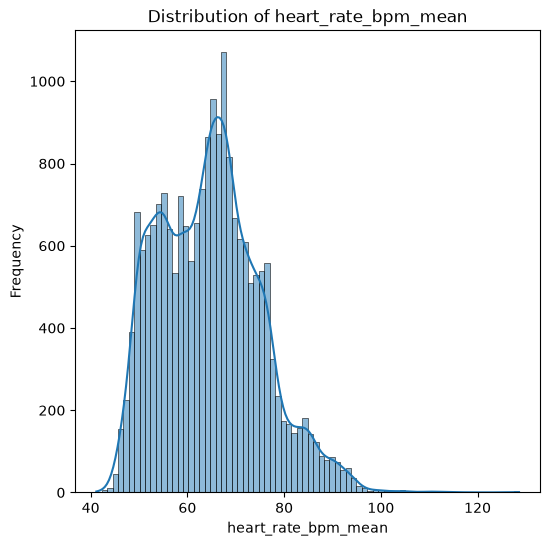

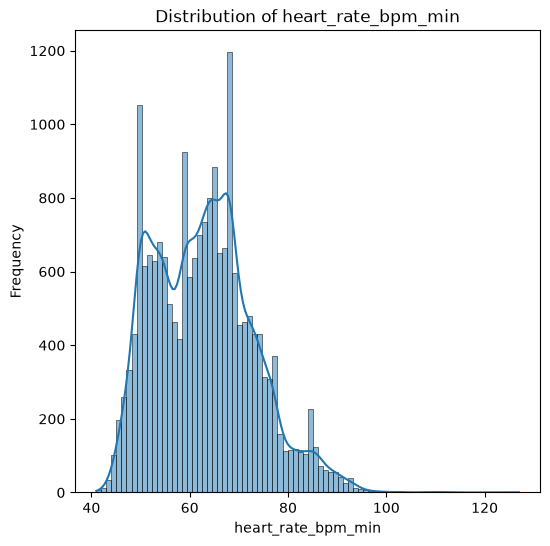

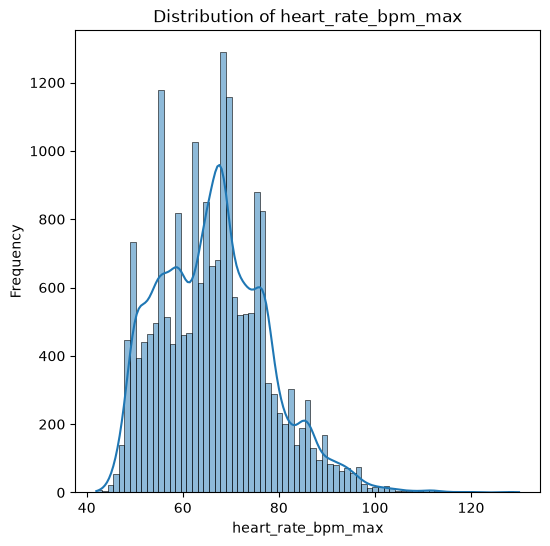

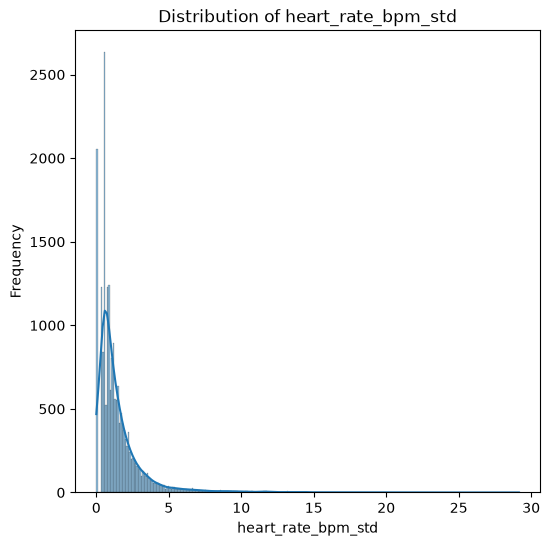

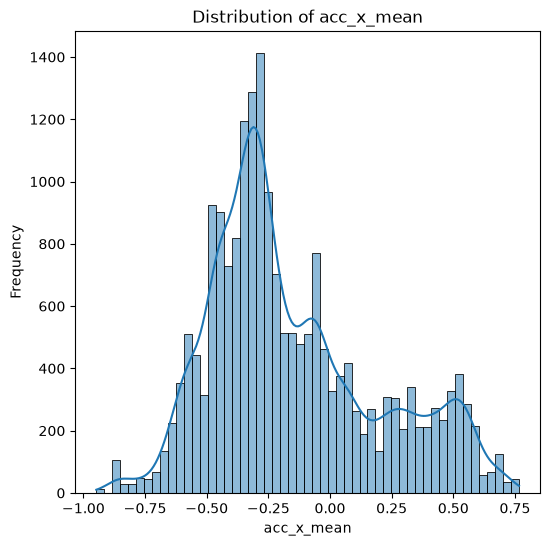

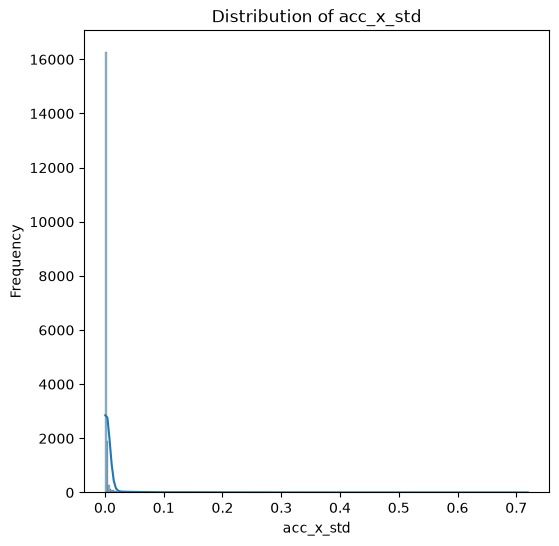

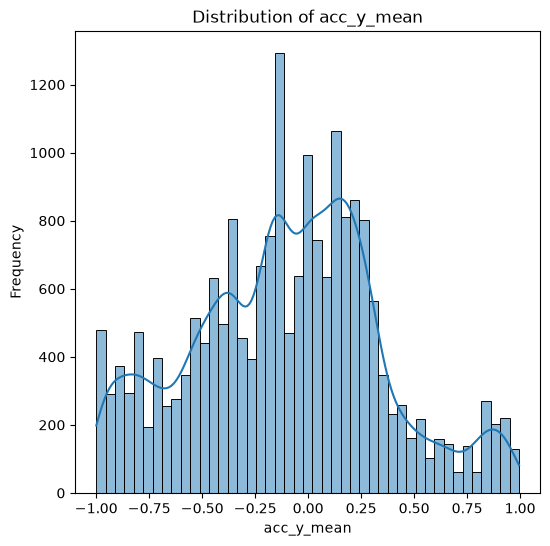

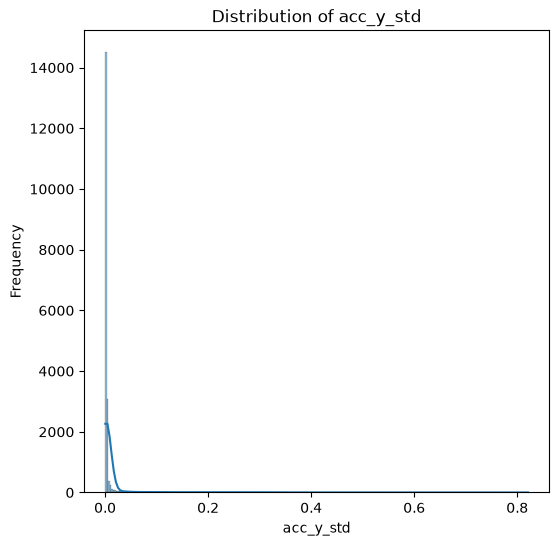

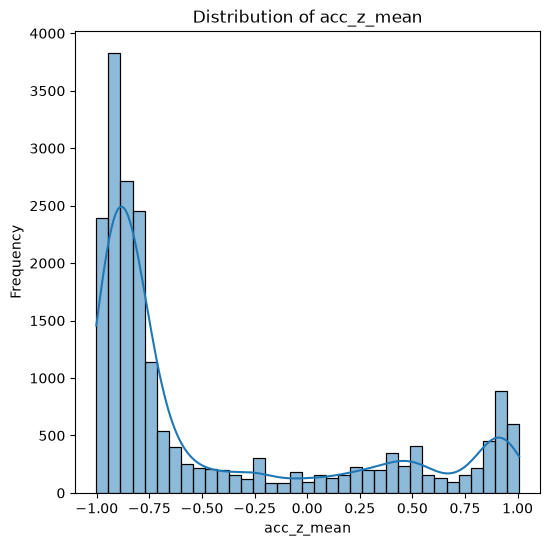

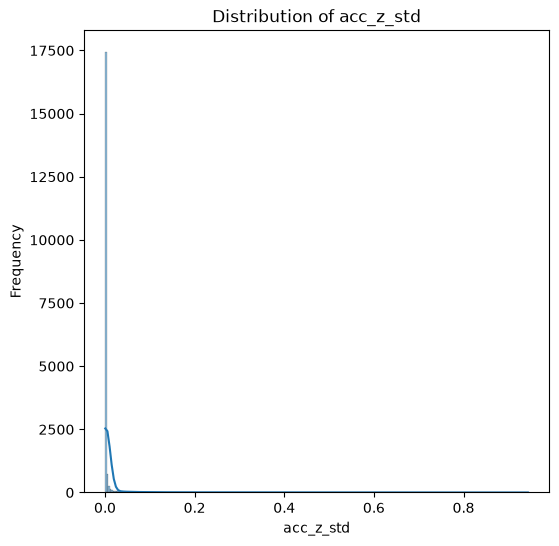

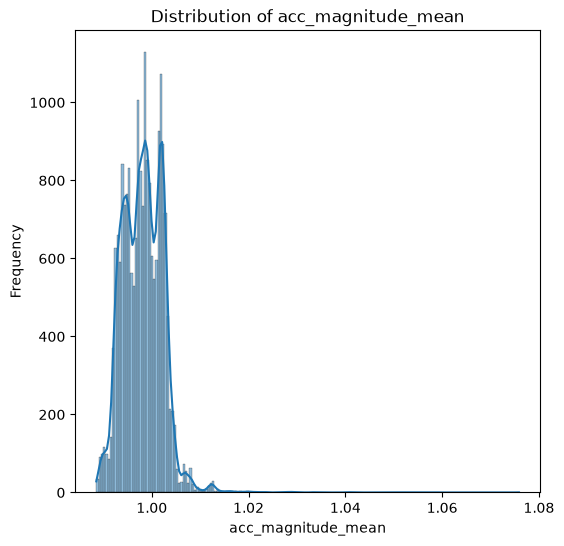

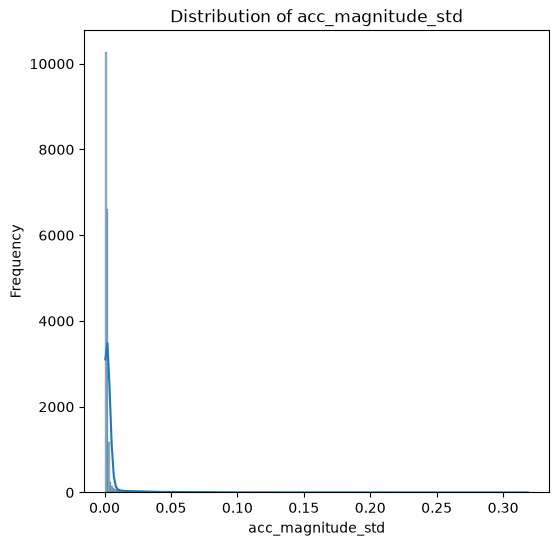

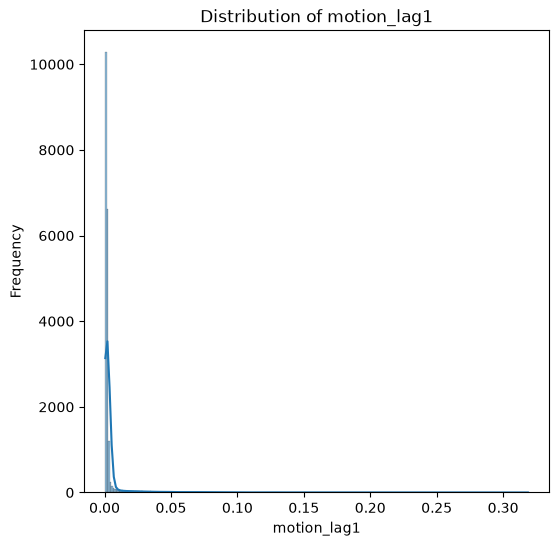

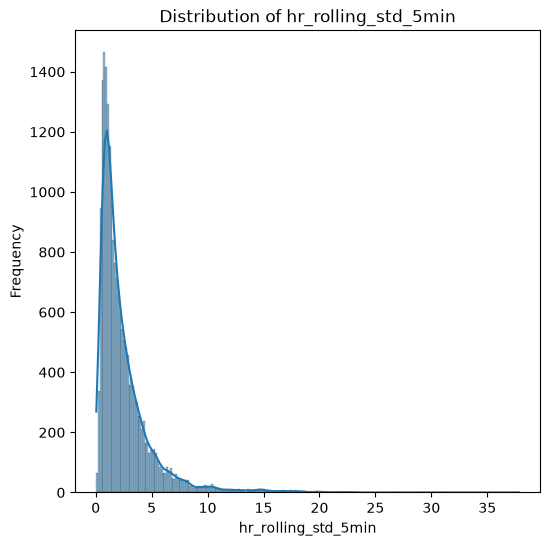

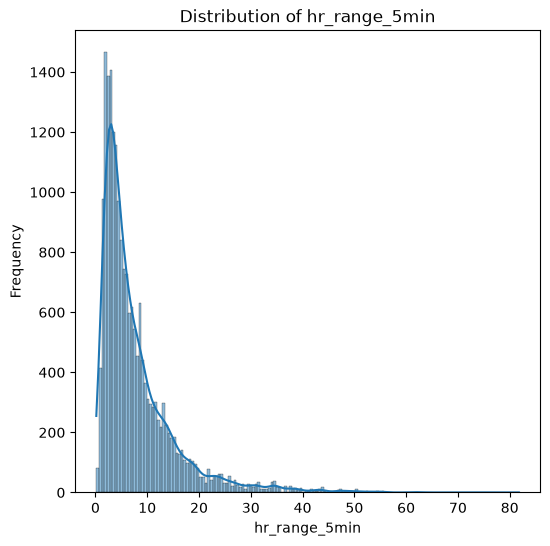

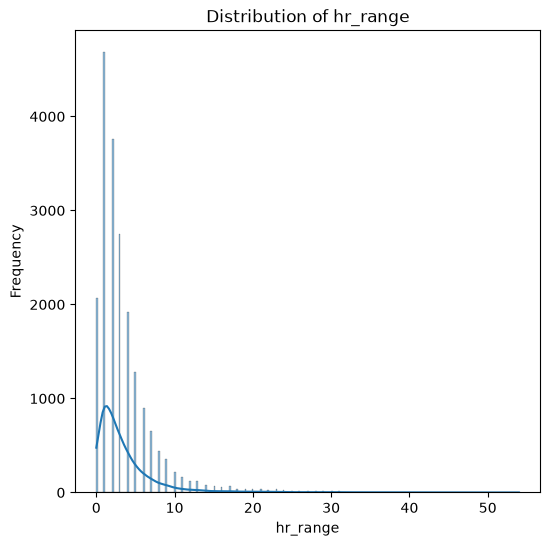

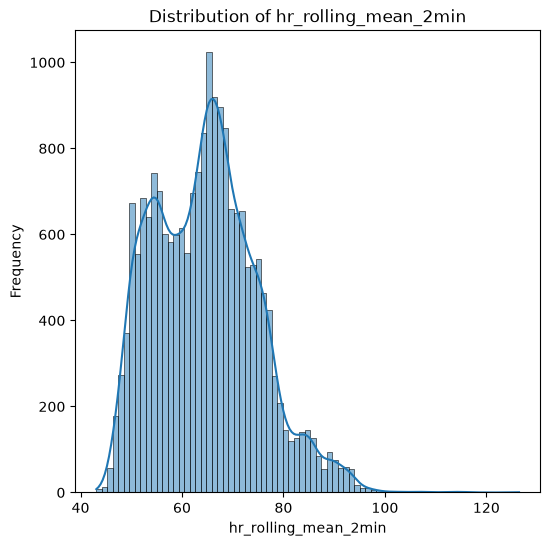

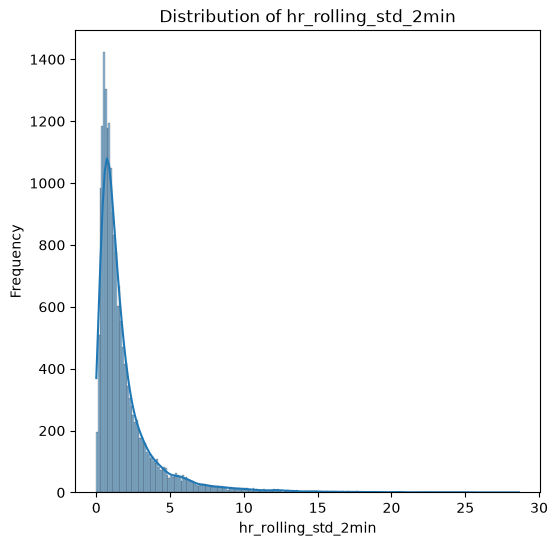

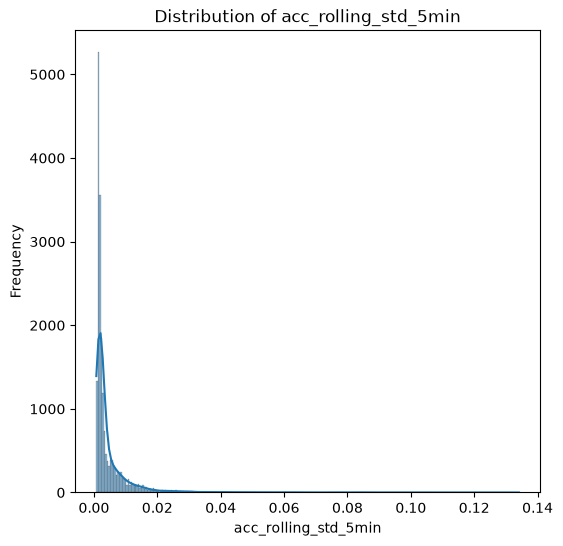

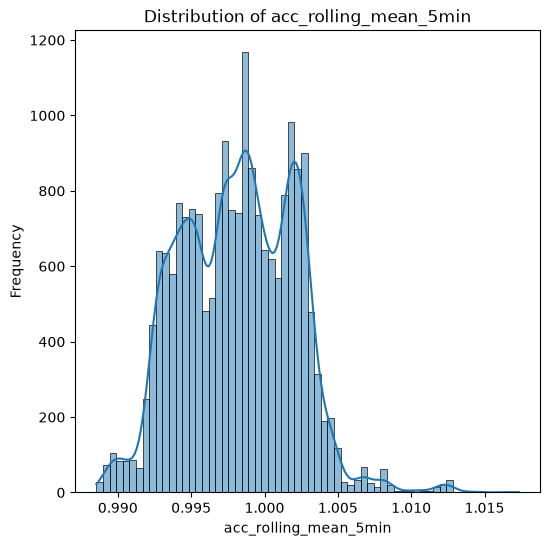

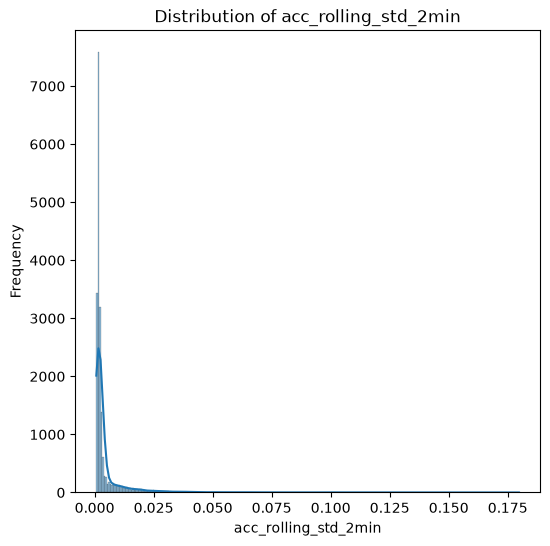

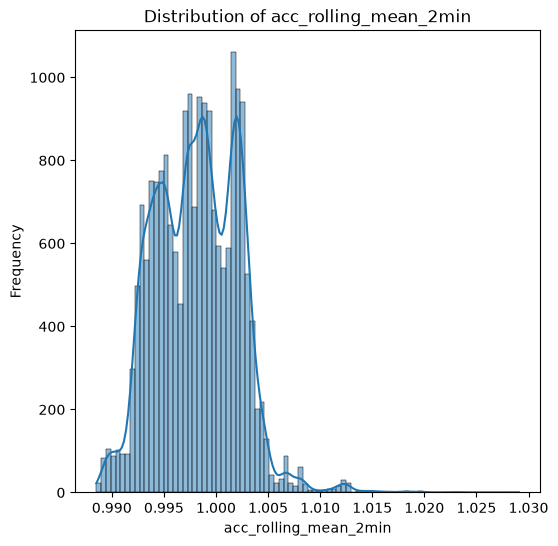

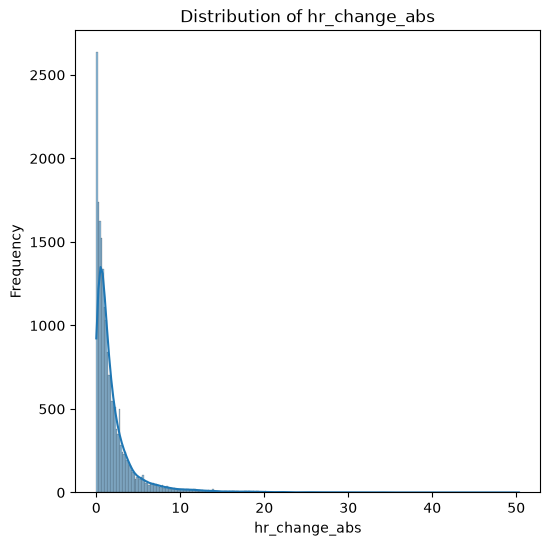

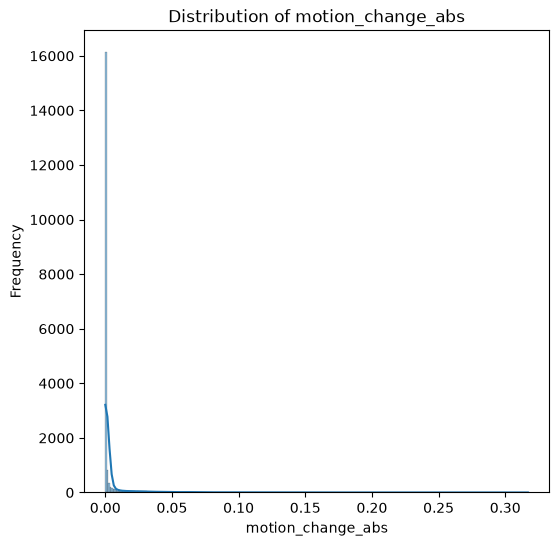

In [64]:
# DISTRIBUTION
# Identify numeric sensor features
exclude = {'sleep_stage', 'epoch', 'participant_id'}

feature_cols = [
    c for c in data.select_dtypes(include=np.number).columns
    if c not in exclude
]

for col in feature_cols:
    plt.figure(figsize=(6,6))
    sns.histplot( data=data, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [65]:
outlier_results = []

for col in feature_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (data[col] < lower) | (data[col] > upper)

    outlier_results.append({
        'feature': col,
        'outlier_count': int(mask.sum()),
        'lower_bound': lower,
        'upper_bound': upper
    })

outlier_df = pd.DataFrame(outlier_results)

print(outlier_df.sort_values(
    'outlier_count', ascending=False
).to_string(index=False))

              feature  outlier_count  lower_bound  upper_bound
    motion_change_abs           3730    -0.000764     0.001352
 acc_rolling_std_2min           3325    -0.000754     0.005104
            acc_y_std           2436    -0.001753     0.006728
            acc_z_std           2316    -0.000684     0.005032
 acc_rolling_std_5min           2210    -0.003563     0.010049
            acc_x_std           2183    -0.000685     0.004751
    acc_magnitude_std           2155    -0.000042     0.003696
          motion_lag1           2123    -0.000036     0.003684
  hr_rolling_std_2min           1806    -1.736723     4.615865
        hr_change_abs           1783    -2.383333     5.216667
             hr_range           1655    -3.500000     8.500000
   heart_rate_bpm_std           1434    -1.461277     3.812523
  hr_rolling_std_5min           1304    -2.330205     6.397501
        hr_range_5min           1265    -7.450000    20.416667
   heart_rate_bpm_min            162    34.000000    90

In [66]:
import numpy as np
import pandas as pd

# Work on a copy; do not delete any rows
df = data.copy()

# 1. Basic data-quality checks
df["hr_invalid"] = (
    df["heart_rate_bpm_mean"].isna()
    | (df["heart_rate_bpm_mean"] < 30)
    | (df["heart_rate_bpm_mean"] > 210)
)

# 2. High/low heart-rate review flags
df["hr_low_review"] = (
    df["heart_rate_bpm_mean"] < 40
)

df["hr_high_review"] = (
    df["heart_rate_bpm_mean"] > 120
)

# 3. Invalid standard deviation values
df["hr_std_invalid"] = (
    df["heart_rate_bpm_std"].isna()
    | (df["heart_rate_bpm_std"] < 0)
)

# 4. Flag unusually large 30-second HR changes
df["hr_change_review"] = (
    df["hr_change_abs"] > 20
)


# 6. Combine the review flags
df["any_hr_alert"] = (
    df["hr_low_review"]
    | df["hr_high_review"]
    | df["hr_change_review"]
)

# View flagged epochs
alert_cols = [
    "participant_id",
    "epoch",
    "heart_rate_bpm_mean",
    "hr_change_abs",
    "hr_invalid",
    "hr_low_review",
    "hr_high_review",
    "hr_change_review"
]

print(df.loc[df["any_hr_alert"] | df["hr_invalid"], alert_cols]
        .head(30))

# Count each type of flag
print("\nFlag counts:")
print(df[[
    "hr_invalid",
    "hr_low_review",
    "hr_high_review",
    "hr_change_review"
]].sum())

      participant_id  epoch  heart_rate_bpm_mean  hr_change_abs  hr_invalid  \
393          2598705    870            50.000000      41.400000       False   
547          1455390   1080            60.833333      24.500000       False   
980          8686948   1650            71.800000      29.400000       False   
1459         8000685   2310            86.833333      22.000000       False   
1480         8000685   2340            58.600000      28.233333       False   
1564         8000685   2460            59.200000      25.466667       False   
1669         8000685   2610            59.666667      33.733333       False   
2180         9961348   3330            75.600000      20.171429       False   
2200         9961348   3360            51.333333      24.266667       False   
2752         1455390   4170            80.200000      30.033333       False   
2824         5797046   4260            84.285714      21.485714       False   
2836         1455390   4290            50.333333    

In [67]:
high_hr = df.loc[
    df["hr_high_review"],
    [
        "participant_id",
        "epoch",
        "heart_rate_bpm_mean",
        "heart_rate_bpm_min",
        "heart_rate_bpm_max",
        "heart_rate_bpm_std",
        "hr_change_abs"
    ]
]

print(high_hr.to_string(index=False))

 participant_id  epoch  heart_rate_bpm_mean  heart_rate_bpm_min  heart_rate_bpm_max  heart_rate_bpm_std  hr_change_abs
        5498603  10830           128.571429               121.0               130.0            3.359422      20.171429
        2598705  26940           123.857143               122.0               126.0            1.345185       5.313492
        2598705  26970           127.800000               127.0               128.0            0.447214       3.942857
        2598705  27000           127.666667               127.0               128.0            0.516398       0.133333


In [68]:
# To check nearby heart_rate_bpm_mean of high_hr.

df = df.sort_values(["participant_id", "epoch"])

for idx in df.index[df["hr_high_review"]]:
    pid = df.loc[idx, "participant_id"]
    t = df.loc[idx, "epoch"]

    nearby = df.loc[
        (df["participant_id"] == pid)
        & (df["epoch"].between(t - 120, t + 120)),
        [
            "participant_id",
            "epoch",
            "heart_rate_bpm_mean",
            "hr_change_abs"
        ]
    ]

    print("\nHigh HR at participant:", pid, "epoch:", t)
    print(nearby.to_string(index=False))


High HR at participant: 2598705 epoch: 26940
 participant_id  epoch  heart_rate_bpm_mean  hr_change_abs
        2598705  26820            77.971429      10.796032
        2598705  26850            89.442857       9.425397
        2598705  26880           100.914286       8.054762
        2598705  26910           112.385714       6.684127
        2598705  26940           123.857143       5.313492
        2598705  26970           127.800000       3.942857
        2598705  27000           127.666667       0.133333
        2598705  27030            88.000000      39.666667
        2598705  27060            81.400000       6.600000

High HR at participant: 2598705 epoch: 26970
 participant_id  epoch  heart_rate_bpm_mean  hr_change_abs
        2598705  26850            89.442857       9.425397
        2598705  26880           100.914286       8.054762
        2598705  26910           112.385714       6.684127
        2598705  26940           123.857143       5.313492
        2598705  26970 

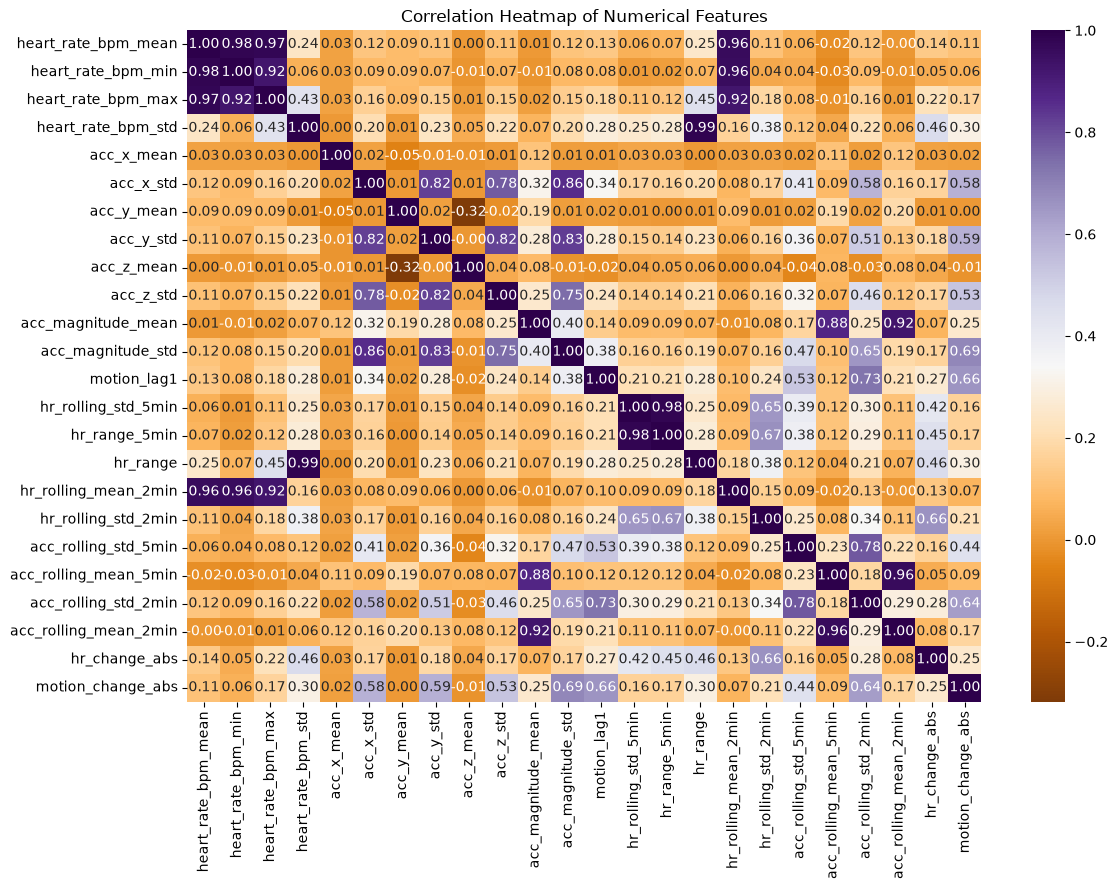

In [69]:
# Correlation Heatmap

# Calculating correlation
corr = data[feature_cols].corr()

# Plot heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    data=corr,
    annot=True,
    cmap='PuOr',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

In [57]:
# ============================================================
# 1. IMPORTS AND SETTINGS
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import optuna

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.svm import LinearSVC

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# CatBoost is optional
try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False


# ---------------- USER SETTINGS ----------------

TARGET = "sleep_stage"
N_SPLITS = 4
N_TRIALS_PER_MODEL = 15
RANDOM_SEED = 42

# Set this to the existing training dataframe.
# Keep df15, df22, df25 out of `data`.
df_train = data.copy()

# ============================================================
# 2. PREPARE X AND y
# ============================================================

if TARGET not in df_train.columns:
    raise ValueError(f"Missing target column: {TARGET}")

df_train = df_train.dropna(subset=[TARGET]).copy()

y = df_train[TARGET].astype(int).to_numpy()

# Do not use participant IDs or epoch/time as model features.
id_cols = [
    "participant_id", 
    "epoch"
]

X = df_train.drop(
    columns=[TARGET] + [
        c for c in id_cols if c in df_train.columns
    ],
    errors="ignore"
).copy()

# Keep numeric features only
X = X.select_dtypes(include=[np.number])
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that are entirely missing
X = X.dropna(axis=1, how="all")

# Make sure the target labels are the intended encoded classes.
print("Classes:", np.unique(y))
print("X shape:", X.shape)
print("Rows:", len(y))

if set(np.unique(y)) != {0, 1, 2}:
    raise ValueError(
        "Expected sleep_stage labels 0,1,2. "
        "Check your existing label encoding before tuning."
    )

groups = df_train["participant_id"].to_numpy()

skf = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

folds = list(skf.split(X, y, groups=groups))

for fold_no, (tr_idx, va_idx) in enumerate(folds, start=1):
    print(
        f"Fold {fold_no}: train={len(tr_idx)}, "
        f"validation={len(va_idx)}, "
        f"validation classes={np.unique(y[va_idx])}"
    )

# ============================================================
# 3. OPTUNA PARAMETER SPACES
# ============================================================

def suggest_params(trial, name):

    p = {}

    # --------------------------------------------------------
    # Logistic Regression: One-vs-Rest
    # --------------------------------------------------------
    if name == "OvR":

        p["C"] = trial.suggest_float("C", 1e-4, 1e3, log=True)
        p["class_weight"] = trial.suggest_categorical(
            "class_weight", [None, "balanced"]
        )
        p["tol"] = trial.suggest_float("tol", 1e-6, 1e-2, log=True)
        p["fit_intercept"] = trial.suggest_categorical(
            "fit_intercept", [True, False]
        )
        p["max_iter"] = trial.suggest_categorical(
            "max_iter", [1000, 2000, 4000]
        )

        # Valid solver/penalty combinations
        combo = trial.suggest_categorical(
            "solver_penalty",
            ["lbfgs_l2", "liblinear_l1", "liblinear_l2",
             "saga_l1", "saga_l2", "saga_elasticnet"]
        )

        solver, penalty = combo.split("_", 1)
        p["solver"] = solver
        p["penalty"] = penalty

        if penalty == "elasticnet":
            p["l1_ratio"] = trial.suggest_float("l1_ratio", 0.0, 1.0)

        return p

    # --------------------------------------------------------
    # Multinomial / Softmax Logistic Regression
    # --------------------------------------------------------
    if name == "Softmax":

        p["C"] = trial.suggest_float("C", 1e-4, 1e3, log=True)
        p["class_weight"] = trial.suggest_categorical(
            "class_weight", [None, "balanced"]
        )
        p["tol"] = trial.suggest_float("tol", 1e-6, 1e-2, log=True)
        p["fit_intercept"] = trial.suggest_categorical(
            "fit_intercept", [True, False]
        )
        p["max_iter"] = trial.suggest_categorical(
            "max_iter", [1000, 2000, 4000]
        )

        combo = trial.suggest_categorical(
            "solver_penalty",
            ["lbfgs_l2", "saga_l1", "saga_l2", "saga_elasticnet"]
        )
        solver, penalty = combo.split("_", 1)
        p["solver"] = solver
        p["penalty"] = penalty

        if penalty == "elasticnet":
            p["l1_ratio"] = trial.suggest_float("l1_ratio", 0.0, 1.0)

        return p

    # --------------------------------------------------------
    # Decision Tree
    # --------------------------------------------------------
    if name == "Decision Tree":

        p["criterion"] = trial.suggest_categorical(
            "criterion", ["gini", "entropy", "log_loss"]
        )
        p["splitter"] = trial.suggest_categorical(
            "splitter", ["best", "random"]
        )
        p["max_depth"] = trial.suggest_categorical(
            "max_depth", [None, 3, 5, 8, 12, 16, 24, 32]
        )
        p["min_samples_split"] = trial.suggest_int(
            "min_samples_split", 2, 50
        )
        p["min_samples_leaf"] = trial.suggest_int(
            "min_samples_leaf", 1, 30
        )
        p["max_features"] = trial.suggest_categorical(
            "max_features", [None, "sqrt", "log2"]
        )
        p["max_leaf_nodes"] = trial.suggest_categorical(
            "max_leaf_nodes", [None, 10, 20, 40, 80, 150]
        )
        p["min_weight_fraction_leaf"] = trial.suggest_float(
            "min_weight_fraction_leaf", 0.0, 0.1
        )
        p["min_impurity_decrease"] = trial.suggest_float(
            "min_impurity_decrease", 0.0, 0.02
        )
        p["ccp_alpha"] = trial.suggest_float(
            "ccp_alpha", 1e-8, 0.05, log=True
        )
        p["class_weight"] = trial.suggest_categorical(
            "class_weight", [None, "balanced"]
        )

        return p

    # --------------------------------------------------------
    # Random Forest / Extra Trees
    # --------------------------------------------------------
    if name in ["Random Forest", "Extra Trees"]:

        p["n_estimators"] = trial.suggest_int(
            "n_estimators", 200, 1200, step=100
        )
        p["criterion"] = trial.suggest_categorical(
            "criterion", ["gini", "entropy", "log_loss"]
        )
        p["max_depth"] = trial.suggest_categorical(
            "max_depth", [None, 5, 8, 12, 16, 24, 32, 48]
        )
        p["min_samples_split"] = trial.suggest_int(
            "min_samples_split", 2, 40
        )
        p["min_samples_leaf"] = trial.suggest_int(
            "min_samples_leaf", 1, 25
        )
        p["max_features"] = trial.suggest_categorical(
            "max_features", ["sqrt", "log2", None]
        )
        p["max_leaf_nodes"] = trial.suggest_categorical(
            "max_leaf_nodes", [None, 20, 50, 100, 200]
        )
        p["min_weight_fraction_leaf"] = trial.suggest_float(
            "min_weight_fraction_leaf", 0.0, 0.1
        )
        p["min_impurity_decrease"] = trial.suggest_float(
            "min_impurity_decrease", 0.0, 0.02
        )
        p["ccp_alpha"] = trial.suggest_float(
            "ccp_alpha", 1e-8, 0.05, log=True
        )
        p["class_weight"] = trial.suggest_categorical(
            "class_weight",
            [None, "balanced", "balanced_subsample"]
            if name == "Random Forest"
            else [None, "balanced"]
        )
        p["bootstrap"] = trial.suggest_categorical(
            "bootstrap", [True, False]
        )

        # max_samples is valid only when bootstrap=True
        if p["bootstrap"]:
            p["max_samples"] = trial.suggest_float(
                "max_samples", 0.5, 1.0
            )
        else:
            p["max_samples"] = None

        return p

    # --------------------------------------------------------
    # Gaussian Naive Bayes
    # --------------------------------------------------------
    if name == "Gaussian NB":

        p["var_smoothing"] = trial.suggest_float(
            "var_smoothing", 1e-12, 1e-6, log=True
        )
        return p

    # --------------------------------------------------------
    # K-Nearest Neighbours
    # --------------------------------------------------------
    if name == "KNN":

        p["n_neighbors"] = trial.suggest_int("n_neighbors", 3, 61, step=2)
        p["weights"] = trial.suggest_categorical(
            "weights", ["uniform", "distance"]
        )
        p["algorithm"] = trial.suggest_categorical(
            "algorithm", ["auto", "ball_tree", "kd_tree", "brute"]
        )
        p["leaf_size"] = trial.suggest_int("leaf_size", 10, 80)
        p["p"] = trial.suggest_int("p", 1, 2)

        return p


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------
    if name == "XGBoost":

        p["n_estimators"] = trial.suggest_int(
            "n_estimators", 200, 1200, step=100
        )
        p["max_depth"] = trial.suggest_int("max_depth", 2, 12)
        p["learning_rate"] = trial.suggest_float(
            "learning_rate", 0.005, 0.2, log=True
        )
        p["min_child_weight"] = trial.suggest_float(
            "min_child_weight", 0.1, 30, log=True
        )
        p["subsample"] = trial.suggest_float("subsample", 0.5, 1.0)
        p["colsample_bytree"] = trial.suggest_float(
            "colsample_bytree", 0.5, 1.0
        )
        p["colsample_bylevel"] = trial.suggest_float(
            "colsample_bylevel", 0.5, 1.0
        )
        p["colsample_bynode"] = trial.suggest_float(
            "colsample_bynode", 0.5, 1.0
        )
        p["reg_alpha"] = trial.suggest_float(
            "reg_alpha", 1e-8, 100, log=True
        )
        p["reg_lambda"] = trial.suggest_float(
            "reg_lambda", 1e-5, 100, log=True
        )
        p["gamma"] = trial.suggest_float("gamma", 0.0, 10.0)
        p["max_delta_step"] = trial.suggest_int(
            "max_delta_step", 0, 10
        )
        p["max_bin"] = trial.suggest_categorical(
            "max_bin", [64, 128, 256, 512]
        )
        p["grow_policy"] = trial.suggest_categorical(
            "grow_policy", ["depthwise", "lossguide"]
        )

        if p["grow_policy"] == "lossguide":
            p["max_leaves"] = trial.suggest_int("max_leaves", 0, 64)
        else:
            p["max_leaves"] = 0

        return p

    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------
    if name == "LightGBM":

        p["n_estimators"] = trial.suggest_int(
            "n_estimators", 200, 1200, step=100
        )
        p["learning_rate"] = trial.suggest_float(
            "learning_rate", 0.005, 0.15, log=True
        )
        p["num_leaves"] = trial.suggest_int("num_leaves", 7, 63)
        p["max_depth"] = trial.suggest_categorical(
            "max_depth", [-1, 3, 4, 5, 6, 8, 10, 12]
        )
        p["min_child_samples"] = trial.suggest_int(
            "min_child_samples", 10, 120
        )
        p["min_child_weight"] = trial.suggest_float(
            "min_child_weight", 1e-4, 10, log=True
        )
        p["subsample"] = trial.suggest_float("subsample", 0.6, 1.0)
        p["subsample_freq"] = trial.suggest_int("subsample_freq", 1, 7)
        p["colsample_bytree"] = trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        )
        p["reg_alpha"] = trial.suggest_float(
            "reg_alpha", 1e-8, 10, log=True
        )
        p["reg_lambda"] = trial.suggest_float(
            "reg_lambda", 1e-8, 20, log=True
        )
        p["min_split_gain"] = trial.suggest_float(
            "min_split_gain", 0.0, 1.0
        )
        p["max_bin"] = trial.suggest_categorical(
            "max_bin", [63, 127, 191, 255]
        )
        p["class_weight"] = trial.suggest_categorical(
            "class_weight", [None, "balanced"]
        )
        p["boosting_type"] = trial.suggest_categorical(
            "boosting_type", ["gbdt", "dart"]
        )

        return p

    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------
    if name == "CatBoost":

        p["iterations"] = trial.suggest_int(
            "iterations", 200, 1200, step=100
        )
        p["depth"] = trial.suggest_int("depth", 4, 10)
        p["learning_rate"] = trial.suggest_float(
            "learning_rate", 0.005, 0.2, log=True
        )
        p["l2_leaf_reg"] = trial.suggest_float(
            "l2_leaf_reg", 1e-2, 100, log=True
        )
        p["random_strength"] = trial.suggest_float(
            "random_strength", 0.0, 10.0
        )
        p["bagging_temperature"] = trial.suggest_float(
            "bagging_temperature", 0.0, 10.0
        )
        p["border_count"] = trial.suggest_categorical(
            "border_count", [32, 64, 128, 254]
        )
        p["auto_class_weights"] = trial.suggest_categorical(
            "auto_class_weights", [None, "Balanced", "SqrtBalanced"]
        )

        return p

        # --------------------------------------------------------
        # SVM
        # --------------------------------------------------------
    if name == "SVM":
        p["C"] = trial.suggest_float(
            "C", 1e-2, 10, log=True
        )
        p["class_weight"] = trial.suggest_categorical(
            "class_weight", [None, "balanced"]
        )
        return p


    raise ValueError(f"Unknown model: {name}")


# ============================================================
# 4. BUILD EACH MODEL
# ============================================================

def build_model(name, p):
    """Build a model and add imputation only if the estimator needs it."""

    # Logistic Regression: OvR and Softmax
    if name in ["OvR", "Softmax"]:
        lr_params = dict(
            C=p["C"],
            penalty=p["penalty"],
            solver=p["solver"],
            class_weight=p["class_weight"],
            tol=p["tol"],
            max_iter=p["max_iter"],
            fit_intercept=p["fit_intercept"],
            random_state=RANDOM_SEED
        )
        if p["penalty"] == "elasticnet":
            lr_params["l1_ratio"] = p["l1_ratio"]

        lr = LogisticRegression(**lr_params)
        estimator = (
            OneVsRestClassifier(lr, n_jobs=1)
            if name == "OvR" else lr
        )
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", estimator)
        ])

    if name == "Decision Tree":
        estimator = DecisionTreeClassifier(**p, random_state=RANDOM_SEED)
    elif name == "Random Forest":
        estimator = RandomForestClassifier(
            **p, random_state=RANDOM_SEED, n_jobs=4
        )
    elif name == "Extra Trees":
        estimator = ExtraTreesClassifier(
            **p, random_state=RANDOM_SEED, n_jobs=4
        )
    elif name == "Gaussian NB":
        estimator = GaussianNB(**p)
    elif name == "KNN":
        estimator = KNeighborsClassifier(**p, n_jobs=4)
    elif name == "XGBoost":
        return XGBClassifier(
            **p,
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            tree_method="hist",
            n_jobs=4,
            random_state=RANDOM_SEED,
            verbosity=0
        )
    elif name == "LightGBM":
        return LGBMClassifier(
            **p,
            objective="multiclass",
            n_jobs=4,
            random_state=RANDOM_SEED,
            verbosity=-1
        )
    elif name == "CatBoost":
        return CatBoostClassifier(
            **p,
            loss_function="MultiClass",
            verbose=False,
            thread_count=4,
            random_seed=RANDOM_SEED,
            allow_writing_files=False
        )
    elif name == "SVM":
        estimator = LinearSVC(
            C=p["C"],
            class_weight=p["class_weight"],
            max_iter=5000,
            dual="auto",
            random_state=RANDOM_SEED
        )
    else:
        raise ValueError(f"Unknown model: {name}")

    # Scaling is important for distance/margin-based models.
    if name in ["KNN", "SVM"]:
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", estimator)
        ])

    # Ask scikit-learn's estimator tags whether NaNs are supported.
    # This adapts to the installed scikit-learn version, including
    # versions where tree models gained native NaN support.
    try:
        from sklearn.utils import get_tags
        supports_nan = get_tags(estimator).input_tags.allow_nan
    except (ImportError, AttributeError, TypeError):
        try:
            supports_nan = estimator._get_tags().get("allow_nan", False)
        except AttributeError:
            supports_nan = False

    if supports_nan:
        return estimator

    # Impute only when this estimator does not support NaN natively.
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator)
    ])

# ============================================================
# 5. RUN OPTUNA ON ALL MODELS, USING IDENTICAL FOLDS
# ============================================================

model_names = [
    "OvR",
    "Softmax",
    "Decision Tree",
    "Random Forest",
    "Extra Trees",
    "Gaussian NB",
    "KNN",
    "XGBoost",
    "LightGBM",
    "SVM"
]

if CATBOOST_AVAILABLE:
    model_names.append("CatBoost")

all_results = []
best_params_by_model = {}
best_scores_by_model = {}

for model_name in model_names:

    print("\n" + "=" * 70)
    print("TUNING:", model_name)
    print("=" * 70)

    def objective(trial):
        params = suggest_params(trial, model_name)

        fold_scores = []

        for fold_no, (tr_idx, va_idx) in enumerate(folds, start=1):

            X_tr = X.iloc[tr_idx]
            X_va = X.iloc[va_idx]
            y_tr = y[tr_idx]
            y_va = y[va_idx]

            model = build_model(model_name, params)
            model.fit(X_tr, y_tr)

            predictions = model.predict(X_va)

            score = f1_score(
                y_va,
                predictions,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            )

            fold_scores.append(score)

            # Stop clearly poor trials early
            trial.report(
                float(np.mean(fold_scores)),
                step=fold_no
            )

            if trial.should_prune():
                raise optuna.TrialPruned()

        return float(np.mean(fold_scores))

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED),
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=10,
            n_warmup_steps=2
        ),
        study_name=model_name.replace(" ", "_")
    )

    study.optimize(
        objective,
        n_trials=N_TRIALS_PER_MODEL,
        show_progress_bar=True,
        gc_after_trial=True
    )

    best_params_by_model[model_name] = study.best_params
    best_scores_by_model[model_name] = study.best_value

    all_results.append({
        "model": model_name,
        "best_cv_macro_f1": study.best_value,
        "best_trial": study.best_trial.number,
        "completed_trials": len(study.trials),
        "best_params": study.best_params
    })

    print("\nBest CV Macro-F1:", round(study.best_value, 5))
    print("Best parameters:")
    print(study.best_params)


# ============================================================
# 6. RANK MODELS
# ============================================================

results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values(
    "best_cv_macro_f1", ascending=False
).reset_index(drop=True)

display(
    results_df[
        ["model", "best_cv_macro_f1", "best_trial", "completed_trials"]
    ]
)

print("\nBEST MODEL:", results_df.iloc[0]["model"])
print("BEST CV MACRO-F1:", results_df.iloc[0]["best_cv_macro_f1"])

# Access the saved best parameters later:
# best_params_by_model["LightGBM"]
# best_params_by_model["OvR"]

# Save tuning results
results_df.to_csv("sleep_stage_optuna_model_comparison.csv", index=False)

pd.DataFrame([
    {"model": name, "best_params": str(params)}
    for name, params in best_params_by_model.items()
]).to_csv("sleep_stage_optuna_best_params.csv", index=False)

[I 2026-10-30 03:14:47,464] A new study created in memory with name: OvR


Classes: [0 1 2]
X shape: (20121, 24)
Rows: 20121
Fold 1: train=14907, validation=5214, validation classes=[0 1 2]
Fold 2: train=15456, validation=4665, validation classes=[0 1 2]
Fold 3: train=15189, validation=4932, validation classes=[0 1 2]
Fold 4: train=14811, validation=5310, validation classes=[0 1 2]

TUNING: OvR


  0%|          | 0/15 [00:00<?, ?it/s]

[I 2026-10-30 03:14:50,922] Trial 0 finished with value: 0.46463442746631994 and parameters: {'C': 0.041858227295469716, 'class_weight': None, 'tol': 0.0002481040974867811, 'fit_intercept': True, 'max_iter': 2000, 'solver_penalty': 'liblinear_l2'}. Best is trial 0 with value: 0.46463442746631994.
[I 2026-10-30 03:14:53,174] Trial 1 finished with value: 0.5464223213690667 and parameters: {'C': 0.0019223460470643655, 'class_weight': 'balanced', 'tol': 5.34293726127978e-05, 'fit_intercept': False, 'max_iter': 4000, 'solver_penalty': 'liblinear_l1'}. Best is trial 1 with value: 0.5464223213690667.
[I 2026-10-30 03:15:02,295] Trial 2 finished with value: 0.46470792093847335 and parameters: {'C': 1.7898389848671583, 'class_weight': None, 'tol': 0.006245139574743076, 'fit_intercept': True, 'max_iter': 4000, 'solver_penalty': 'saga_l2'}. Best is trial 1 with value: 0.5464223213690667.
[I 2026-10-30 03:15:29,069] Trial 3 finished with value: 0.5341964116346956 and parameters: {'C': 4.3416618003

[I 2026-10-30 03:19:53,177] A new study created in memory with name: Softmax



Best CV Macro-F1: 0.56676
Best parameters:
{'C': 0.002877179833072206, 'class_weight': 'balanced', 'tol': 0.00034869181105856323, 'fit_intercept': True, 'max_iter': 1000, 'solver_penalty': 'liblinear_l1'}

TUNING: Softmax


... (36 outputs left out)

  0%|          | 0/15 [00:00<?, ?it/s]

[I 2026-10-30 03:54:27,725] Trial 0 finished with value: 0.5386731264720453 and parameters: {'iterations': 600, 'depth': 10, 'learning_rate': 0.07441632389160634, 'l2_leaf_reg': 2.481040974867813, 'random_strength': 1.5601864044243652, 'bagging_temperature': 1.5599452033620265, 'border_count': 64, 'auto_class_weights': 'Balanced'}. Best is trial 0 with value: 0.5386731264720453.
[I 2026-10-30 03:54:36,979] Trial 1 finished with value: 0.6001150250020775 and parameters: {'iterations': 400, 'depth': 5, 'learning_rate': 0.009835468046820034, 'l2_leaf_reg': 0.1648044642797898, 'random_strength': 5.247564316322379, 'bagging_temperature': 4.319450186421157, 'border_count': 64, 'auto_class_weights': 'SqrtBalanced'}. Best is trial 1 with value: 0.6001150250020775.
[I 2026-10-30 03:55:03,409] Trial 2 finished with value: 0.5638020008893786 and parameters: {'iterations': 400, 'depth': 7, 'learning_rate': 0.04446862319918233, 'l2_leaf_reg': 0.015339162591163621, 'random_strength': 6.0754485190143

,model,best_cv_macro_f1,best_trial,completed_trials
0,CatBoost,0.602611,14,15
1,Extra Trees,0.588956,12,15
2,OvR,0.566755,13,15
3,Random Forest,0.565143,6,15
4,LightGBM,0.564276,5,15
5,XGBoost,0.563259,10,15
6,Softmax,0.561650,13,15
7,Decision Tree,0.535196,13,15
8,SVM,0.512185,3,15
9,Gaussian NB,0.497367,13,15



BEST MODEL: CatBoost
BEST CV MACRO-F1: 0.6026114432260872


Rows: 22587
Features: 24
Participants: 26
Classes: [0 1 2]
Participant-wise folds verified.

CatBoost parameters loaded from Optuna:
{'iterations': 600, 'depth': 5, 'learning_rate': 0.005914960414922768, 'l2_leaf_reg': 0.05182708999820843, 'random_strength': 5.093559517915639, 'bagging_temperature': 1.7651773204642311, 'border_count': 64, 'auto_class_weights': 'SqrtBalanced'}

Evaluating: CatBoost
Fold 1: Macro-F1 = 0.5974
Fold 2: Macro-F1 = 0.6037
Fold 3: Macro-F1 = 0.5896
Fold 4: Macro-F1 = 0.6127

Evaluating: DummyClassifier (Most Frequent)
Fold 1: Macro-F1 = 0.2719
Fold 2: Macro-F1 = 0.2761
Fold 3: Macro-F1 = 0.2770
Fold 4: Macro-F1 = 0.2735


,model,mean_fold_macro_f1,std_fold_macro_f1,pooled_oof_macro_f1,pooled_oof_accuracy
0,CatBoost,0.6008,0.0085,0.6008,0.7097
1,DummyClassifier (Most Frequent),0.2746,0.0021,0.2746,0.7004



Saved: catboost_vs_dummy_baseline.csv


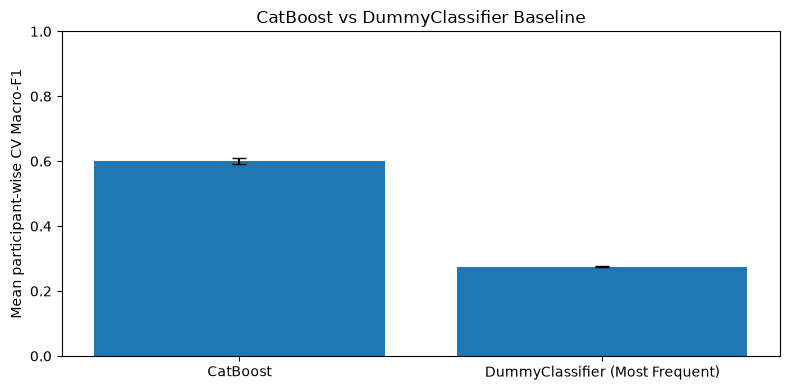


CatBoost classification report:
              precision    recall  f1-score   support

        Wake       0.46      0.52      0.49      1813
        NREM       0.83      0.78      0.81     15821
         REM       0.48      0.54      0.51      4953

    accuracy                           0.71     22587
   macro avg       0.59      0.61      0.60     22587
weighted avg       0.72      0.71      0.72     22587


CatBoost confusion matrix:


,Predicted Wake,Predicted NREM,Predicted REM
Actual Wake,936,587,290
Actual NREM,763,12408,2650
Actual REM,327,1939,2687


In [19]:

import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# =====================================================
# 1. PREPARE DATA
# =====================================================

TARGET = "sleep_stage"
SEED = 42
N_SPLITS = 4

df_train = data.copy()
df_train = df_train.dropna(subset=[TARGET]).copy()

y = df_train[TARGET].astype(int).to_numpy()
groups = df_train["participant_id"].to_numpy()

exclude_cols = [
    "sleep_stage", "participant_id", "person_id",
    "patient_id", "epoch", "timestamp", "seconds", "time"
]

X = df_train.drop(
    columns=[c for c in exclude_cols if c in df_train.columns]
)

X = X.select_dtypes(include=[np.number])
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")

# Identical participant-wise folds for both models
cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

folds = list(cv.split(X, y, groups=groups))

for i, (tr, va) in enumerate(folds, start=1):
    assert not (
        set(groups[tr]) & set(groups[va])
    ), f"Participant leakage in fold {i}"

print("Rows:", len(X))
print("Features:", X.shape[1])
print("Participants:", len(np.unique(groups)))
print("Classes:", np.unique(y))
print("Participant-wise folds verified.")

# =====================================================
# 2. LOAD CATBOOST BEST PARAMS FROM OPTUNA RESULTS
# =====================================================

best_params_df = pd.read_csv(
    "sleep_stage_optuna_best_params.csv"
)

catboost_rows = best_params_df.loc[
    best_params_df["model"].str.strip().str.lower()
    == "catboost",
    "best_params"
]

if catboost_rows.empty:
    raise ValueError(
        "CatBoost was not found in "
        "sleep_stage_optuna_best_params.csv"
    )

# Automatically use the saved best CatBoost parameters
catboost_params = ast.literal_eval(
    catboost_rows.iloc[-1]
)

print("\nCatBoost parameters loaded from Optuna:")
print(catboost_params)

# =====================================================
# 3. EVALUATE CATBOOST VS DUMMYCLASSIFIER
# =====================================================

model_names = [
    "CatBoost",
    "DummyClassifier (Most Frequent)"
]

results = []
oof_predictions = {}

for name in model_names:

    print(f"\nEvaluating: {name}")

    y_true_all = []
    y_pred_all = []
    fold_scores = []

    for fold_no, (train_idx, val_idx) in enumerate(
        folds, start=1
    ):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y[train_idx]
        y_val = y[val_idx]

        if name == "CatBoost":
            params = dict(catboost_params)

            # Remove runtime settings if they were saved
            # so they do not conflict with the settings below.
            params.pop("random_seed", None)
            params.pop("verbose", None)
            params.pop("thread_count", None)
            params.pop("allow_writing_files", None)

            params.setdefault("loss_function", "MultiClass")

            estimator = CatBoostClassifier(
                **params,
                random_seed=SEED,
                verbose=0,
                thread_count=4,
                allow_writing_files=False
            )

        else:
            estimator = DummyClassifier(
                strategy="most_frequent"
            )

        pipeline = Pipeline([
            ("model", estimator)
        ])

        pipeline.fit(X_train, y_train)

        pred = np.asarray(
            pipeline.predict(X_val)
        ).ravel().astype(int)

        score = f1_score(
            y_val,
            pred,
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)
        y_true_all.extend(y_val)
        y_pred_all.extend(pred)

        print(
            f"Fold {fold_no}: Macro-F1 = {score:.4f}"
        )

    results.append({
        "model": name,
        "mean_fold_macro_f1": np.mean(fold_scores),
        "std_fold_macro_f1": np.std(fold_scores),
        "pooled_oof_macro_f1": f1_score(
            y_true_all,
            y_pred_all,
            average="macro",
            zero_division=0
        ),
        "pooled_oof_accuracy": accuracy_score(
            y_true_all,
            y_pred_all
        )
    })

    oof_predictions[name] = (
        np.asarray(y_true_all),
        np.asarray(y_pred_all)
    )

# =====================================================
# 4. DISPLAY AND SAVE COMPARISON
# =====================================================

results_df = pd.DataFrame(results)

display(results_df.round(4))

results_df.to_csv(
    "catboost_vs_dummy_baseline.csv",
    index=False
)

print("\nSaved: catboost_vs_dummy_baseline.csv")

# =====================================================
# 5. PLOT COMPARISON
# =====================================================

plt.figure(figsize=(8, 4))

plt.bar(
    results_df["model"],
    results_df["mean_fold_macro_f1"],
    yerr=results_df["std_fold_macro_f1"],
    capsize=5
)

plt.ylabel("Mean participant-wise CV Macro-F1")
plt.title("CatBoost vs DummyClassifier Baseline")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# =====================================================
# 6. CATBOOST CLASSIFICATION REPORT
# =====================================================

y_true, y_pred = oof_predictions["CatBoost"]

print("\nCatBoost classification report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=["Wake", "NREM", "REM"],
        zero_division=0
    )
)

print("\nCatBoost confusion matrix:")

display(
    pd.DataFrame(
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1, 2]
        ),
        index=["Actual Wake", "Actual NREM", "Actual REM"],
        columns=[
            "Predicted Wake",
            "Predicted NREM",
            "Predicted REM"
        ]
    )
)


CatBoost best parameters:
{'iterations': 600, 'depth': 5, 'learning_rate': 0.005914960414922768, 'l2_leaf_reg': 0.05182708999820843, 'random_strength': 5.093559517915639, 'bagging_temperature': 1.7651773204642311, 'border_count': 64, 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42, 'verbose': 0, 'thread_count': 4, 'allow_writing_files': False}
Rows: 22587
Features: 24
Participants: 26

Original class counts:
0     1813
1    15821
2     4953
Name: count, dtype: int64
Fold 1: participant leakage check passed
Fold 2: participant leakage check passed
Fold 3: participant leakage check passed
Fold 4: participant leakage check passed

Method: Baseline

Fold 1 BEFORE: {0: 1386, 1: 11921, 2: 3618}
Fold 1 AFTER: {0: 1386, 1: 11921, 2: 3618}
Fold 1: Macro-F1 = 0.5974

Fold 2 BEFORE: {0: 1379, 1: 12048, 2: 3824}
Fold 2 AFTER: {0: 1379, 1: 12048, 2: 3824}
Fold 2: Macro-F1 = 0.6037

Fold 3 BEFORE: {0: 1292, 1: 11790, 2: 3836}
Fold 3 AFTER: {0: 1292, 1: 11790, 2: 3836}
Fold 3: Macro-F1 = 0.58

,method,mean_fold_macro_f1,std_fold_macro_f1,pooled_oof_macro_f1,pooled_oof_accuracy
0,Baseline,0.6008,0.0085,0.6008,0.7097
1,Partial SMOTE,0.5826,0.0184,0.5826,0.6673
2,Partial Random Oversampling,0.5817,0.0180,0.5817,0.6605



Saved: catboost_partial_resampling_comparison.csv

Baseline
              precision    recall  f1-score   support

        Wake       0.46      0.52      0.49      1813
        NREM       0.83      0.78      0.81     15821
         REM       0.48      0.54      0.51      4953

    accuracy                           0.71     22587
   macro avg       0.59      0.61      0.60     22587
weighted avg       0.72      0.71      0.72     22587

Confusion matrix:


,Predicted Wake,Predicted NREM,Predicted REM
Actual Wake,936,587,290
Actual NREM,763,12408,2650
Actual REM,327,1939,2687



Partial Random Oversampling
              precision    recall  f1-score   support

        Wake       0.37      0.63      0.46      1813
        NREM       0.88      0.66      0.76     15821
         REM       0.44      0.66      0.53      4953

    accuracy                           0.66     22587
   macro avg       0.56      0.65      0.58     22587
weighted avg       0.74      0.66      0.68     22587

Confusion matrix:


,Predicted Wake,Predicted NREM,Predicted REM
Actual Wake,1136,331,346
Actual NREM,1407,10504,3910
Actual REM,542,1132,3279



Partial SMOTE
              precision    recall  f1-score   support

        Wake       0.38      0.60      0.46      1813
        NREM       0.87      0.68      0.76     15821
         REM       0.44      0.64      0.52      4953

    accuracy                           0.67     22587
   macro avg       0.56      0.64      0.58     22587
weighted avg       0.73      0.67      0.69     22587

Confusion matrix:


,Predicted Wake,Predicted NREM,Predicted REM
Actual Wake,1083,387,343
Actual NREM,1290,10807,3724
Actual REM,504,1266,3183


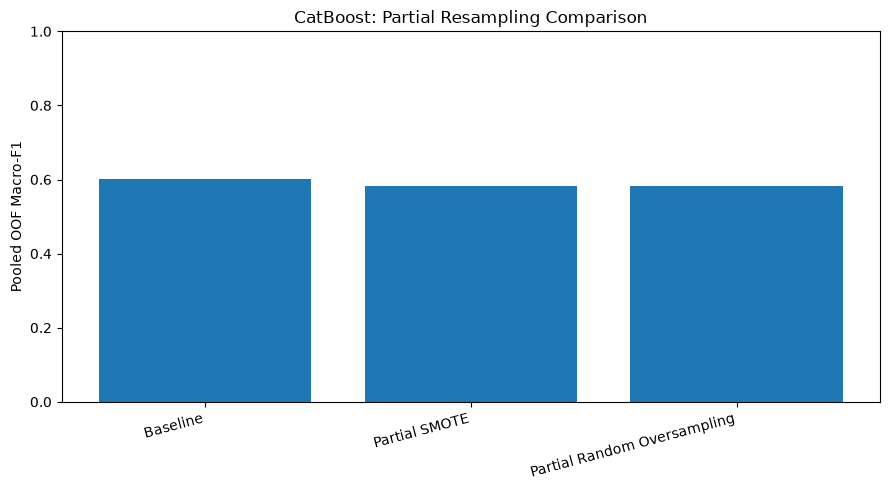

,Method,Wake F1,NREM F1,REM F1
0,Baseline,0.4876,0.8069,0.5079
1,Partial Random Oversampling,0.4639,0.7560,0.5251
2,Partial SMOTE,0.4618,0.7643,0.5217


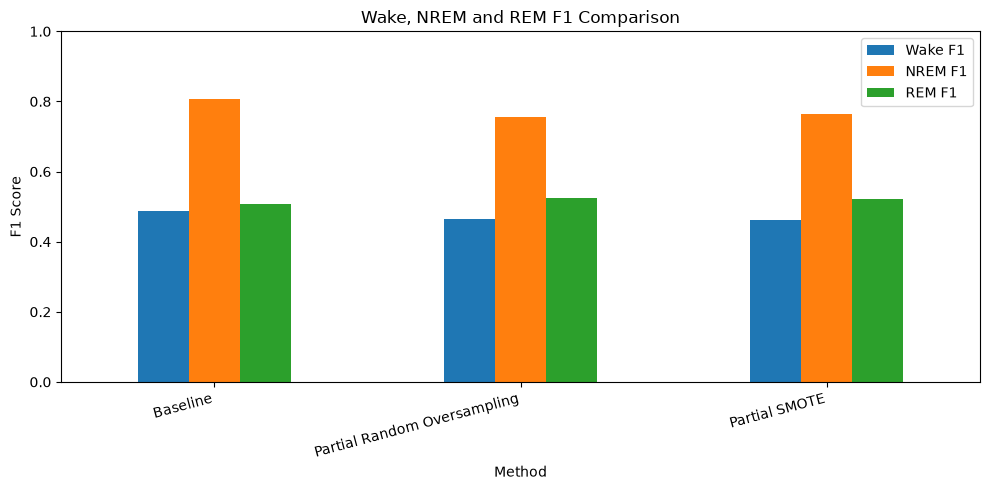

In [22]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import RandomOverSampler, SMOTE

# =====================================================
# 1. SETTINGS
# =====================================================

TARGET = "sleep_stage"
GROUP_COL = "participant_id"
SEED = 42
N_SPLITS = 4

# Load CatBoost's best parameters saved by Optuna
params_df = pd.read_csv("sleep_stage_optuna_best_params.csv")

catboost_row = params_df[
    params_df["model"].astype(str).str.strip().str.lower()
    == "catboost"
]

if catboost_row.empty:
    raise ValueError(
        "CatBoost parameters not found in "
        "sleep_stage_optuna_best_params.csv"
    )

BEST_PARAMS = ast.literal_eval(
    catboost_row.iloc[0]["best_params"]
)

# Set runtime parameters while preserving tuned parameters
for key in [
    "random_seed",
    "random_state",
    "verbose",
    "logging_level",
    "thread_count",
    "allow_writing_files"
]:
    BEST_PARAMS.pop(key, None)

BEST_PARAMS.update({
    "random_seed": SEED,
    "verbose": 0,
    "thread_count": 4,
    "allow_writing_files": False
})

print("CatBoost best parameters:")
print(BEST_PARAMS)

# Desired class counts AFTER resampling
# Class 0 = Wake, 1 = NREM, 2 = REM
SAMPLING_TARGET = {
    0: 5000,
    2: 7000
}

# =====================================================
# 2. PREPARE DATA
# =====================================================

df = data.dropna(subset=[TARGET, GROUP_COL]).copy()
df = df[df[TARGET].isin([0, 1, 2])].copy()
df[TARGET] = df[TARGET].astype(int)

exclude_cols = [
    TARGET, GROUP_COL, "person_id", "patient_id",
    "epoch", "timestamp", "seconds", "time"
]

FEATURES = [c for c in df.columns if c not in exclude_cols]

X = df[FEATURES].apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")
FEATURES = X.columns.tolist()

y = df[TARGET].to_numpy()
groups = df[GROUP_COL].to_numpy()

print("Rows:", len(df))
print("Features:", len(FEATURES))
print("Participants:", len(np.unique(groups)))
print("\nOriginal class counts:")
print(pd.Series(y).value_counts().sort_index())

# =====================================================
# 3. CREATE IDENTICAL GROUP FOLDS
# =====================================================

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

folds = list(cv.split(X, y, groups))

for fold, (tr_idx, va_idx) in enumerate(folds, start=1):
    assert set(groups[tr_idx]).isdisjoint(set(groups[va_idx]))
    print(f"Fold {fold}: participant leakage check passed")

# =====================================================
# 4. THREE METHODS
# =====================================================

methods = [
    "Baseline",
    "Partial Random Oversampling",
    "Partial SMOTE"
]

results = []
oof_predictions = {}

# =====================================================
# 5. TRAIN AND EVALUATE
# =====================================================

for method_name in methods:

    print("\n" + "=" * 65)
    print("Method:", method_name)

    oof_pred = np.full(len(df), -1, dtype=int)
    fold_scores = []

    for fold, (tr_idx, va_idx) in enumerate(folds, start=1):

        X_train = X.iloc[tr_idx]
        X_valid = X.iloc[va_idx]

        y_train = y[tr_idx]
        y_valid = y[va_idx]

        # Original training distribution
        print(
            f"\nFold {fold} BEFORE:",
            dict(sorted(
                pd.Series(y_train).value_counts().items()
            ))
        )

        # ---------------------------------------------
        # A. BASELINE: NO RESAMPLING
        # ---------------------------------------------

        if method_name == "Baseline":

            X_fit = X_train
            y_fit = y_train

        # ---------------------------------------------
        # B. PARTIAL RANDOM OVERSAMPLING
        # ---------------------------------------------

        elif method_name == "Partial Random Oversampling":

            sampler = RandomOverSampler(
                sampling_strategy=SAMPLING_TARGET,
                random_state=SEED
            )

            X_fit, y_fit = sampler.fit_resample(
                X_train, y_train
            )

        # ---------------------------------------------
        # C. PARTIAL SMOTE
        # IMPUTATION ADDED ONLY HERE
        # ---------------------------------------------

        elif method_name == "Partial SMOTE":

            # SMOTE target counts must exceed original
            # counts in each training fold.
            original_counts = pd.Series(y_train).value_counts()

            for cls, target_count in SAMPLING_TARGET.items():
                if target_count <= original_counts.get(cls, 0):
                    raise ValueError(
                        f"Fold {fold}: target count for class "
                        f"{cls} must exceed its original count. "
                        f"Current count: {original_counts.get(cls, 0)}, "
                        f"target: {target_count}"
                    )

            # Fit imputation values using training data only.
            # Median values that remain NaN (all-missing
            # training-fold features) are replaced with zero.
            train_medians = X_train.median().fillna(0)

            X_train_imputed = X_train.fillna(train_medians)

            # Safety check: SMOTE must not receive NaN or infinity.
            if not np.isfinite(
                X_train_imputed.to_numpy(dtype=float)
            ).all():
                raise ValueError(
                    f"Fold {fold}: non-finite values remain "
                    "in the SMOTE training features."
                )

            sampler = SMOTE(
                sampling_strategy=SAMPLING_TARGET,
                random_state=SEED,
                k_neighbors=5
            )

            X_fit, y_fit = sampler.fit_resample(
                X_train_imputed, y_train
            )

        print(
            f"Fold {fold} AFTER:",
            dict(sorted(
                pd.Series(y_fit).value_counts().items()
            ))
        )

        # ---------------------------------------------
        # FIT CATBOOST USING OPTUNA-BEST PARAMETERS
        # ---------------------------------------------

        model = CatBoostClassifier(**BEST_PARAMS)

        model.fit(X_fit, y_fit)

        # Validation data is NOT imputed here.
        # CatBoost handles its numerical NaN values natively.
        pred = np.asarray(
            model.predict(X_valid)
        ).reshape(-1).astype(int)

        oof_pred[va_idx] = pred

        score = f1_score(
            y_valid,
            pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)
        print(f"Fold {fold}: Macro-F1 = {score:.4f}")

    assert np.all(oof_pred >= 0)

    results.append({
        "method": method_name,
        "mean_fold_macro_f1": np.mean(fold_scores),
        "std_fold_macro_f1": np.std(fold_scores),
        "pooled_oof_macro_f1": f1_score(
            y, oof_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ),
        "pooled_oof_accuracy": accuracy_score(y, oof_pred)
    })

    oof_predictions[method_name] = oof_pred

# =====================================================
# 6. COMPARISON TABLE
# =====================================================

results_df = pd.DataFrame(results).sort_values(
    "pooled_oof_macro_f1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

results_df.to_csv(
    "catboost_partial_resampling_comparison.csv",
    index=False
)

print("\nSaved: catboost_partial_resampling_comparison.csv")

# =====================================================
# 7. CLASSIFICATION REPORTS
# =====================================================

for method_name, pred in oof_predictions.items():

    print("\n" + "=" * 65)
    print(method_name)

    print(classification_report(
        y,
        pred,
        labels=[0, 1, 2],
        target_names=["Wake", "NREM", "REM"],
        zero_division=0
    ))

    print("Confusion matrix:")

    display(pd.DataFrame(
        confusion_matrix(y, pred, labels=[0, 1, 2]),
        index=["Actual Wake", "Actual NREM", "Actual REM"],
        columns=[
            "Predicted Wake",
            "Predicted NREM",
            "Predicted REM"
        ]
    ))

# =====================================================
# 8. PLOT POOLED OOF MACRO-F1
# =====================================================

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["method"],
    results_df["pooled_oof_macro_f1"]
)

plt.ylabel("Pooled OOF Macro-F1")
plt.title("CatBoost: Partial Resampling Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# =====================================================
# 9. CLASS-WISE F1 COMPARISON
# =====================================================

class_results = []

for method_name, pred in oof_predictions.items():

    scores = f1_score(
        y,
        pred,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    class_results.append({
        "Method": method_name,
        "Wake F1": scores[0],
        "NREM F1": scores[1],
        "REM F1": scores[2]
    })

class_results_df = pd.DataFrame(class_results)
display(class_results_df.round(4))

class_results_df.set_index("Method").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("F1 Score")
plt.title("Wake, NREM and REM F1 Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [74]:
import ast
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import f_classif, mutual_info_classif

# ==========================================
# 1. Set your column names
# ==========================================
TARGET = "sleep_stage"
GROUP = "participant_id"

# ==========================================
# 2. Load CatBoost's best Optuna parameters
# ==========================================
params_df = pd.read_csv("sleep_stage_optuna_best_params.csv")

catboost_row = params_df[
    params_df["model"].astype(str).str.strip().str.lower() == "catboost"
]

if catboost_row.empty:
    raise ValueError(
        "CatBoost parameters not found in sleep_stage_optuna_best_params.csv"
    )

best_params = ast.literal_eval(catboost_row.iloc[0]["best_params"])

# Set runtime parameters without changing tuned hyperparameters
for key in [
    "random_seed",
    "random_state",
    "verbose",
    "logging_level",
    "thread_count",
    "allow_writing_files"
]:
    best_params.pop(key, None)

best_params.update({
    "random_seed": 42,
    "verbose": 0,
    "thread_count": 4,
    "allow_writing_files": False
})

print("CatBoost best parameters:")
print(best_params)

# ==========================================
# 3. Prepare features, labels and groups
# ==========================================
exclude_cols = [
    TARGET, GROUP, "person_id", "patient_id",
    "epoch", "timestamp", "seconds"
]

X = data.drop(
    columns=[c for c in exclude_cols if c in data.columns],
    errors="ignore"
)

X = X.select_dtypes(include=np.number)
X = X.replace([np.inf, -np.inf], np.nan)

y = data[TARGET]
groups = data[GROUP]

# Remove rows with missing labels or group IDs
valid = y.notna() & groups.notna()

X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)
groups = groups.loc[valid].reset_index(drop=True)

# ==========================================
# 4. Participant-wise cross-validation
# ==========================================
cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

permutation_results = []
anova_results = []
mi_results = []

# ==========================================
# 5. Calculate scores in each fold
# ==========================================
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # ======================================
    # 6. Train CatBoost WITHOUT imputation
    # ======================================
    # CatBoost supports numerical NaN values natively.
    model = CatBoostClassifier(**best_params)

    model.fit(X_train, y_train)

    # ======================================
    # 7. Permutation importance WITHOUT imputation
    # Validation data, Macro-F1
    # ======================================
    perm = permutation_importance(
        model,
        X_val,
        y_val,
        scoring="f1_macro",
        n_repeats=5,
        random_state=42,
        n_jobs=4
    )

    permutation_results.append(
        pd.DataFrame({
            "feature": X.columns,
            "score": perm.importances_mean,
            "fold": fold
        })
    )

    # ======================================
    # 8. Imputation ONLY for ANOVA and MI
    # Fit imputer on training fold only
    # ======================================
    imputer = SimpleImputer(strategy="median")

    X_train_imp = pd.DataFrame(
        imputer.fit_transform(X_train),
        columns=X.columns,
        index=X_train.index
    )

    # ======================================
    # 9. ANOVA F-score
    # Training data
    # ======================================
    f_scores, _ = f_classif(
        X_train_imp,
        y_train
    )

    anova_results.append(
        pd.DataFrame({
            "feature": X.columns,
            "score": f_scores,
            "fold": fold
        })
    )

    # ======================================
    # 10. Mutual information
    # Training data
    # ======================================
    mi_scores = mutual_info_classif(
        X_train_imp,
        y_train,
        discrete_features=False,
        random_state=42
    )

    mi_results.append(
        pd.DataFrame({
            "feature": X.columns,
            "score": mi_scores,
            "fold": fold
        })
    )

    print(f"Completed fold {fold}/4")

# ==========================================
# 11. Average scores across all folds
# ==========================================
permutation_mean = (
    pd.concat(permutation_results)
    .groupby("feature")["score"]
    .mean()
    .rename("permutation_mean")
)

anova_mean = (
    pd.concat(anova_results)
    .groupby("feature")["score"]
    .mean()
    .rename("anova_F_mean")
)

mi_mean = (
    pd.concat(mi_results)
    .groupby("feature")["score"]
    .mean()
    .rename("mutual_information_mean")
)

# ==========================================
# 12. Display ONLY the three scores
# ==========================================
scores_only = pd.concat(
    [permutation_mean, anova_mean, mi_mean],
    axis=1
).reset_index(names="feature")

scores_only = scores_only.sort_values(
    "permutation_mean",
    ascending=False
)

print("\nFeature importance scores:\n")
print(scores_only.to_string(index=False))

# Save results
scores_only.to_csv(
    "scores_only.csv",
    index=False
)

print("\nSaved as scores_only.csv")

CatBoost best parameters:
{'iterations': 600, 'depth': 5, 'learning_rate': 0.005914960414922768, 'l2_leaf_reg': 0.05182708999820843, 'random_strength': 5.093559517915639, 'bagging_temperature': 1.7651773204642311, 'border_count': 64, 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42, 'verbose': 0, 'thread_count': 4, 'allow_writing_files': False}
Completed fold 1/4
Completed fold 2/4
Completed fold 3/4
Completed fold 4/4

Feature importance scores:

              feature  permutation_mean  anova_F_mean  mutual_information_mean
 acc_rolling_std_5min          0.042314   2126.658265                 0.125408
  hr_rolling_std_5min          0.039083    697.280374                 0.133503
        hr_range_5min          0.028255    702.791730                 0.238943
  hr_rolling_std_2min          0.025056    560.878719                 0.099441
 acc_rolling_std_2min          0.005602   1831.214609                 0.098796
            acc_z_std          0.002402   1025.555789              

Loaded saved best CatBoost parameters:
{'iterations': 600, 'depth': 5, 'learning_rate': 0.005914960414922768, 'l2_leaf_reg': 0.05182708999820843, 'random_strength': 5.093559517915639, 'bagging_temperature': 1.7651773204642311, 'border_count': 64, 'auto_class_weights': 'SqrtBalanced', 'loss_function': 'MultiClass', 'random_seed': 42, 'thread_count': 2, 'verbose': False, 'allow_writing_files': False}

Rows: 20121
Participants: 26
Features: 24

Class counts:
sleep_stage
Wake     1719
NREM    13370
REM      5032
Name: count, dtype: int64

Missing values per feature:
hr_rolling_std_5min      53
hr_range_5min            53
acc_rolling_mean_5min    51
acc_rolling_std_5min     51
hr_rolling_std_2min      30
hr_change_abs            30
hr_rolling_mean_2min     30
motion_lag1              26
acc_rolling_mean_2min    26
acc_rolling_std_2min     26
dtype: int64

========== FOLD 1/4 ==========
Fold Macro-F1: 0.5811
Fold Accuracy: 0.6711
SHAP calculated for 100 validation rows.

========== FOLD 2/4 

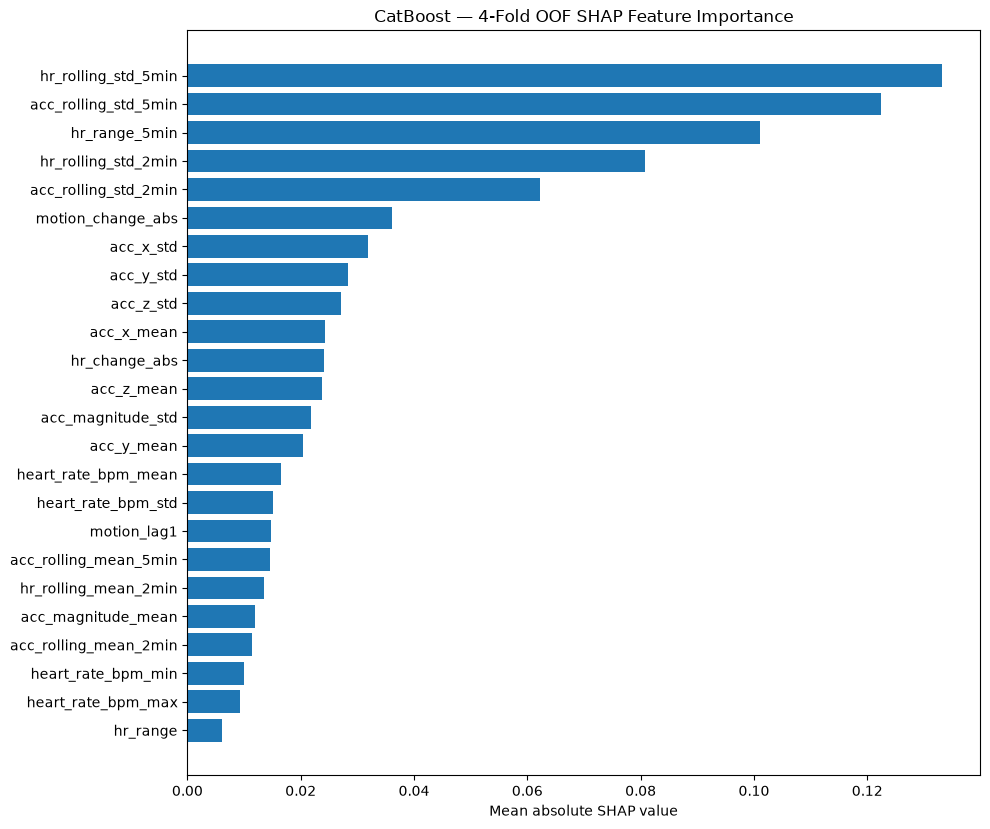


Finished. Only the SHAP feature-importance graph was displayed.


In [75]:
# ============================================================
# CATBOOST OOF + SHAP FEATURE IMPORTANCE
# 4-fold participant-wise validation
# Memory-conscious for 16 GB RAM
# ONE GRAPH ONLY — NO FILES SAVED
# Uses saved best CatBoost Optuna parameters
# NO IMPUTATION
# ============================================================

import ast
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, accuracy_score

warnings.filterwarnings("ignore")

# ---------------- SETTINGS ----------------

TARGET = "sleep_stage"
N_SPLITS = 4
RANDOM_SEED = 42
SHAP_SAMPLE_SIZE = 100

LABELS = [0, 1, 2]
CLASS_NAMES = ["Wake", "NREM", "REM"]

# ---------------- LOAD SAVED BEST CATBOOST PARAMETERS ----------------

params_df = pd.read_csv("sleep_stage_optuna_best_params.csv")

catboost_row = params_df[
    params_df["model"].astype(str).str.strip().str.lower()
    == "catboost"
]

if catboost_row.empty:
    raise ValueError(
        "CatBoost parameters not found in "
        "sleep_stage_optuna_best_params.csv"
    )

BEST_PARAMS = ast.literal_eval(
    catboost_row.iloc[0]["best_params"]
)

# Remove runtime settings so they can be set consistently below.
for key in [
    "random_seed",
    "random_state",
    "verbose",
    "logging_level",
    "thread_count",
    "allow_writing_files"
]:
    BEST_PARAMS.pop(key, None)

BEST_PARAMS.update({
    "loss_function": "MultiClass",
    "random_seed": RANDOM_SEED,
    "thread_count": 2,
    "verbose": False,
    "allow_writing_files": False
})

print("Loaded saved best CatBoost parameters:")
print(BEST_PARAMS)

# ---------------- CHECK DATA ----------------

if "data" not in globals() or not isinstance(data, pd.DataFrame):
    raise ValueError("Load your combined dataframe as 'data' first.")

if TARGET not in data.columns:
    raise ValueError(f"'{TARGET}' not found in data.")

GROUP_CANDIDATES = [
    "participant_id",
    "person_id",
    "patient_id"
]

GROUP_COL = next(
    (c for c in GROUP_CANDIDATES if c in data.columns),
    None
)

if GROUP_COL is None:
    raise ValueError(
        "No participant ID column found. Expected participant_id, "
        "person_id, or patient_id."
    )

df = data.dropna(
    subset=[TARGET, GROUP_COL]
).reset_index(drop=True)

EXCLUDE_EXACT = {
    TARGET,
    "participant_id",
    "person_id",
    "patient_id",
    "epoch",
    "timestamp",
    "seconds",
    "time",
    "id"
}

feature_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in EXCLUDE_EXACT
    and "timestamp" not in c.lower()
    and "datetime" not in c.lower()
]

if not feature_cols:
    raise ValueError("No numeric feature columns found.")

# Keep NaNs. Replace only positive and negative infinity with NaN.
X = (
    df[feature_cols]
    .replace([np.inf, -np.inf], np.nan)
    .astype(np.float32)
)

y = df[TARGET].astype(int)
groups = df[GROUP_COL]

if set(y.unique()) - set(LABELS):
    raise ValueError(
        f"Expected target labels {LABELS}; found "
        f"{sorted(y.unique().tolist())}."
    )

if groups.nunique() < N_SPLITS:
    raise ValueError(
        f"Need at least {N_SPLITS} unique participants; "
        f"found {groups.nunique()}."
    )

print("\nRows:", len(df))
print("Participants:", groups.nunique())
print("Features:", len(feature_cols))
print("\nClass counts:")

print(
    y.value_counts()
    .sort_index()
    .rename(index=dict(enumerate(CLASS_NAMES)))
)

print("\nMissing values per feature:")
print(X.isna().sum().sort_values(ascending=False).head(10))

# ---------------- 4-FOLD OOF + SHAP ----------------

cv = GroupKFold(n_splits=N_SPLITS)

oof_pred = np.full(len(df), -1, dtype=np.int8)
fold_scores = []
shap_importance_by_fold = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups), start=1
):
    print(f"\n========== FOLD {fold}/{N_SPLITS} ==========")

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    # ======================================
    # Train CatBoost WITHOUT IMPUTATION
    # CatBoost handles numerical NaNs natively.
    # ======================================

    model = CatBoostClassifier(**BEST_PARAMS)

    model.fit(
        X_train,
        y_train,
        verbose=False
    )

    # ======================================
    # OOF predictions
    # ======================================

    pred = model.predict(X_valid).reshape(-1).astype(int)

    oof_pred[valid_idx] = pred

    fold_f1 = f1_score(
        y_valid,
        pred,
        labels=LABELS,
        average="macro",
        zero_division=0
    )

    fold_acc = accuracy_score(y_valid, pred)
    fold_scores.append(fold_f1)

    print(f"Fold Macro-F1: {fold_f1:.4f}")
    print(f"Fold Accuracy: {fold_acc:.4f}")

    # ======================================
    # LOW-MEMORY SHAP
    # No imputation
    # ======================================

    sample_n = min(SHAP_SAMPLE_SIZE, len(X_valid))

    rng = np.random.default_rng(RANDOM_SEED + fold)

    sample_positions = rng.choice(
        len(X_valid),
        size=sample_n,
        replace=False
    )

    X_shap = X_valid.iloc[sample_positions]

    # Pool can contain numerical NaN values.
    shap_pool = Pool(X_shap)

    shap_raw = model.get_feature_importance(
        data=shap_pool,
        type="ShapValues",
        thread_count=2
    )

    shap_raw = np.asarray(shap_raw)

    # Support common CatBoost SHAP layouts:
    # (samples, features + 1, classes)
    # (samples, classes, features + 1)
    # and 2D single-output SHAP.

    if shap_raw.ndim == 2:

        shap_features = shap_raw[:, :-1]

        if shap_features.shape[1] != len(feature_cols):
            raise ValueError(
                f"SHAP shape {shap_raw.shape} does not match "
                f"{len(feature_cols)} input features."
            )

        fold_importance = np.abs(
            shap_features
        ).mean(axis=0)

    elif shap_raw.ndim == 3:

        if shap_raw.shape[1] == len(feature_cols) + 1:

            # (samples, features + 1, classes)
            shap_features = shap_raw[:, :-1, :]

            fold_importance = np.abs(
                shap_features
            ).mean(axis=(0, 2))

        elif shap_raw.shape[2] == len(feature_cols) + 1:

            # (samples, classes, features + 1)
            shap_features = shap_raw[:, :, :-1]

            fold_importance = np.abs(
                shap_features
            ).mean(axis=(0, 1))

        else:
            raise ValueError(
                f"Unexpected SHAP shape {shap_raw.shape}; "
                f"expected {len(feature_cols)} features."
            )

    else:
        raise ValueError(
            f"Unexpected SHAP dimensions: {shap_raw.shape}"
        )

    if len(fold_importance) != len(feature_cols):
        raise ValueError(
            f"SHAP returned {len(fold_importance)} importance values "
            f"for {len(feature_cols)} features."
        )

    shap_importance_by_fold.append(fold_importance)

    print(
        f"SHAP calculated for {sample_n} validation rows."
    )

    del model, X_train, X_valid, y_train, y_valid
    del pred, X_shap, shap_pool, shap_raw, shap_features

    gc.collect()

# ---------------- OVERALL OOF RESULTS ----------------

if np.any(oof_pred < 0):
    raise RuntimeError(
        "Some rows did not receive OOF predictions."
    )

overall_f1 = f1_score(
    y,
    oof_pred,
    labels=LABELS,
    average="macro",
    zero_division=0
)

overall_acc = accuracy_score(y, oof_pred)

print("\n========== OVERALL OOF RESULTS ==========")
print(f"OOF Macro-F1: {overall_f1:.4f}")
print(f"OOF Accuracy: {overall_acc:.4f}")
print(f"Mean fold Macro-F1: {np.mean(fold_scores):.4f}")

# ---------------- ONLY SHAP FEATURE-IMPORTANCE GRAPH ----------------

mean_shap_importance = np.mean(
    np.vstack(shap_importance_by_fold),
    axis=0
)

shap_imp_df = pd.DataFrame({
    "feature": feature_cols,
    "mean_abs_shap": mean_shap_importance
}).sort_values(
    "mean_abs_shap",
    ascending=False
)

top_n = min(25, len(shap_imp_df))

plot_df = shap_imp_df.head(top_n).sort_values(
    "mean_abs_shap",
    ascending=True
)

fig, ax = plt.subplots(
    figsize=(10, max(5, 0.35 * top_n))
)

ax.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"]
)

ax.set_xlabel("Mean absolute SHAP value")
ax.set_title(
    "CatBoost — 4-Fold OOF SHAP Feature Importance"
)

fig.tight_layout()

plt.show()  # Display only; no image or data is saved.
plt.close(fig)

del X, df, groups, y, oof_pred
gc.collect()

print(
    "\nFinished. Only the SHAP feature-importance graph was displayed."
)


CatBoost best parameters loaded from Optuna:
{'iterations': 600, 'depth': 5, 'learning_rate': 0.005914960414922768, 'l2_leaf_reg': 0.05182708999820843, 'random_strength': 5.093559517915639, 'bagging_temperature': 1.7651773204642311, 'border_count': 64, 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42, 'verbose': 0, 'thread_count': 4, 'allow_writing_files': False}
Rows: 20121
Participants: 26
Number of features: 24
Features: ['heart_rate_bpm_mean', 'heart_rate_bpm_min', 'heart_rate_bpm_max', 'heart_rate_bpm_std', 'acc_x_mean', 'acc_x_std', 'acc_y_mean', 'acc_y_std', 'acc_z_mean', 'acc_z_std', 'acc_magnitude_mean', 'acc_magnitude_std', 'motion_lag1', 'hr_rolling_std_5min', 'hr_range_5min', 'hr_range', 'hr_rolling_mean_2min', 'hr_rolling_std_2min', 'acc_rolling_std_5min', 'acc_rolling_mean_5min', 'acc_rolling_std_2min', 'acc_rolling_mean_2min', 'hr_change_abs', 'motion_change_abs']

Class counts:
sleep_stage
0     1719
1    13370
2     5032
Name: count, dtype: int64

Training fold 

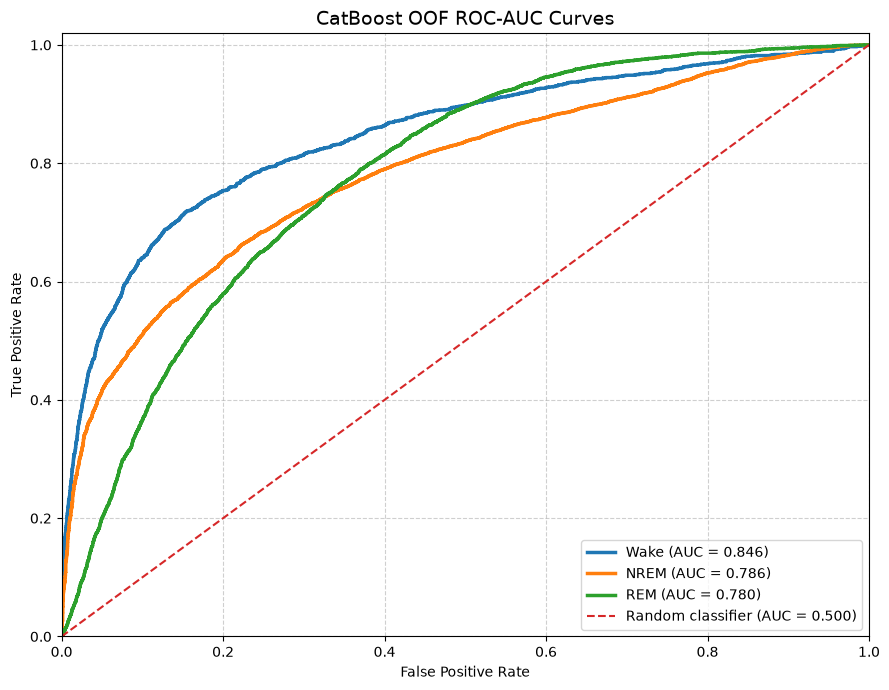


ROC-AUC scores:
sleep_stage  roc_auc
       Wake 0.846410
       NREM 0.785506
        REM 0.779963


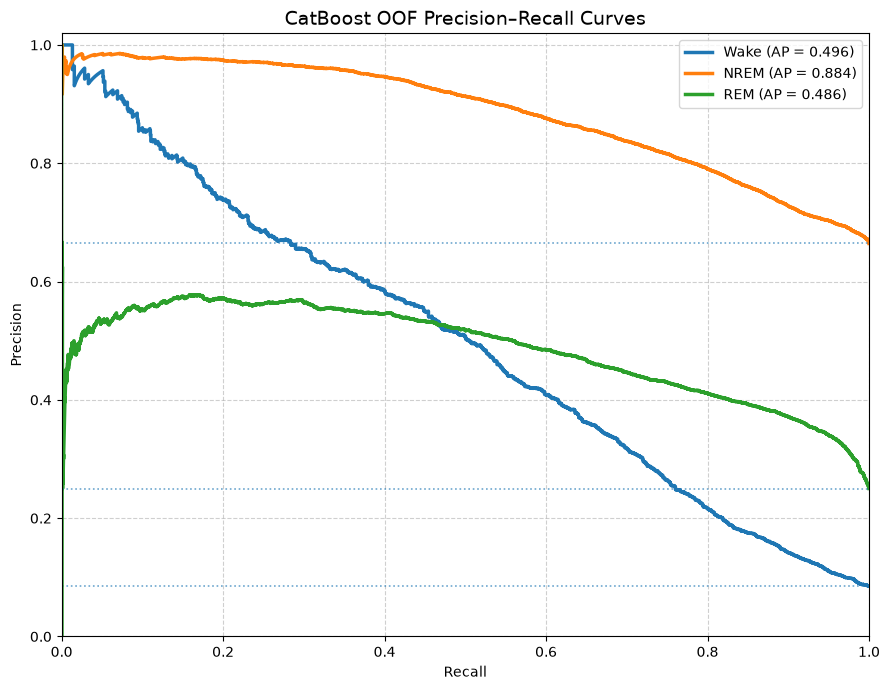


Precision–Recall scores:
sleep_stage  average_precision  positive_class_prevalence
       Wake           0.495786                   0.085433
       NREM           0.884213                   0.664480
        REM           0.485777                   0.250087

Overall macro one-vs-rest ROC-AUC: 0.8040

All files saved in: catboost_oof_results


In [76]:
# ============================================================
# CATBOOST: OOF ROC-AUC + PRECISION-RECALL CURVES
# 4-fold StratifiedGroupKFold
# No external test dataframes
# Classes: 0 = Wake, 1 = NREM, 2 = REM
# Uses saved best CatBoost Optuna parameters
# NO IMPUTATION
# ============================================================

import os
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

RANDOM_SEED = 42
N_SPLITS = 4

OUTPUT_DIR = "catboost_oof_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_LABELS = {
    0: "Wake",
    1: "NREM",
    2: "REM"
}

CLASSES = [0, 1, 2]

# ------------------------------------------------------------
# 2. LOAD CATBOOST'S BEST OPTUNA PARAMETERS
# ------------------------------------------------------------

params_df = pd.read_csv("sleep_stage_optuna_best_params.csv")

catboost_row = params_df[
    params_df["model"].astype(str).str.strip().str.lower()
    == "catboost"
]

if catboost_row.empty:
    raise ValueError(
        "CatBoost parameters not found in "
        "sleep_stage_optuna_best_params.csv"
    )

BEST_PARAMS = ast.literal_eval(
    catboost_row.iloc[0]["best_params"]
)

# Set runtime parameters without changing tuned hyperparameters
for key in [
    "random_seed",
    "random_state",
    "verbose",
    "logging_level",
    "thread_count",
    "allow_writing_files"
]:
    BEST_PARAMS.pop(key, None)

BEST_PARAMS.update({
    "random_seed": RANDOM_SEED,
    "verbose": 0,
    "thread_count": 4,
    "allow_writing_files": False
})

print("CatBoost best parameters loaded from Optuna:")
print(BEST_PARAMS)

# ------------------------------------------------------------
# 3. DATA AND FEATURE SELECTION
# ------------------------------------------------------------

# Uses your existing combined dataframe
df = data.copy()

TARGET = "sleep_stage"

group_candidates = [
    "participant_id",
    "person_id",
    "patient_id"
]

GROUP_COL = next(
    (col for col in group_candidates if col in df.columns),
    None
)

if GROUP_COL is None:
    raise ValueError(
        "No participant/group column found. "
        "Expected participant_id, person_id, or patient_id."
    )

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found.")

# Exclude identifiers, timestamps, and target from features
exclude_cols = {
    TARGET,
    "participant_id",
    "person_id",
    "patient_id",
    "epoch",
    "timestamp",
    "seconds",
    "time"
}

# Use eligible numeric features from your combined dataframe
feature_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in exclude_cols
]

# Keep only rows with known labels and participant IDs
df = df.dropna(subset=[TARGET, GROUP_COL]).copy()

X = (
    df[feature_cols]
    .replace([np.inf, -np.inf], np.nan)
    .reset_index(drop=True)
)

y = df[TARGET].astype(int).reset_index(drop=True)
groups = df[GROUP_COL].reset_index(drop=True)

if set(y.unique()) != set(CLASSES):
    raise ValueError(
        f"Expected labels {CLASSES}, but found {sorted(y.unique())}"
    )

print("Rows:", len(df))
print("Participants:", groups.nunique())
print("Number of features:", len(feature_cols))
print("Features:", feature_cols)
print("\nClass counts:")
print(y.value_counts().sort_index())

# ------------------------------------------------------------
# 4. CATBOOST MODEL
# No imputation: CatBoost handles numerical NaNs natively
# ------------------------------------------------------------

model = CatBoostClassifier(**BEST_PARAMS)

# ------------------------------------------------------------
# 5. GENERATE OUT-OF-FOLD PROBABILITIES
# ------------------------------------------------------------

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_SEED
)

# Each row receives probabilities from its held-out fold
oof_proba = np.full((len(X), len(CLASSES)), np.nan)
oof_fold = np.full(len(X), -1)

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    print(f"\nTraining fold {fold}/{N_SPLITS}")

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    groups_train = groups.iloc[train_idx]
    groups_valid = groups.iloc[valid_idx]

    # Safety check: no participant occurs in both sets
    assert set(groups_train).isdisjoint(set(groups_valid))

    # Train directly on original features, including NaNs
    model = CatBoostClassifier(**BEST_PARAMS)
    model.fit(X_train, y_train)

    fold_probs = model.predict_proba(X_valid)

    # Align probabilities to the fixed class order [0, 1, 2]
    for j, class_id in enumerate(model.classes_):
        oof_proba[valid_idx, int(class_id)] = fold_probs[:, j]

    oof_fold[valid_idx] = fold

    print("Training rows:", len(train_idx))
    print("Validation rows:", len(valid_idx))

# ------------------------------------------------------------
# 6. VALID OOF ROWS
# ------------------------------------------------------------

valid_mask = (
    np.isfinite(oof_proba).all(axis=1)
    & (oof_fold >= 0)
)

y_true = y.to_numpy()[valid_mask]
oof_proba_valid = oof_proba[valid_mask]
fold_valid = oof_fold[valid_mask]

if len(y_true) == 0:
    raise ValueError("No valid OOF predictions were generated.")

print("\nValid OOF predictions:", len(y_true))

# Save OOF probabilities for future analysis
oof_df = pd.DataFrame({
    "actual_sleep_stage": y_true,
    "predicted_sleep_stage": np.array(CLASSES)[
        np.argmax(oof_proba_valid, axis=1)
    ],
    "oof_fold": fold_valid
})

for j, name in enumerate(["Wake", "NREM", "REM"]):
    oof_df[f"probability_{name.lower()}"] = oof_proba_valid[:, j]

oof_df.to_csv(
    os.path.join(OUTPUT_DIR, "catboost_oof_predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 7. ROC-AUC CURVE: ONE CURVE PER SLEEP STAGE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))
roc_scores = []

for class_id in CLASSES:
    class_name = CLASS_LABELS[class_id]

    # One-vs-rest: current class is positive, others negative
    y_binary = (y_true == class_id).astype(int)
    class_probs = oof_proba_valid[:, class_id]

    fpr, tpr, thresholds = roc_curve(y_binary, class_probs)
    class_auc = auc(fpr, tpr)

    roc_scores.append({
        "sleep_stage": class_name,
        "roc_auc": class_auc
    })

    ax.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

# Random-ranking reference line
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier (AUC = 0.500)"
)

ax.set_title("CatBoost OOF ROC-AUC Curves", fontsize=14)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "catboost_oof_roc_auc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

pd.DataFrame(roc_scores).to_csv(
    os.path.join(OUTPUT_DIR, "catboost_oof_roc_auc_scores.csv"),
    index=False
)

print("\nROC-AUC scores:")
print(pd.DataFrame(roc_scores).to_string(index=False))

# ------------------------------------------------------------
# 8. PRECISION-RECALL CURVE: ONE CURVE PER SLEEP STAGE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))
pr_scores = []

for class_id in CLASSES:
    class_name = CLASS_LABELS[class_id]

    # One-vs-rest for each sleep stage
    y_binary = (y_true == class_id).astype(int)
    class_probs = oof_proba_valid[:, class_id]

    precision, recall, thresholds = precision_recall_curve(
        y_binary,
        class_probs
    )

    ap = average_precision_score(y_binary, class_probs)

    # Baseline precision equals the proportion of this class
    baseline = y_binary.mean()

    pr_scores.append({
        "sleep_stage": class_name,
        "average_precision": ap,
        "positive_class_prevalence": baseline
    })

    ax.plot(
        recall,
        precision,
        linewidth=2.5,
        label=f"{class_name} (AP = {ap:.3f})"
    )

    # Class-specific baseline
    ax.axhline(
        baseline,
        linestyle=":",
        linewidth=1.2,
        alpha=0.65
    )

ax.set_title(
    "CatBoost OOF Precision–Recall Curves",
    fontsize=14
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="best")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "catboost_oof_precision_recall_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

pd.DataFrame(pr_scores).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "catboost_oof_precision_recall_scores.csv"
    ),
    index=False
)

print("\nPrecision–Recall scores:")
print(pd.DataFrame(pr_scores).to_string(index=False))

# ------------------------------------------------------------
# 9. OVERALL MULTICLASS ROC-AUC
# ------------------------------------------------------------

overall_auc = roc_auc_score(
    y_true,
    oof_proba_valid,
    labels=CLASSES,
    multi_class="ovr",
    average="macro"
)

print(f"\nOverall macro one-vs-rest ROC-AUC: {overall_auc:.4f}")
print(f"\nAll files saved in: {OUTPUT_DIR}")

Loaded best parameters from: C:\Users\Himanshu kumar\sleep_stage_optuna_best_params.csv

Using saved CatBoost parameters:
{'iterations': 600, 'depth': 5, 'learning_rate': 0.005914960414922768, 'l2_leaf_reg': 0.05182708999820843, 'random_strength': 5.093559517915639, 'bagging_temperature': 1.7651773204642311, 'border_count': 64, 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42, 'verbose': 0, 'thread_count': 4, 'allow_writing_files': False}

Participant grouping column: participant_id
df6: 947 labelled rows; classes = [0, 1, 2]
df8: 475 labelled rows; classes = [0, 1, 2]
df19: 953 labelled rows; classes = [0, 1, 2]
df21: 510 labelled rows; classes = [0, 1, 2]
df23: 954 labelled rows; classes = [0, 1, 2]
df26: 948 labelled rows; classes = [0, 1, 2]
df29: 952 labelled rows; classes = [0, 1, 2]

Training participants: 23
Training rows: 19,733
Test participants are excluded from training.

Number of features: 24

Training class distribution:
sleep_stage
0     1610
1    13908
2     421

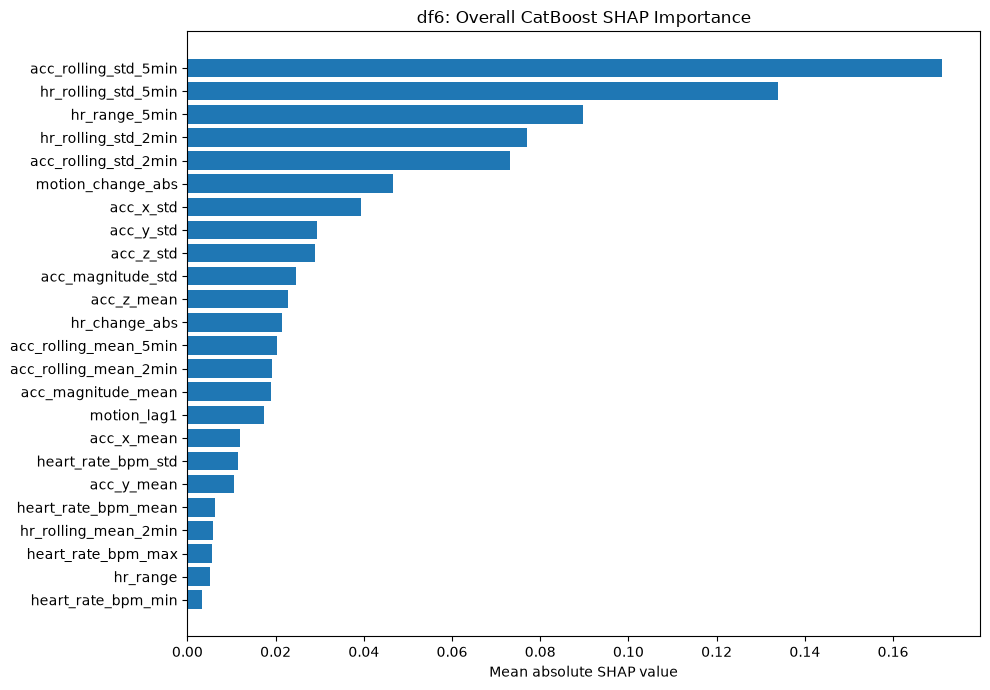

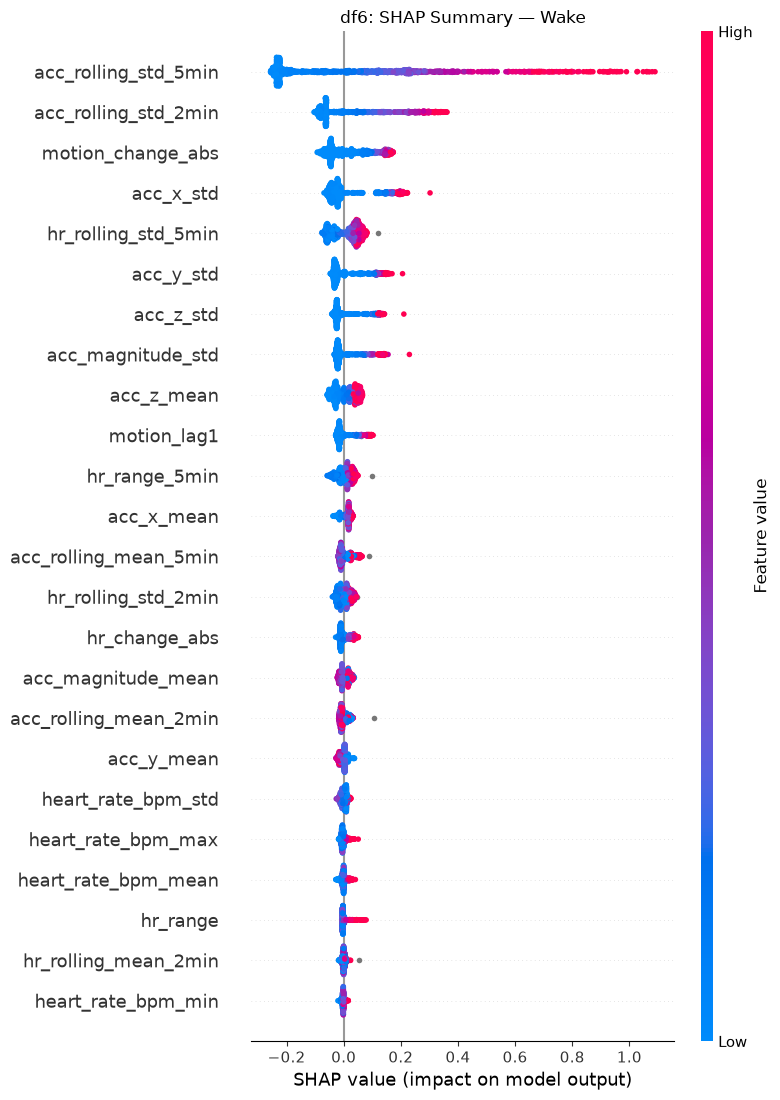

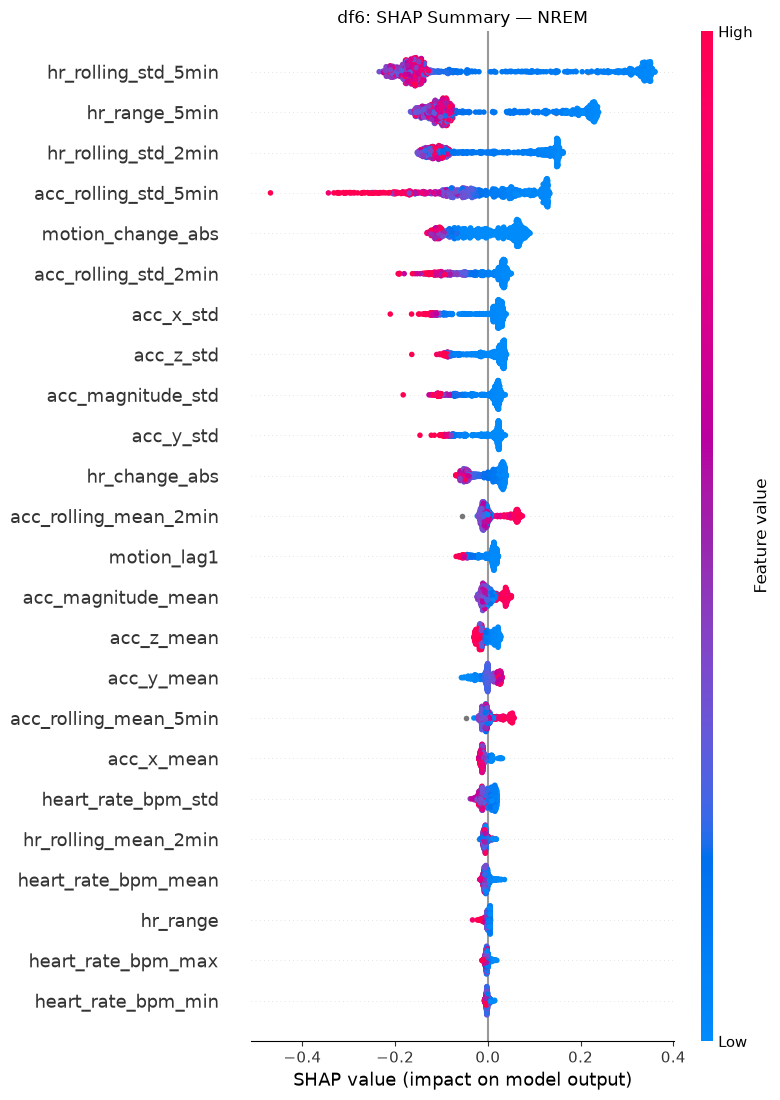

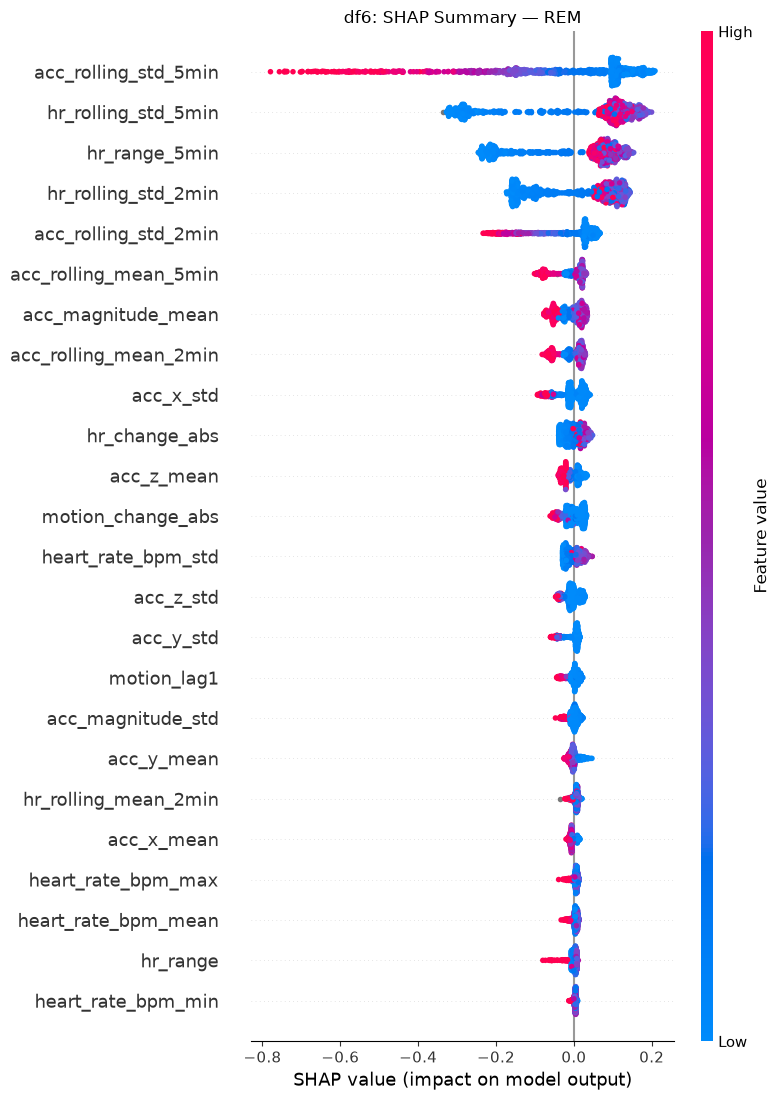

Finished predictions and SHAP for df6.

###########################################################################
CATBOOST EVALUATION: df8
###########################################################################

Classification report — df8
              precision    recall  f1-score   support

        Wake     0.3721    0.8889    0.5246        18
        NREM     0.8295    0.8547    0.8419       296
         REM     0.7402    0.5839    0.6528       161

    accuracy                         0.7642       475
   macro avg     0.6473    0.7758    0.6731       475
weighted avg     0.7819    0.7642    0.7658       475


Confusion matrix — df8
             Predicted_Wake  Predicted_NREM  Predicted_REM
Actual_Wake              16               1              1
Actual_NREM              11             253             32
Actual_REM               16              51             94
Calculating SHAP for 475 rows from df8.


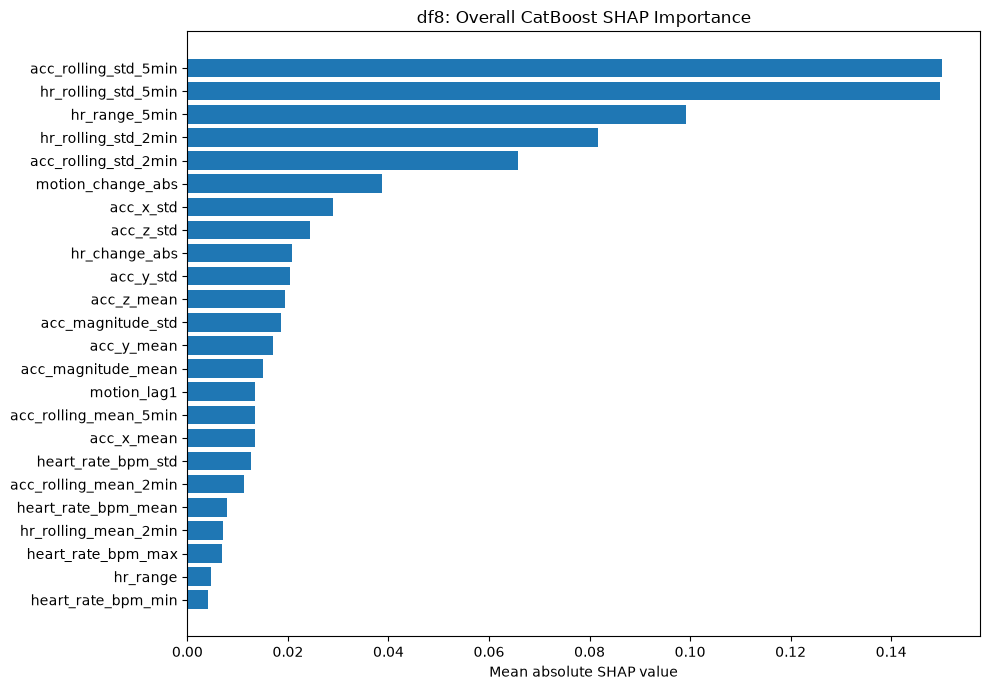

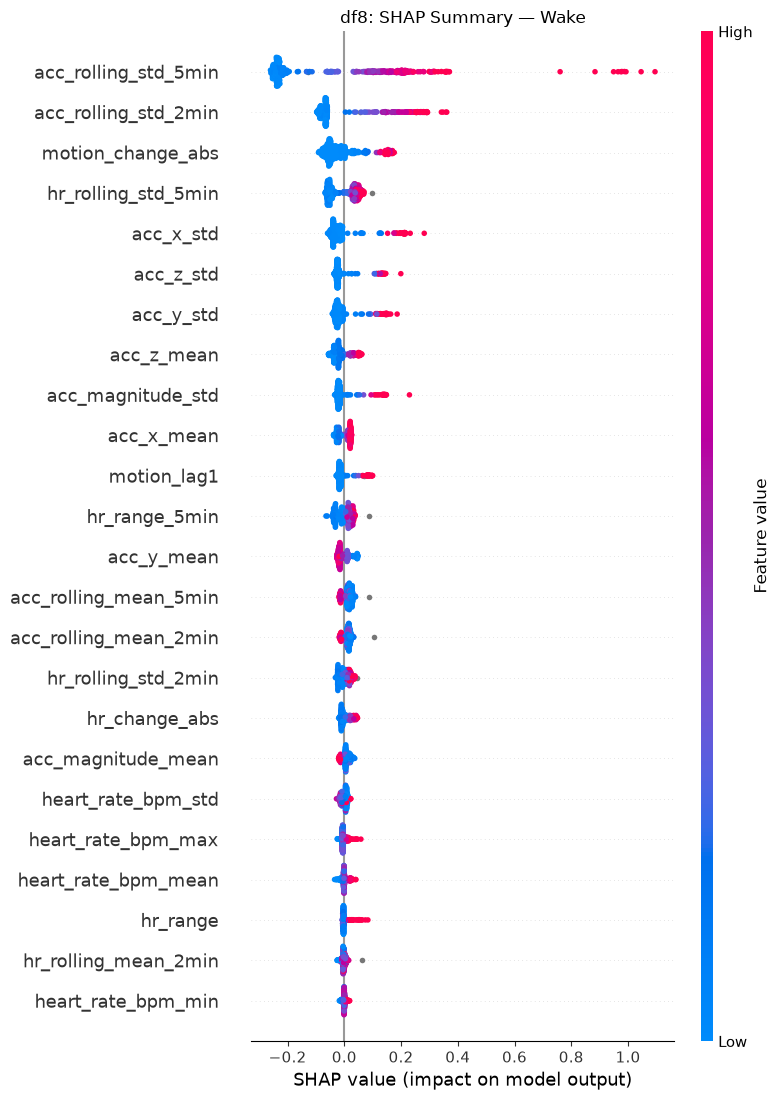

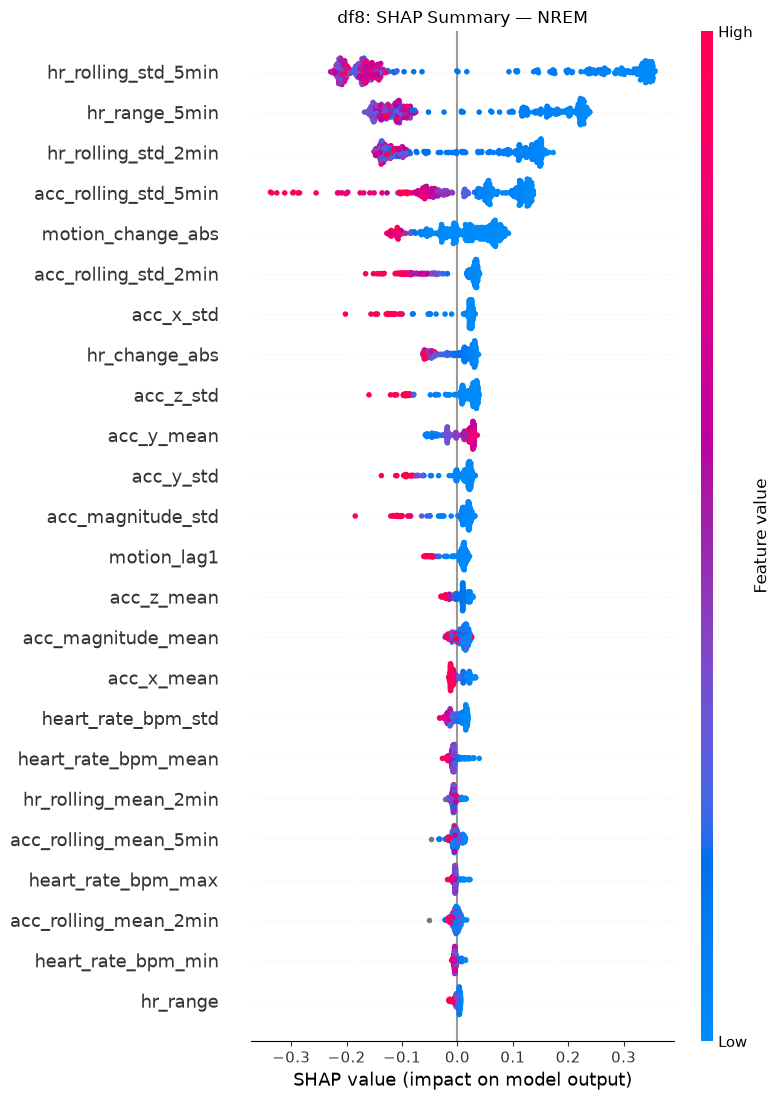

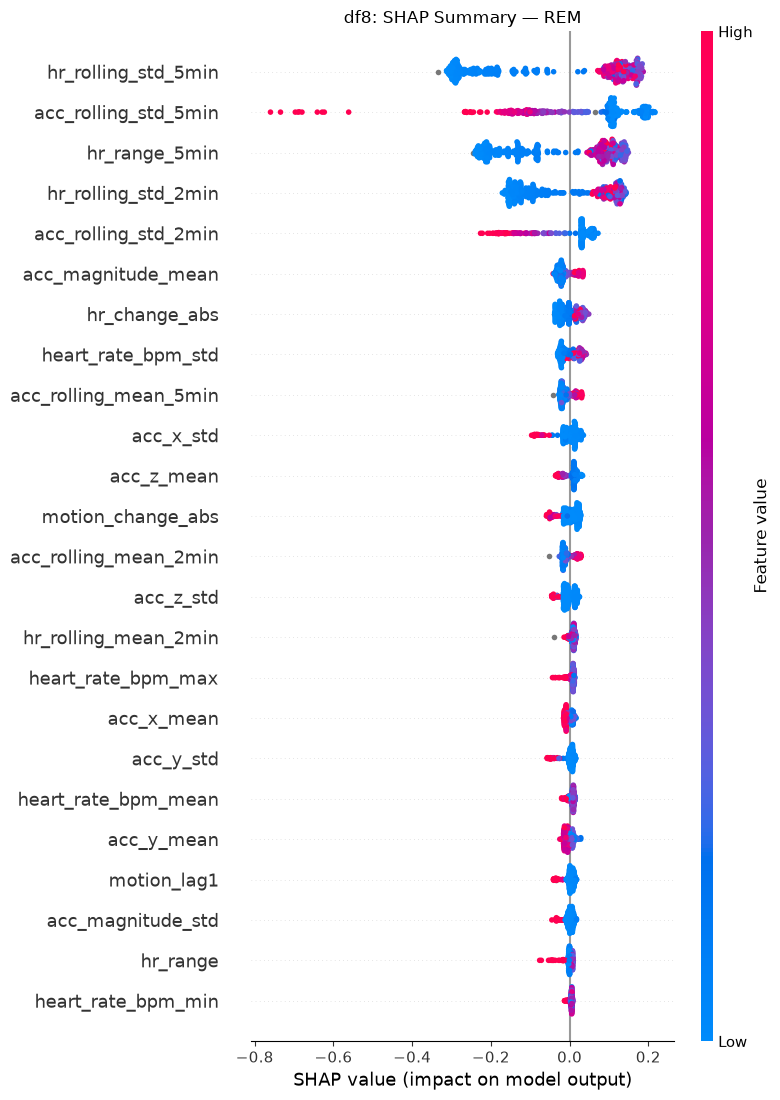

Finished predictions and SHAP for df8.

###########################################################################
CATBOOST EVALUATION: df19
###########################################################################

Classification report — df19
              precision    recall  f1-score   support

        Wake     0.4741    0.5238    0.4977       105
        NREM     0.8113    0.8958    0.8515       624
         REM     0.6824    0.4509    0.5430       224

    accuracy                         0.7503       953
   macro avg     0.6560    0.6235    0.6307       953
weighted avg     0.7439    0.7503    0.7400       953


Confusion matrix — df19
             Predicted_Wake  Predicted_NREM  Predicted_REM
Actual_Wake              55              45              5
Actual_NREM              23             559             42
Actual_REM               38              85            101
Calculating SHAP for 953 rows from df19.


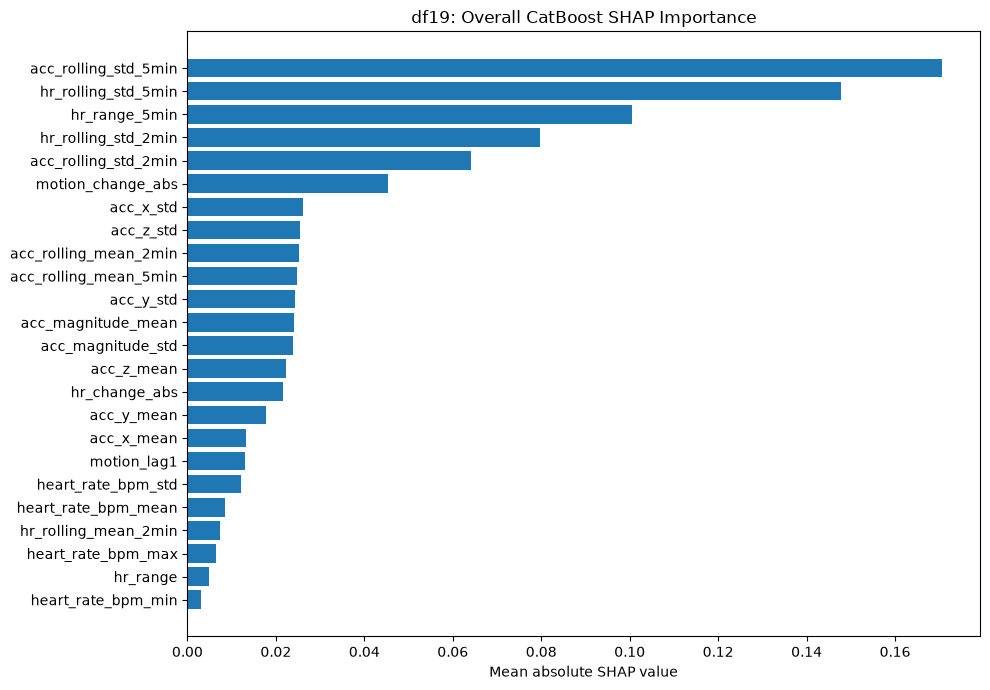

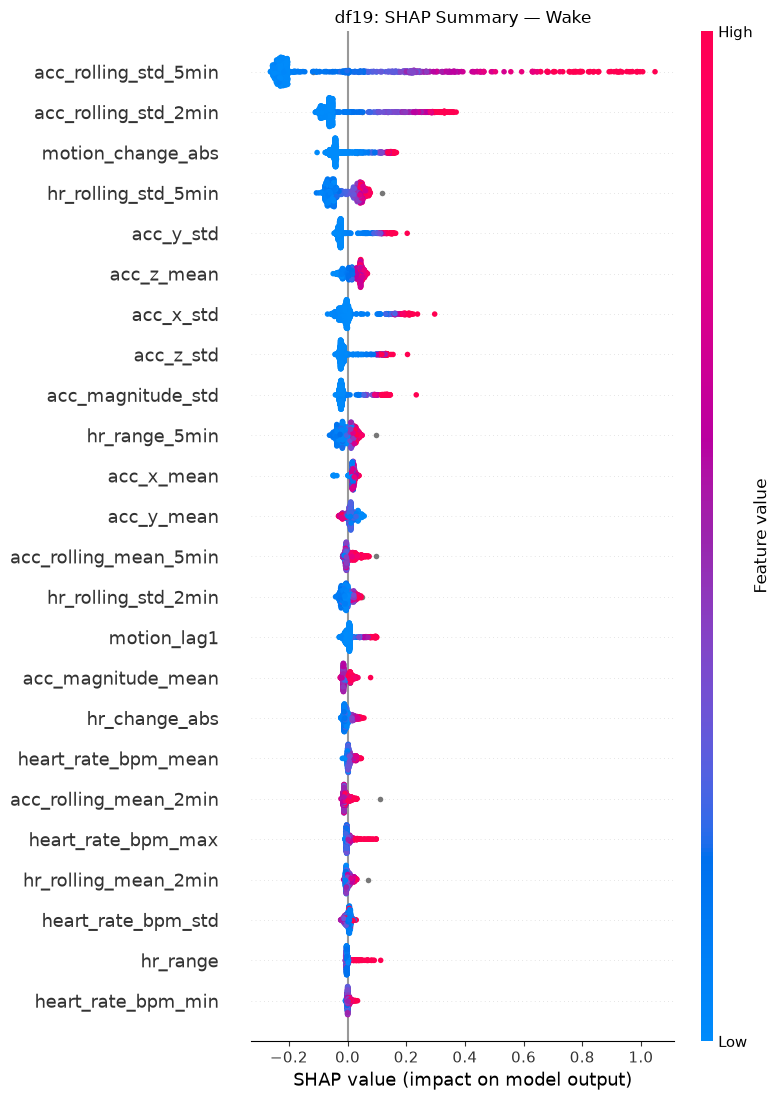

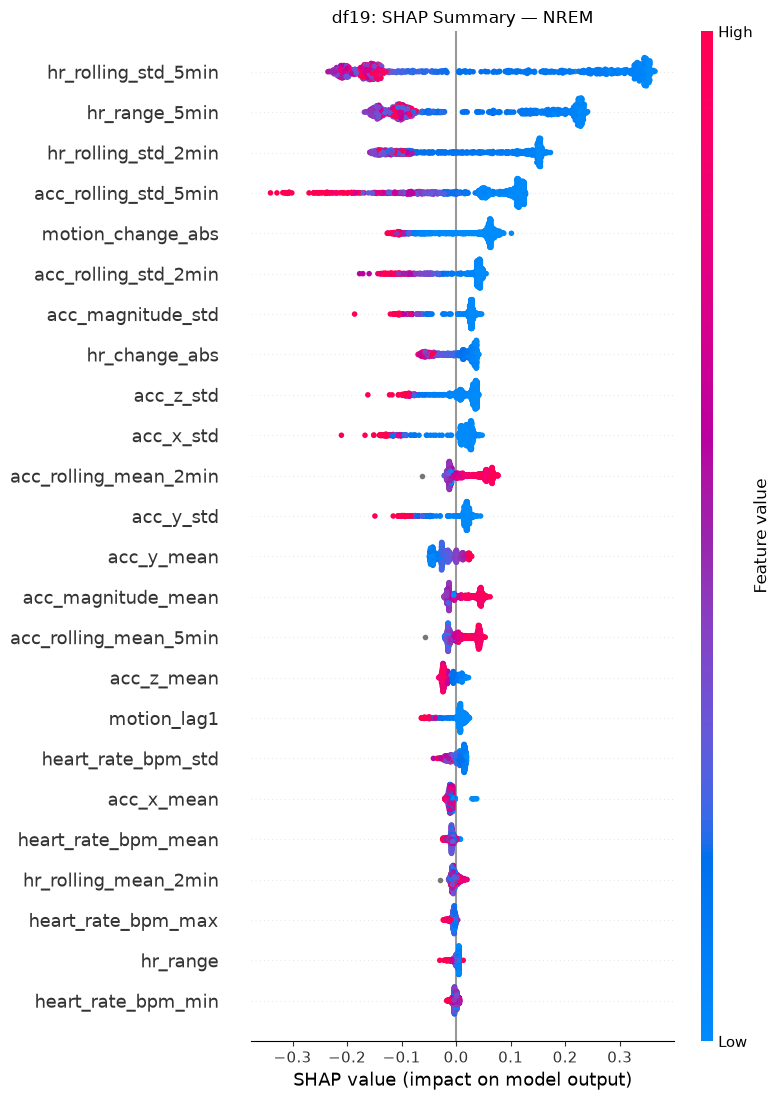

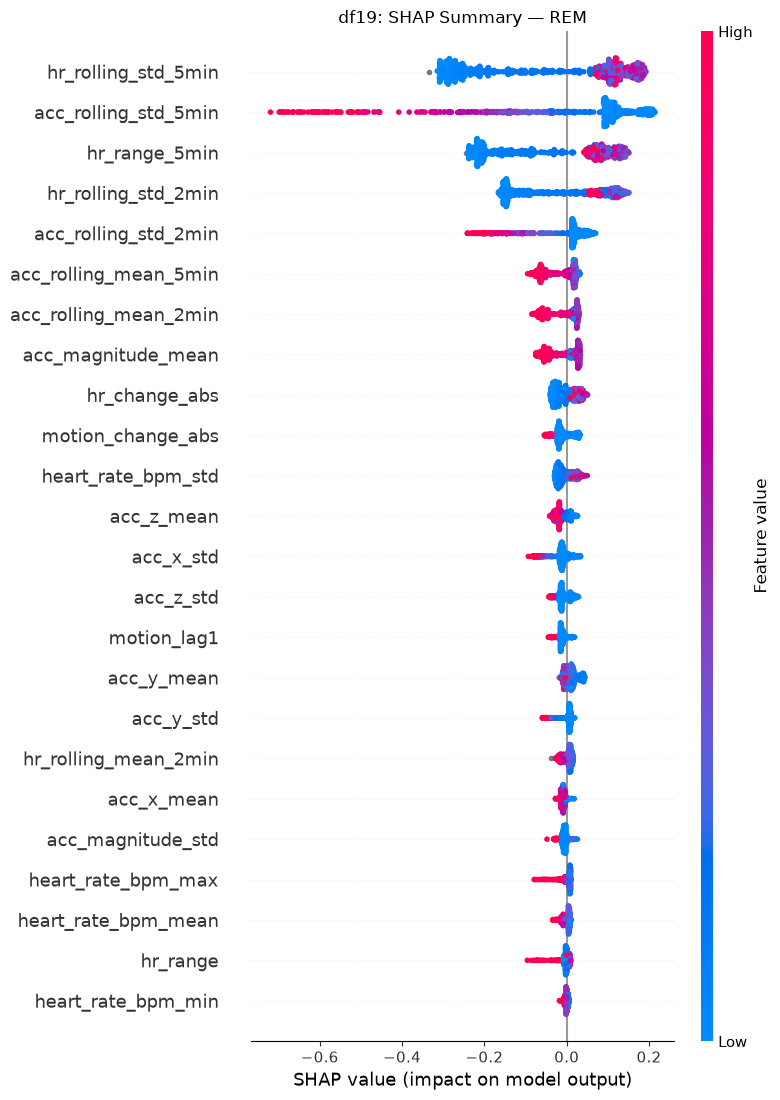

Finished predictions and SHAP for df19.

###########################################################################
CATBOOST EVALUATION: df21
###########################################################################

Classification report — df21
              precision    recall  f1-score   support

        Wake     0.6515    0.4725    0.5478        91
        NREM     0.8730    0.8594    0.8661       384
         REM     0.3939    0.7429    0.5149        35

    accuracy                         0.7824       510
   macro avg     0.6395    0.6916    0.6429       510
weighted avg     0.8006    0.7824    0.7852       510


Confusion matrix — df21
             Predicted_Wake  Predicted_NREM  Predicted_REM
Actual_Wake              43              40              8
Actual_NREM              22             330             32
Actual_REM                1               8             26
Calculating SHAP for 510 rows from df21.


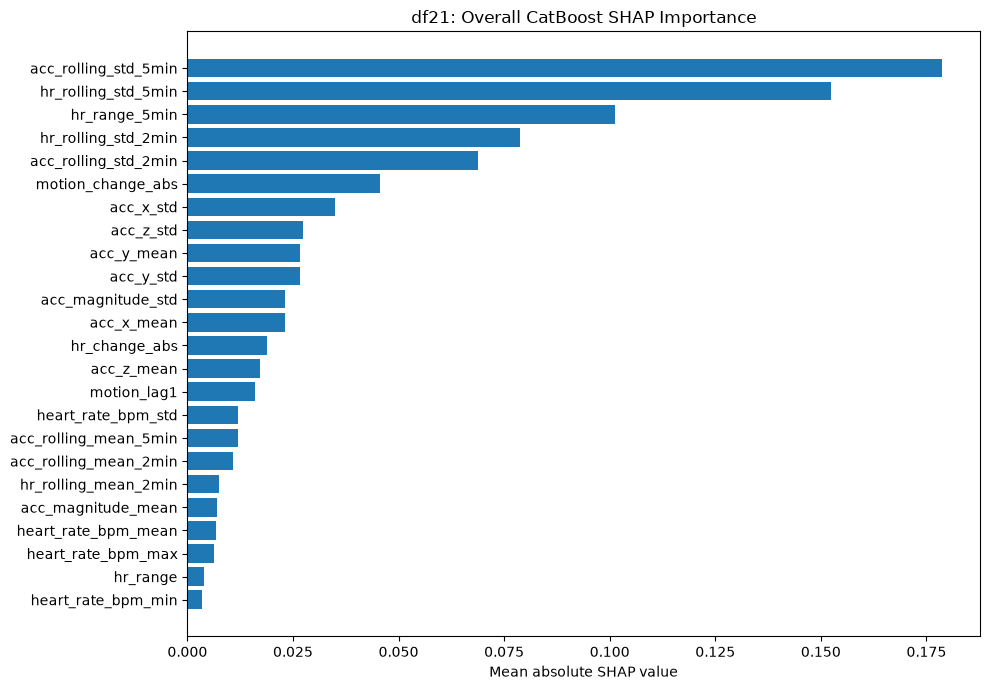

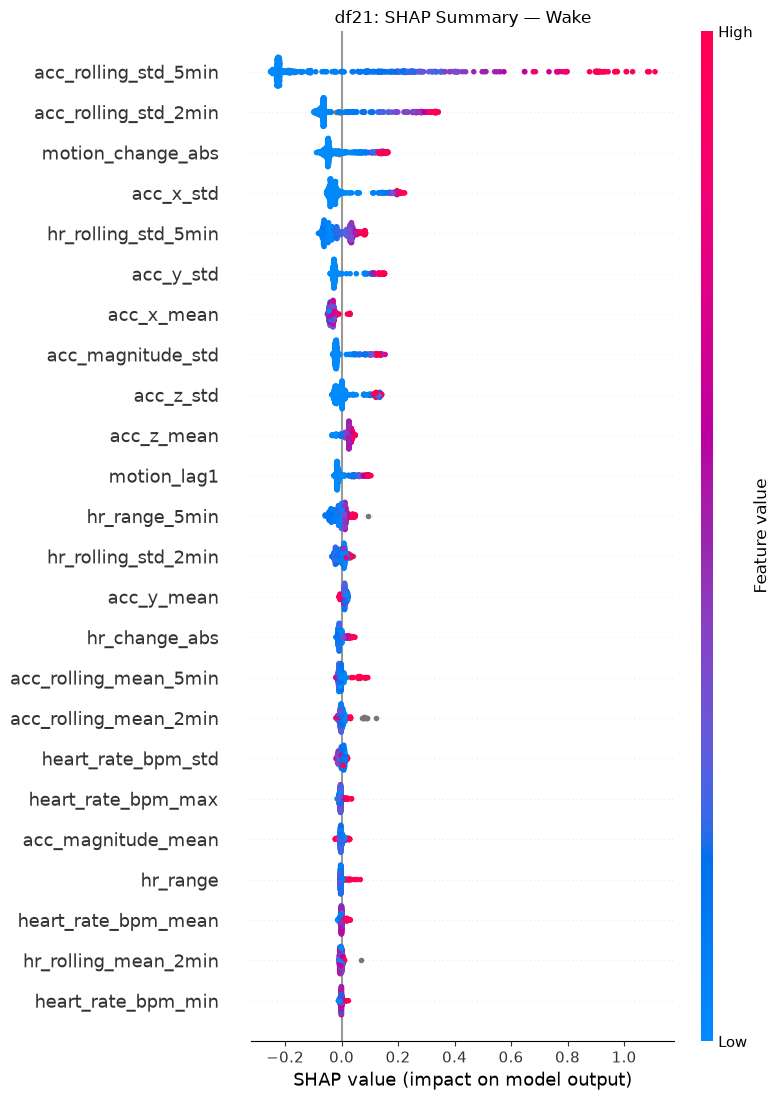

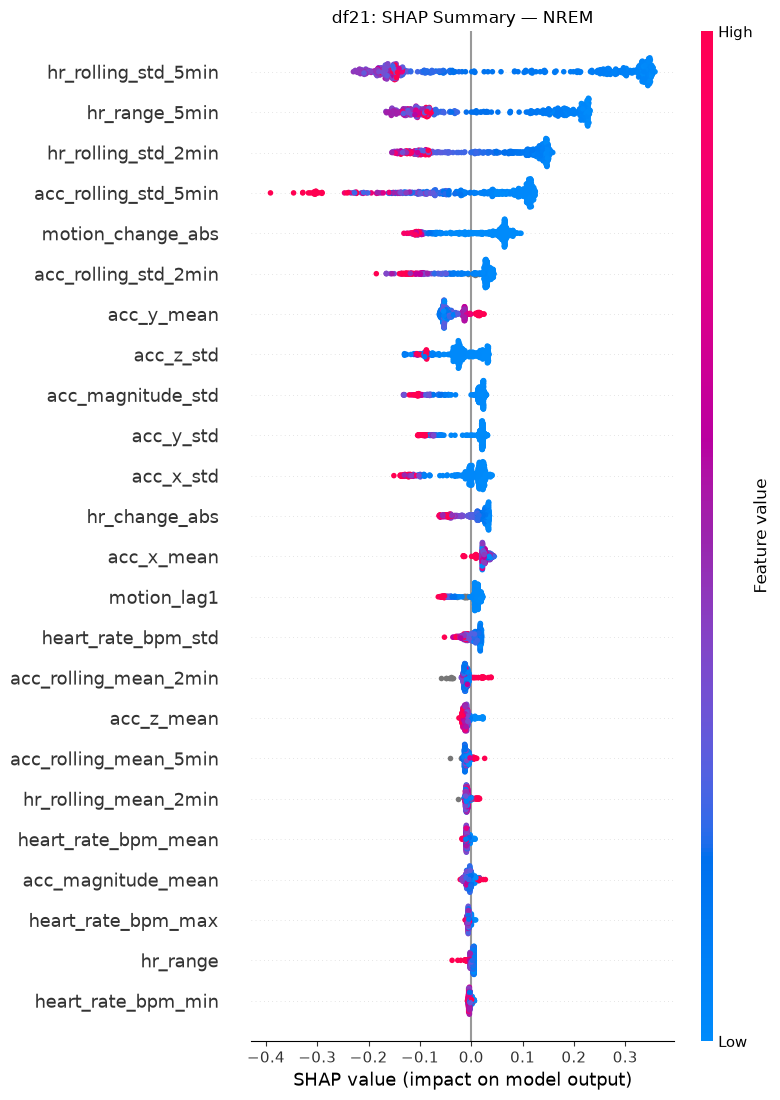

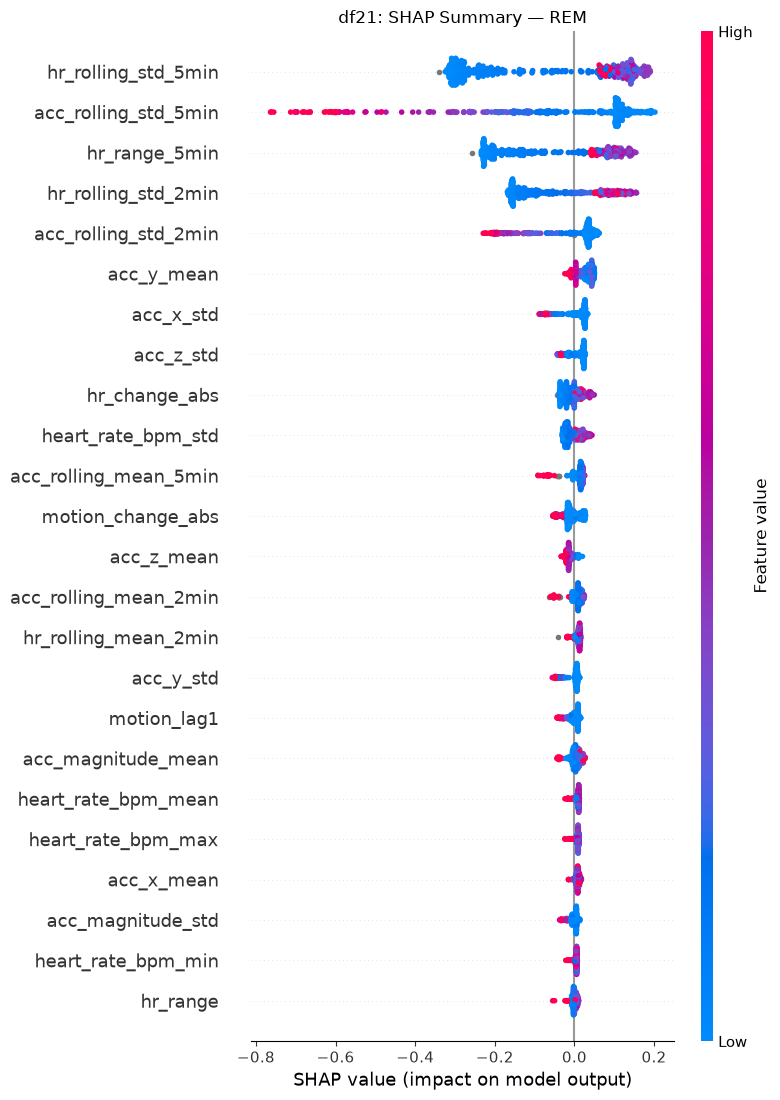

Finished predictions and SHAP for df21.

###########################################################################
CATBOOST EVALUATION: df23
###########################################################################

Classification report — df23
              precision    recall  f1-score   support

        Wake     0.2090    0.7000    0.3218        20
        NREM     0.8499    0.8375    0.8437       683
         REM     0.6308    0.5378    0.5806       251

    accuracy                         0.7558       954
   macro avg     0.5632    0.6918    0.5820       954
weighted avg     0.7788    0.7558    0.7635       954


Confusion matrix — df23
             Predicted_Wake  Predicted_NREM  Predicted_REM
Actual_Wake              14               2              4
Actual_NREM              36             572             75
Actual_REM               17              99            135
Calculating SHAP for 954 rows from df23.


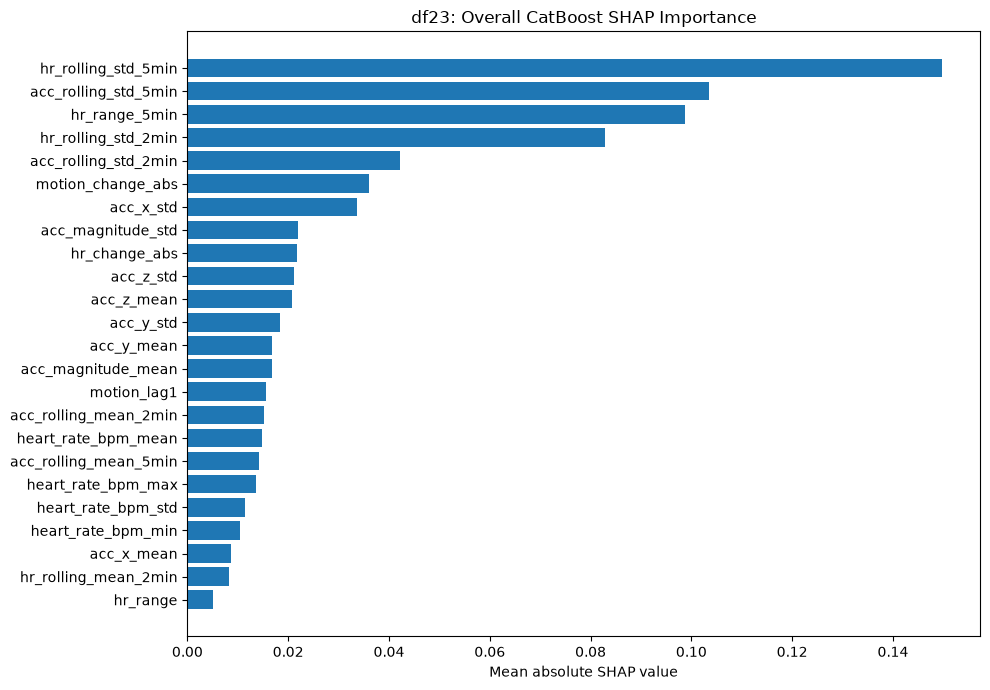

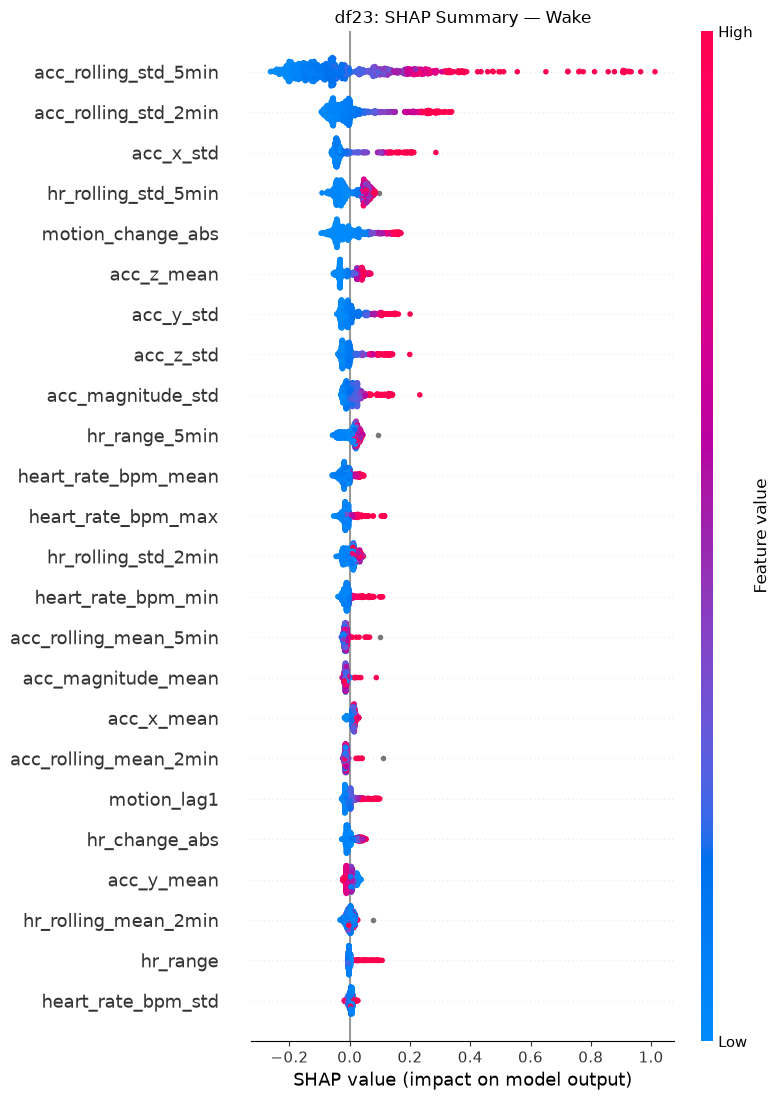

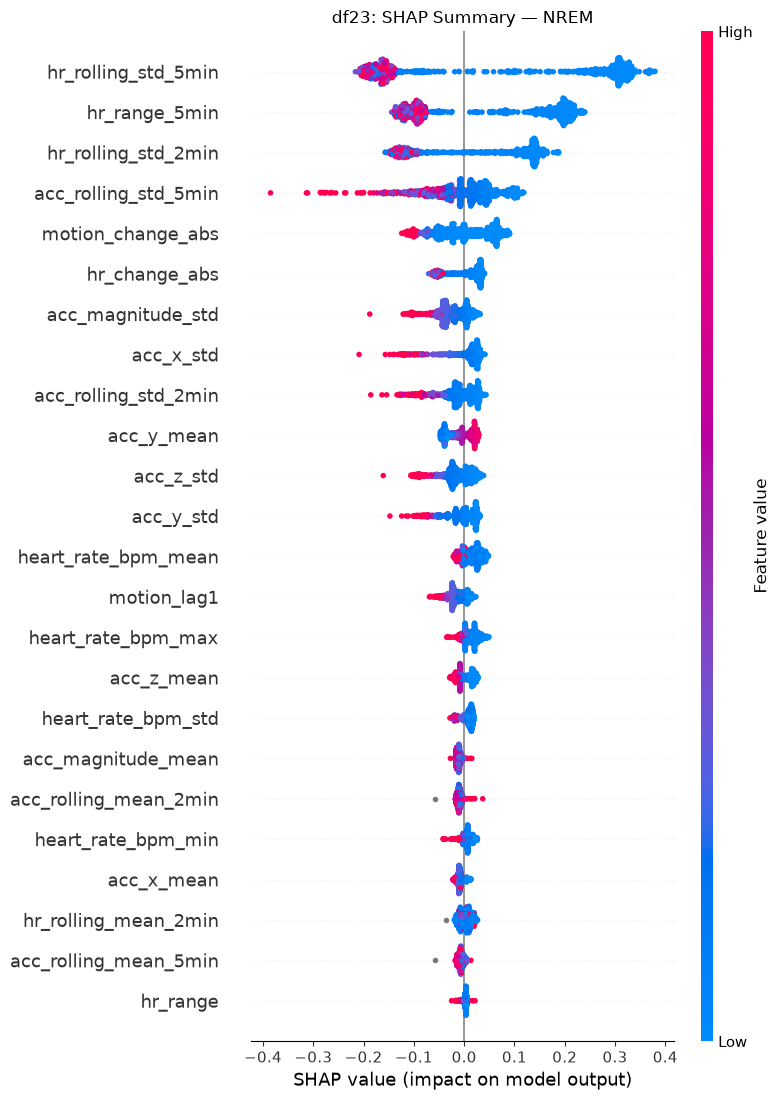

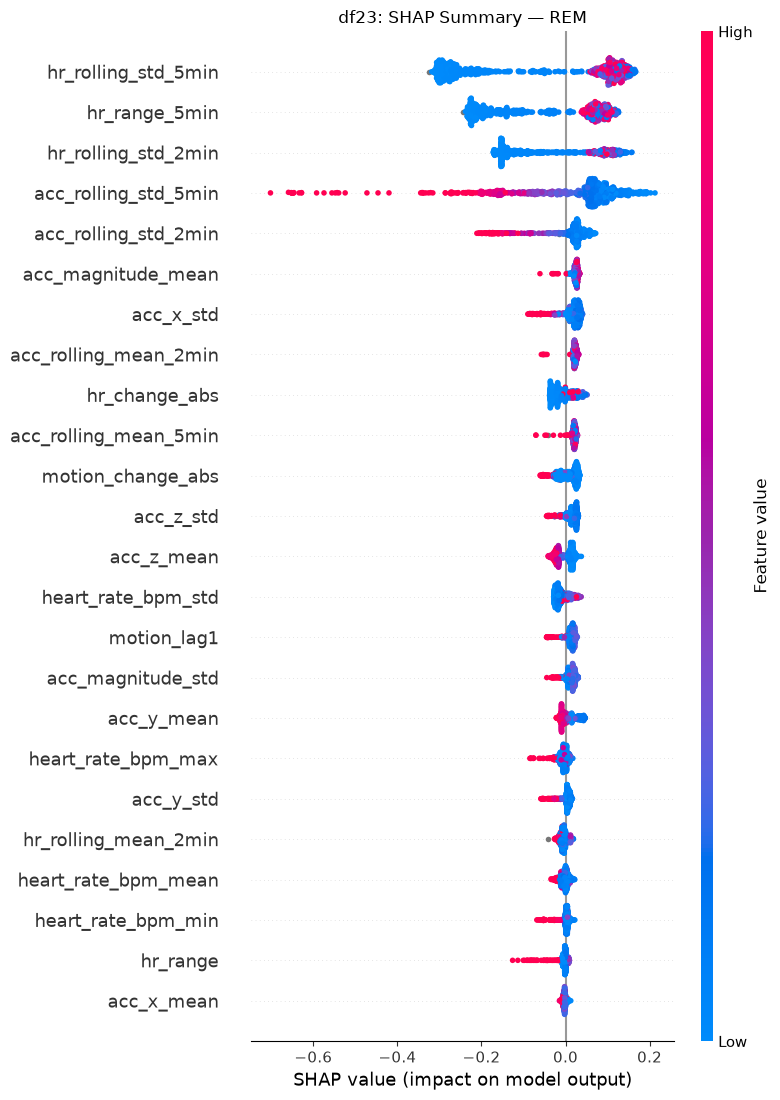

Finished predictions and SHAP for df23.

###########################################################################
CATBOOST EVALUATION: df26
###########################################################################

Classification report — df26
              precision    recall  f1-score   support

        Wake     0.5316    0.3590    0.4286       117
        NREM     0.7500    0.8234    0.7850       623
         REM     0.5027    0.4471    0.4733       208

    accuracy                         0.6835       948
   macro avg     0.5948    0.5432    0.5623       948
weighted avg     0.6688    0.6835    0.6726       948


Confusion matrix — df26
             Predicted_Wake  Predicted_NREM  Predicted_REM
Actual_Wake              42              60             15
Actual_NREM              33             513             77
Actual_REM                4             111             93
Calculating SHAP for 948 rows from df26.


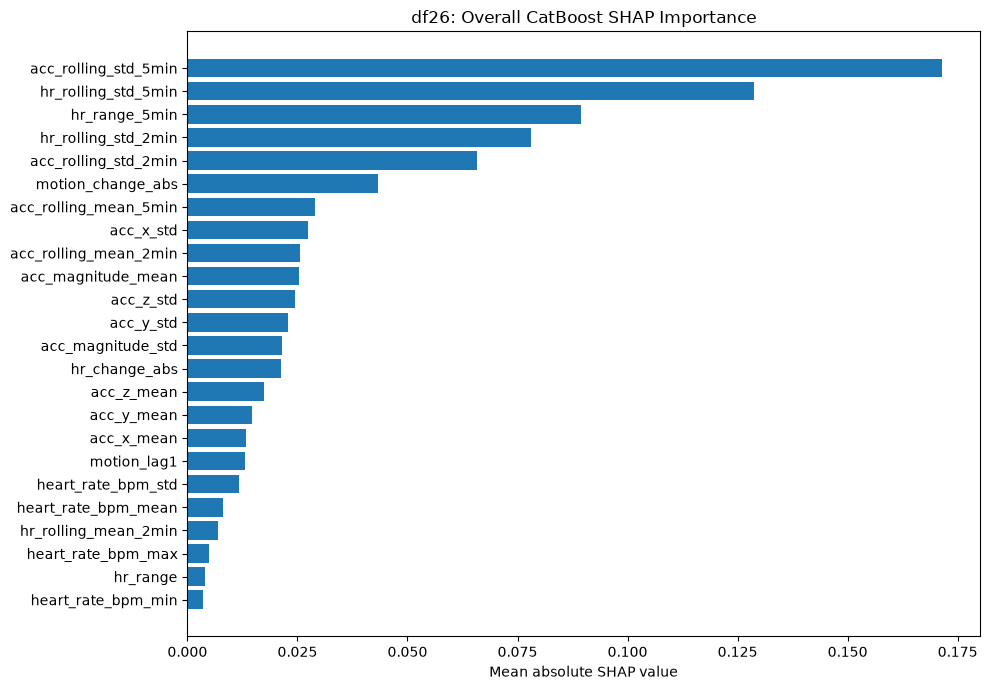

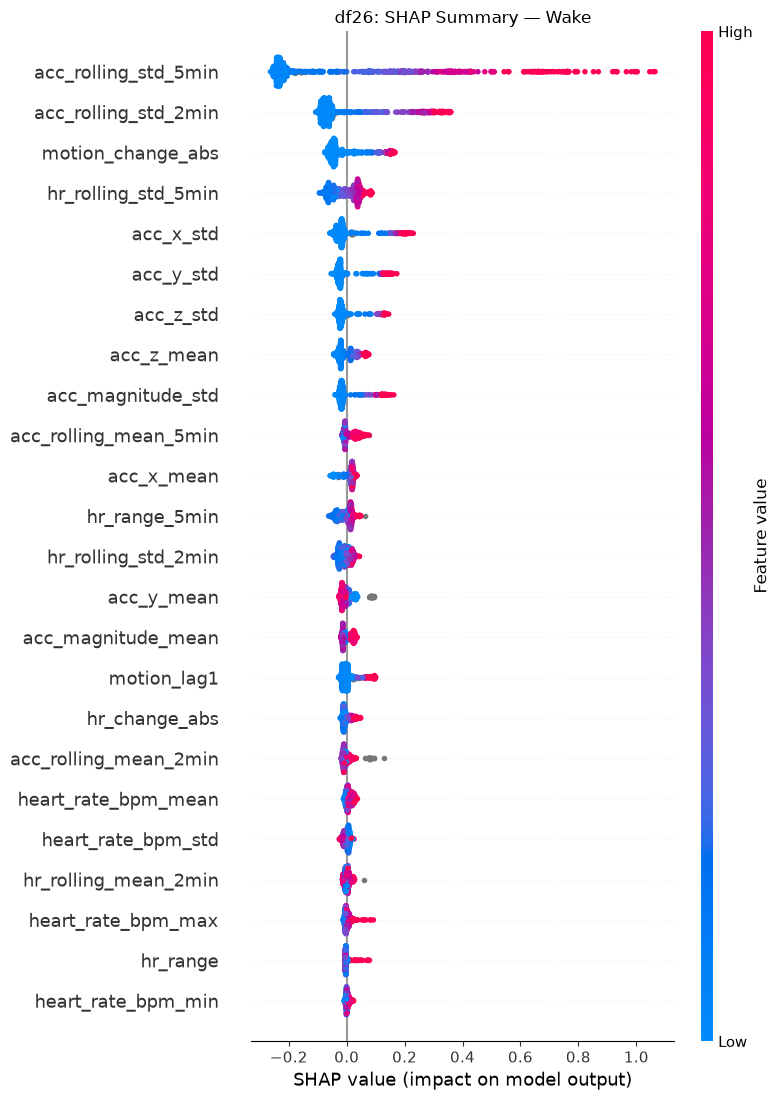

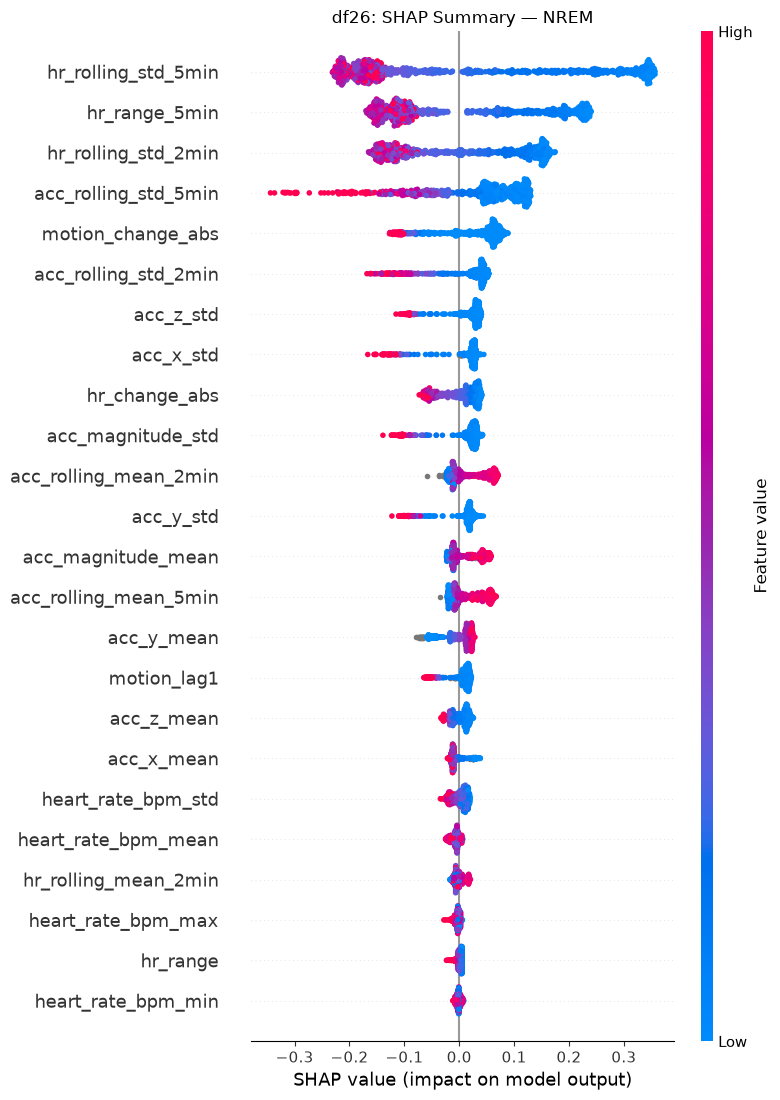

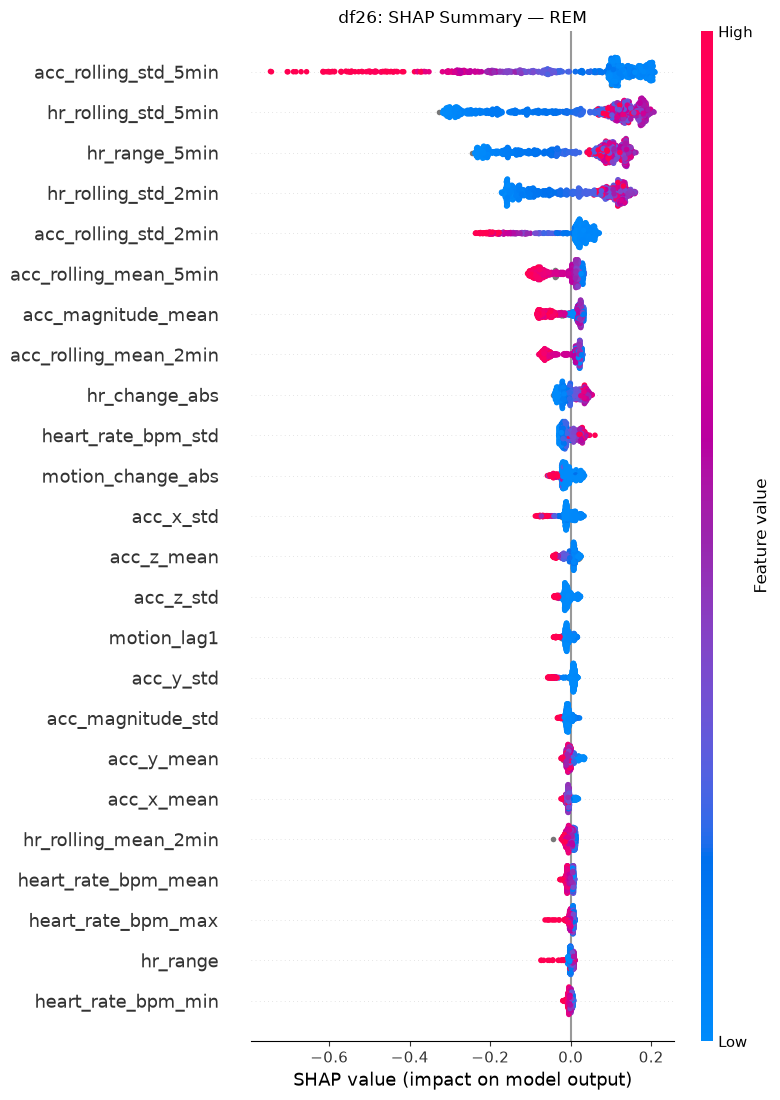

Finished predictions and SHAP for df26.

###########################################################################
CATBOOST EVALUATION: df29
###########################################################################

Classification report — df29
              precision    recall  f1-score   support

        Wake     0.6423    0.4270    0.5130       185
        NREM     0.6187    0.7795    0.6899       458
         REM     0.6389    0.5210    0.5740       309

    accuracy                         0.6271       952
   macro avg     0.6333    0.5758    0.5923       952
weighted avg     0.6298    0.6271    0.6179       952


Confusion matrix — df29
             Predicted_Wake  Predicted_NREM  Predicted_REM
Actual_Wake              79              79             27
Actual_NREM              37             357             64
Actual_REM                7             141            161
Calculating SHAP for 952 rows from df29.


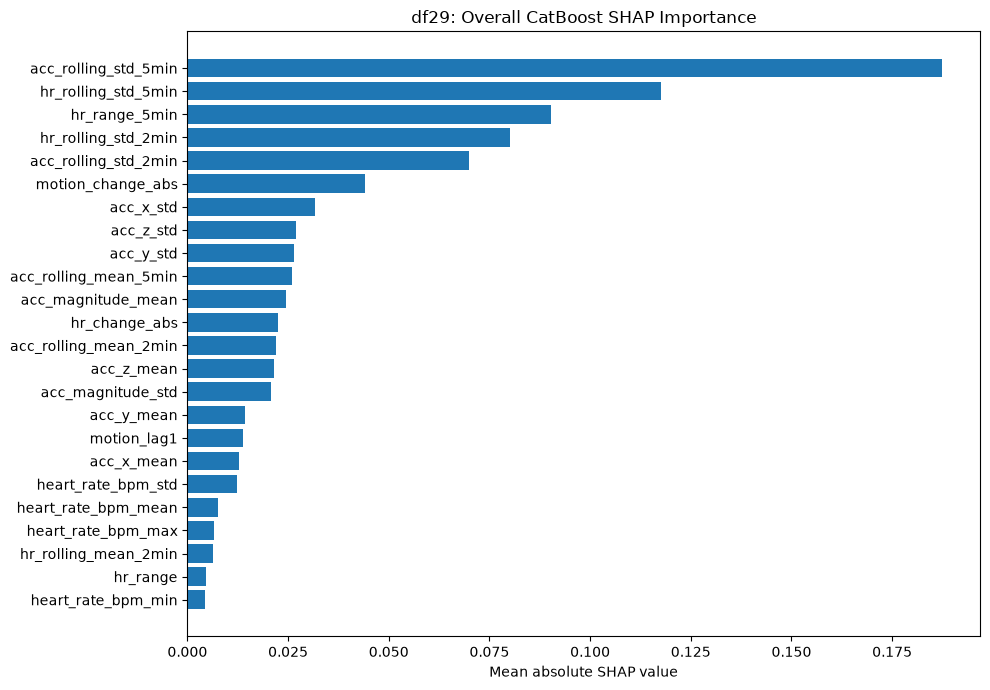

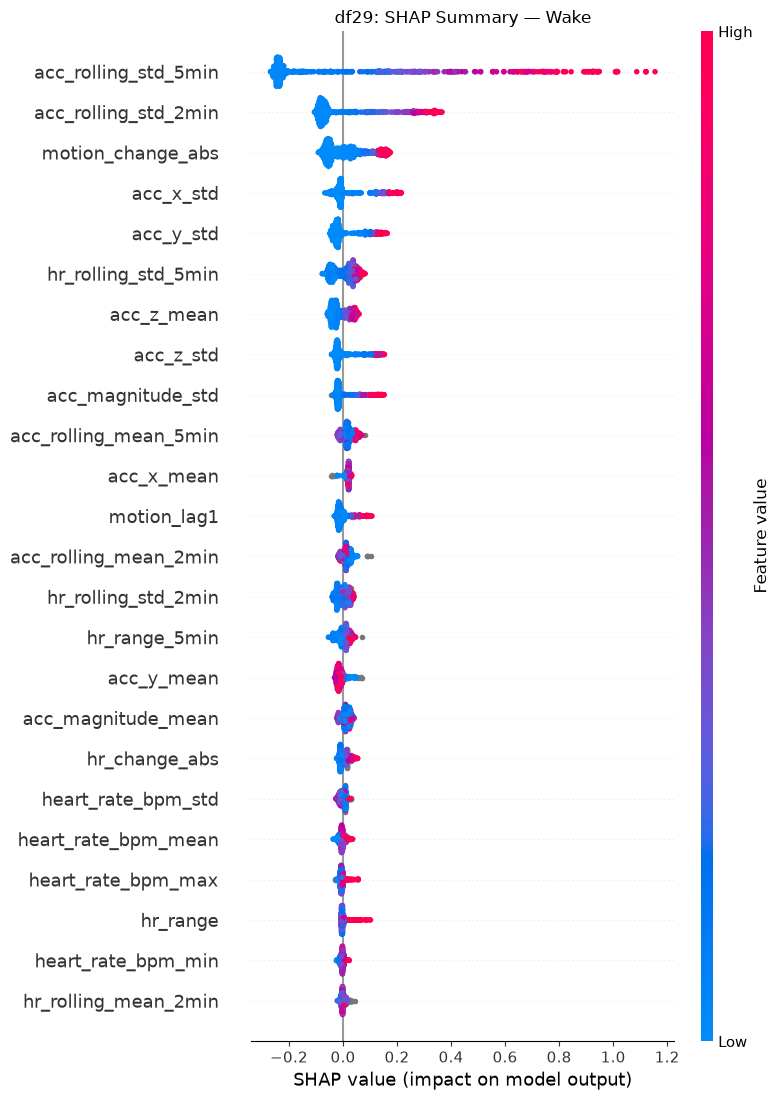

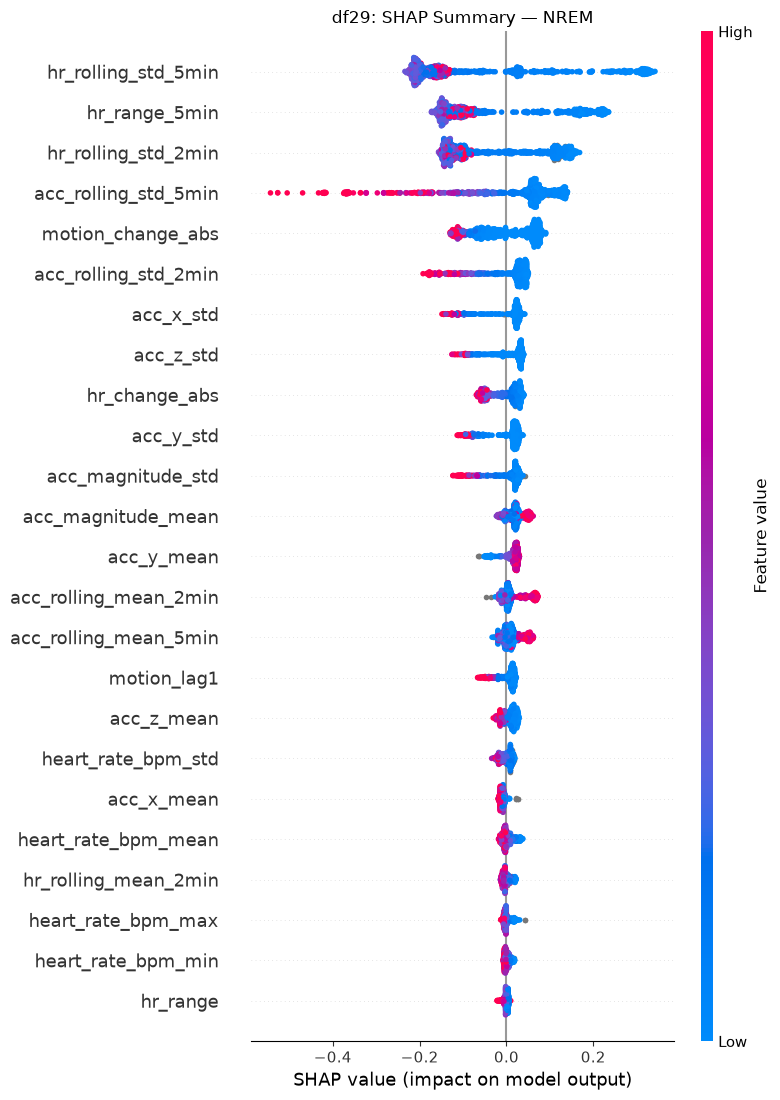

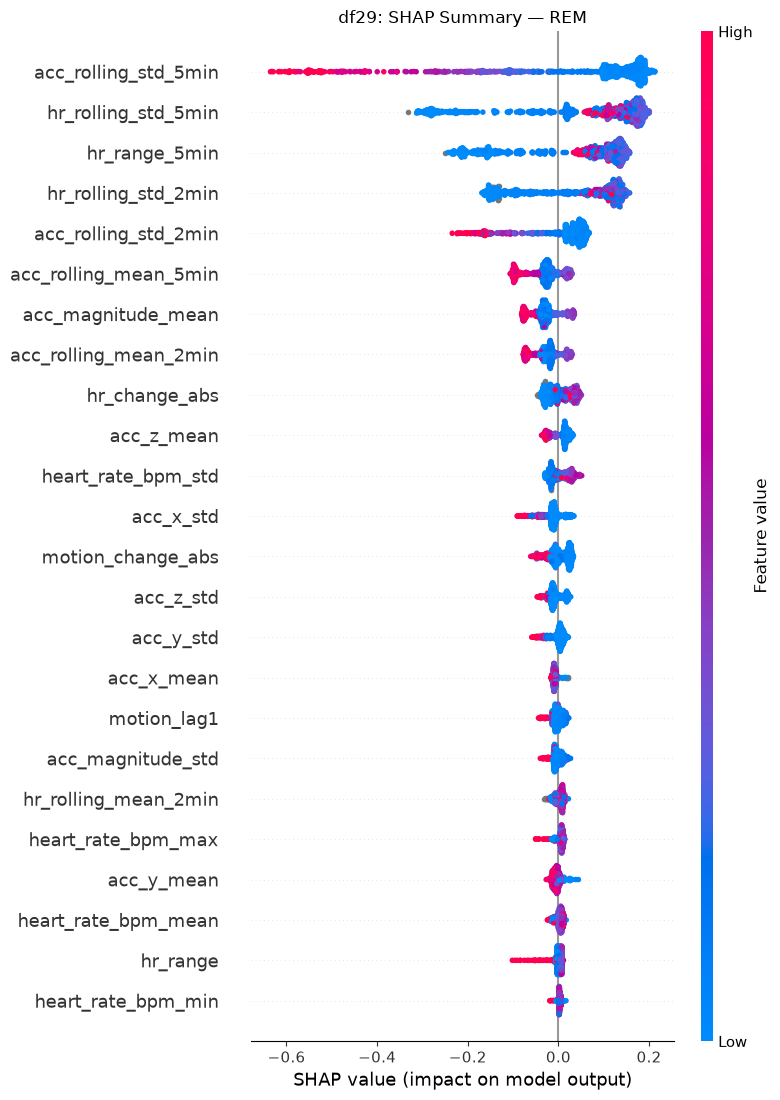

Finished predictions and SHAP for df29.

FINAL SEPARATE TEST METRICS
Test_DataFrame  Rows  Wake_F1  NREM_F1  REM_F1  Macro_F1  Accuracy
           df6   947   0.4844   0.8348  0.7059    0.6750    0.7550
           df8   475   0.5246   0.8419  0.6528    0.6731    0.7642
          df19   953   0.4977   0.8515  0.5430    0.6307    0.7503
          df21   510   0.5478   0.8661  0.5149    0.6429    0.7824
          df23   954   0.3218   0.8437  0.5806    0.5820    0.7558
          df26   948   0.4286   0.7850  0.4733    0.5623    0.6835
          df29   952   0.5130   0.6899  0.5740    0.5923    0.6271

All files saved in: C:\Users\Himanshu kumar\catboost_final_test_shap_results


In [21]:
# ============================================================
# CATBOOST: FINAL MODEL + SEPARATE TEST PREDICTIONS + SHAP
# 1. Loads best CatBoost parameters from saved Optuna CSV
# 2. Excludes external test participants from training
# 3. Participant-wise 4-fold GroupKFold CV
# 4. Fits final CatBoost on all remaining training data
# 5. Separate reports, confusion matrices and predictions
# 6. Overall SHAP bar + class-specific beeswarm plots
# 7. Does NOT rerun Optuna
# 8. No imputer: CatBoost handles numerical NaNs natively
# ============================================================

import os
import ast
import warnings
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import joblib

from catboost import CatBoostClassifier

from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

TARGET = "sleep_stage"
N_SPLITS = 4
RANDOM_SEED = 42
SHAP_SAMPLE_SIZE = 1000

CLASS_LABELS = [0, 1, 2]
CLASS_NAMES = ["Wake", "NREM", "REM"]

TEST_FRAMES = {
    "df6": df6,
    "df8": df8,
    "df19": df19,
    "df21": df21,
    "df23": df23,
    "df26": df26,
    "df29": df29,
}

PARAMS_FILE = "sleep_stage_optuna_best_params.csv"

OUTPUT_DIR = "catboost_final_test_shap_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD BEST CATBOOST PARAMETERS FROM SAVED OPTUNA CSV
# ------------------------------------------------------------

if not os.path.exists(PARAMS_FILE):
    raise FileNotFoundError(
        f"Cannot find {PARAMS_FILE}. "
        "Place it in your current working directory."
    )

params_df = pd.read_csv(PARAMS_FILE)

if not {"model", "best_params"}.issubset(params_df.columns):
    raise ValueError(
        f"{PARAMS_FILE} must contain "
        "'model' and 'best_params' columns."
    )

catboost_rows = params_df[
    params_df["model"].astype(str).str.strip().str.lower()
    == "catboost"
]

if catboost_rows.empty:
    raise ValueError(
        f"No CatBoost row found in {PARAMS_FILE}."
    )

saved_params_text = str(
    catboost_rows.iloc[0]["best_params"]
).strip()

try:
    BEST_PARAMS = ast.literal_eval(saved_params_text)

except (ValueError, SyntaxError):
    # Also support JSON-formatted parameter dictionaries.
    BEST_PARAMS = json.loads(saved_params_text)

if not isinstance(BEST_PARAMS, dict):
    raise ValueError(
        "CatBoost best_params must be a dictionary."
    )

# Preserve Optuna-selected hyperparameters.
# Only set runtime options separately.
BEST_PARAMS = dict(BEST_PARAMS)

for key in [
    "random_seed",
    "random_state",
    "verbose",
    "logging_level",
    "thread_count",
    "allow_writing_files"
]:
    BEST_PARAMS.pop(key, None)

BEST_PARAMS.update({
    "random_seed": RANDOM_SEED,
    "verbose": 0,
    "thread_count": 4,
    "allow_writing_files": False
})

print(
    "Loaded best parameters from:",
    os.path.abspath(PARAMS_FILE)
)

print("\nUsing saved CatBoost parameters:")
print(BEST_PARAMS)

# ------------------------------------------------------------
# 3. IDENTIFY PARTICIPANT/GROUP COLUMN
# ------------------------------------------------------------

possible_group_columns = [
    "participant_id",
    "person_id",
    "patient_id"
]

group_col = next(
    (
        col for col in possible_group_columns
        if col in data.columns
    ),
    None
)

if group_col is None:
    raise ValueError(
        "No participant ID column found in data. "
        "Expected participant_id, person_id or patient_id."
    )

if TARGET not in data.columns:
    raise ValueError(
        f"Missing target column: {TARGET}"
    )

print("\nParticipant grouping column:", group_col)

# ------------------------------------------------------------
# 4. CLEAN TEST DATAFRAMES
# ------------------------------------------------------------

clean_test_frames = {}

for test_name, test_df in TEST_FRAMES.items():

    if TARGET not in test_df.columns:
        raise ValueError(
            f"{test_name} does not contain {TARGET}."
        )

    test_clean = test_df.copy()

    # Remove rows without a target label.
    # Feature NaNs are retained for CatBoost.
    test_clean = test_clean.dropna(subset=[TARGET])

    test_clean[TARGET] = test_clean[TARGET].astype(int)

    clean_test_frames[test_name] = test_clean

    print(
        f"{test_name}: {len(test_clean):,} labelled rows; "
        f"classes = "
        f"{sorted(test_clean[TARGET].unique().tolist())}"
    )

# ------------------------------------------------------------
# 5. REMOVE TEST PARTICIPANTS FROM TRAINING DATA
# ------------------------------------------------------------

test_group_ids = set()

for test_name, test_df in clean_test_frames.items():

    if group_col not in test_df.columns:
        raise ValueError(
            f"{test_name} has no '{group_col}' column. "
            "Cannot verify participant-level separation."
        )

    test_group_ids.update(
        test_df[group_col].dropna().unique().tolist()
    )

train_data = data.copy()

# Exclude every participant used in the external test sets.
train_data = train_data[
    ~train_data[group_col].isin(test_group_ids)
].copy()

# Remove rows without target labels.
train_data = train_data.dropna(subset=[TARGET]).copy()

train_data[TARGET] = train_data[TARGET].astype(int)

if train_data.empty:
    raise ValueError(
        "Training data is empty after removing test participants."
    )

train_group_ids = set(
    train_data[group_col].dropna().unique().tolist()
)

overlap = train_group_ids.intersection(test_group_ids)

if overlap:
    raise RuntimeError(
        f"Test/train participant leakage detected: {overlap}"
    )

print("\nTraining participants:", len(train_group_ids))
print("Training rows:", f"{len(train_data):,}")
print("Test participants are excluded from training.")

# ------------------------------------------------------------
# 6. PREPARE FEATURES
# ------------------------------------------------------------

excluded_columns = {
    TARGET,
    "participant_id",
    "person_id",
    "patient_id",
    "epoch",
    "timestamp",
    "seconds",
    "time"
}

feature_cols = [
    col
    for col in train_data.select_dtypes(
        include=np.number
    ).columns
    if col not in excluded_columns
]

if not feature_cols:
    raise ValueError("No numeric features found.")

missing_classes = (
    set(CLASS_LABELS)
    - set(train_data[TARGET].unique())
)

if missing_classes:
    raise ValueError(
        f"Training data is missing classes: {missing_classes}"
    )

# Replace positive/negative infinity with NaN.
# Do not impute missing feature values.
X_train_raw = (
    train_data[feature_cols]
    .replace([np.inf, -np.inf], np.nan)
    .copy()
)

y_train = train_data[TARGET].copy()

groups = train_data[group_col].copy()

print("\nNumber of features:", len(feature_cols))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nFeatures used:")
print(feature_cols)

# Verify that every external test dataframe contains all features.
for test_name, test_df in clean_test_frames.items():

    missing_features = [
        col for col in feature_cols
        if col not in test_df.columns
    ]

    if missing_features:
        raise ValueError(
            f"{test_name} is missing features: "
            f"{missing_features}"
        )

# ------------------------------------------------------------
# 7. MODEL BUILDER
# ------------------------------------------------------------

def make_catboost():
    return CatBoostClassifier(**BEST_PARAMS)

# ------------------------------------------------------------
# 8. PARTICIPANT-WISE 4-FOLD GROUP CROSS-VALIDATION
# NO IMPUTER
# ------------------------------------------------------------

cv = GroupKFold(n_splits=N_SPLITS)

cv_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(
        X_train_raw,
        y_train,
        groups=groups
    ),
    start=1
):

    X_fold_train = X_train_raw.iloc[train_idx].copy()
    X_fold_valid = X_train_raw.iloc[valid_idx].copy()

    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[valid_idx]

    fold_train_groups = set(
        groups.iloc[train_idx].unique()
    )

    fold_valid_groups = set(
        groups.iloc[valid_idx].unique()
    )

    if fold_train_groups.intersection(fold_valid_groups):
        raise RuntimeError(
            f"Participant leakage detected in fold {fold}."
        )

    # CatBoost handles numerical NaNs natively.
    fold_model = make_catboost()

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    fold_pred = np.asarray(
        fold_model.predict(X_fold_valid)
    ).reshape(-1).astype(int)

    fold_f1 = f1_score(
        y_fold_valid,
        fold_pred,
        labels=CLASS_LABELS,
        average="macro",
        zero_division=0
    )

    fold_accuracy = accuracy_score(
        y_fold_valid,
        fold_pred
    )

    cv_results.append({
        "Fold": fold,
        "Macro_F1": fold_f1,
        "Accuracy": fold_accuracy
    })

    print(
        f"Fold {fold}/{N_SPLITS} | "
        f"Train rows: {len(train_idx):,} | "
        f"Validation rows: {len(valid_idx):,} | "
        f"Macro-F1: {fold_f1:.4f} | "
        f"Accuracy: {fold_accuracy:.4f}"
    )

    del fold_model
    del X_fold_train, X_fold_valid

    gc.collect()

# Save CV metrics.
cv_results_df = pd.DataFrame(cv_results)

cv_results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "catboost_cv_fold_metrics.csv"
    ),
    index=False
)

print("\nCV summary:")

print(
    cv_results_df[
        ["Macro_F1", "Accuracy"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

# ------------------------------------------------------------
# 9. FIT FINAL CATBOOST ON ALL TRAINING PARTICIPANTS
# NO IMPUTER
# ------------------------------------------------------------

# Preserve all feature NaNs.
X_train = X_train_raw.copy()

model = make_catboost()

model.fit(
    X_train,
    y_train
)

print("\nFinal CatBoost model fitted.")
print("Training rows:", len(X_train))
print("Feature count:", len(feature_cols))
print("Model parameters:")
print(model.get_params())

# Save trained model.
joblib.dump(
    model,
    os.path.join(
        OUTPUT_DIR,
        "final_catboost_model.joblib"
    )
)

# Save feature names.
pd.Series(
    feature_cols,
    name="feature"
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "catboost_feature_columns.csv"
    ),
    index=False
)

# Save the best parameters used by the model.
pd.Series(
    BEST_PARAMS,
    name="value"
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "catboost_best_parameters.csv"
    )
)

print("\nFinal model, feature names and parameters saved.")

# ------------------------------------------------------------
# 10. SHAP EXPLAINER
# ------------------------------------------------------------

explainer = shap.TreeExplainer(model)

test_metrics = []

shap_importance_tables = {}

# ------------------------------------------------------------
# 11. SEPARATE PREDICTIONS, REPORTS AND SHAP FOR EACH TEST DF
# ------------------------------------------------------------

for test_name, test_df in clean_test_frames.items():

    print("\n" + "#" * 75)
    print(f"CATBOOST EVALUATION: {test_name}")
    print("#" * 75)

    X_test_raw = (
        test_df[feature_cols]
        .replace([np.inf, -np.inf], np.nan)
        .copy()
    )

    # No imputer. Preserve missing feature values.
    X_test = X_test_raw.copy()

    y_test = test_df[TARGET].astype(int)

    # Make predictions.
    y_pred = np.asarray(
        model.predict(X_test)
    ).reshape(-1).astype(int)

    # --------------------------------------------------------
    # 11A. SAVE PREDICTIONS
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({
        "actual_sleep_stage": y_test.to_numpy(),
        "predicted_sleep_stage": y_pred
    })

    for col in [
        group_col,
        "epoch",
        "timestamp",
        "seconds"
    ]:

        if col in test_df.columns:
            prediction_df[col] = test_df[col].to_numpy()

    prediction_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{test_name}_catboost_predictions.csv"
        ),
        index=False
    )

    # --------------------------------------------------------
    # 11B. CLASSIFICATION REPORT
    # --------------------------------------------------------

    print(f"\nClassification report — {test_name}")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=CLASS_LABELS,
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # 11C. CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=CLASS_LABELS
    )

    cm_df = pd.DataFrame(
        cm,
        index=[
            f"Actual_{c}" for c in CLASS_NAMES
        ],
        columns=[
            f"Predicted_{c}" for c in CLASS_NAMES
        ]
    )

    print(f"\nConfusion matrix — {test_name}")
    print(cm_df)

    cm_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{test_name}_catboost_confusion_matrix.csv"
        )
    )

    # --------------------------------------------------------
    # 11D. TEST METRICS
    # --------------------------------------------------------

    report_dict = classification_report(
        y_test,
        y_pred,
        labels=CLASS_LABELS,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=CLASS_LABELS,
        average="macro",
        zero_division=0
    )

    test_metrics.append({
        "Test_DataFrame": test_name,
        "Rows": len(y_test),
        "Wake_F1": report_dict["Wake"]["f1-score"],
        "NREM_F1": report_dict["NREM"]["f1-score"],
        "REM_F1": report_dict["REM"]["f1-score"],
        "Macro_F1": macro_f1,
        "Accuracy": accuracy_score(y_test, y_pred)
    })

    # --------------------------------------------------------
    # 12. SHAP SAMPLE
    # --------------------------------------------------------

    n_sample = min(
        SHAP_SAMPLE_SIZE,
        len(X_test)
    )

    if n_sample == 0:
        print(f"No test rows available in {test_name}. Skipping SHAP.")
        continue

    X_shap = X_test.sample(
        n=n_sample,
        random_state=RANDOM_SEED
    )

    print(
        f"Calculating SHAP for {len(X_shap):,} rows "
        f"from {test_name}."
    )

    shap_raw = explainer.shap_values(X_shap)

    # --------------------------------------------------------
    # 12A. NORMALIZE SHAP OUTPUT FORMATS
    # --------------------------------------------------------

    if isinstance(shap_raw, list):

        class_shap_values = [
            np.asarray(v)
            for v in shap_raw
        ]

    else:

        values = np.asarray(shap_raw)

        if values.ndim == 2:

            class_shap_values = [values]

        elif values.ndim == 3:

            if (
                values.shape[0] == len(X_shap)
                and values.shape[1] == len(feature_cols)
            ):
                # Shape: rows x features x classes
                class_shap_values = [
                    values[:, :, i]
                    for i in range(values.shape[2])
                ]

            elif (
                values.shape[1] == len(X_shap)
                and values.shape[2] == len(feature_cols)
            ):
                # Shape: classes x rows x features
                class_shap_values = [
                    values[i, :, :]
                    for i in range(values.shape[0])
                ]

            else:
                raise ValueError(
                    f"Unexpected SHAP shape for {test_name}: "
                    f"{values.shape}"
                )

        else:

            raise ValueError(
                f"Unexpected SHAP dimensions: {values.shape}"
            )

    if len(class_shap_values) != len(CLASS_LABELS):
        raise ValueError(
            f"{test_name}: expected SHAP values for 3 classes, "
            f"received {len(class_shap_values)}."
        )

    # --------------------------------------------------------
    # 13. OVERALL SHAP FEATURE IMPORTANCE
    # --------------------------------------------------------

    overall_importance = np.mean(
        np.vstack([
            np.abs(class_values).mean(axis=0)
            for class_values in class_shap_values
        ]),
        axis=0
    )

    importance_df = pd.DataFrame({
        "Feature": feature_cols,
        "Mean_Absolute_SHAP": overall_importance
    }).sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )

    shap_importance_tables[test_name] = importance_df

    importance_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{test_name}_catboost_shap_importance.csv"
        ),
        index=False
    )

    # --------------------------------------------------------
    # 13A. OVERALL SHAP BAR PLOT
    # --------------------------------------------------------

    plot_df = importance_df.sort_values(
        "Mean_Absolute_SHAP",
        ascending=True
    )

    plt.figure(
        figsize=(10, max(7, len(feature_cols) * 0.28))
    )

    plt.barh(
        plot_df["Feature"],
        plot_df["Mean_Absolute_SHAP"]
    )

    plt.xlabel("Mean absolute SHAP value")

    plt.title(
        f"{test_name}: Overall CatBoost SHAP Importance"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{test_name}_overall_shap_bar.png"
        ),
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # --------------------------------------------------------
    # 14. CLASS-SPECIFIC SHAP BEESWARM PLOTS
    # --------------------------------------------------------

    for class_idx, class_name in enumerate(CLASS_NAMES):

        class_values = class_shap_values[class_idx]

        plt.figure(figsize=(10, 8))

        shap.summary_plot(
            class_values,
            X_shap,
            feature_names=feature_cols,
            max_display=len(feature_cols),
            show=False
        )

        plt.title(
            f"{test_name}: SHAP Summary — {class_name}"
        )

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                f"{test_name}_shap_beeswarm_{class_name.lower()}.png"
            ),
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

    # --------------------------------------------------------
    # 14A. RELEASE MEMORY
    # --------------------------------------------------------

    del X_test_raw
    del X_test
    del X_shap
    del shap_raw
    del class_shap_values

    gc.collect()

    print(
        f"Finished predictions and SHAP for {test_name}."
    )

# ------------------------------------------------------------
# 15. FINAL TEST METRICS SUMMARY
# ------------------------------------------------------------

test_metrics_df = pd.DataFrame(test_metrics)

test_metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "catboost_separate_test_metrics.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("FINAL SEPARATE TEST METRICS")
print("=" * 75)

print(
    test_metrics_df.round(4).to_string(index=False)
)

print(
    "\nAll files saved in:",
    os.path.abspath(OUTPUT_DIR)
)

In [23]:
# =====================================================
# 1. PREPARE DATA
# =====================================================

df_train = df.copy()

X = df_train.drop(columns=['sleep_stage'])

y = df_train['sleep_stage']

exclude_cols = [
    "sleep_stage", "participant_id", "person_id",
    "patient_id", "epoch", "timestamp", "seconds", "time"
]

X = df_train.drop(
    columns=[c for c in exclude_cols if c in df_train.columns]
)

X = X.select_dtypes(include=[np.number])

In [22]:
import os
import joblib
from catboost import CatBoostClassifier

os.makedirs("models", exist_ok=True)

# Best parameters loaded from Optuna
BEST_PARAMS = {
    'iterations': 600,
    'depth': 5,
    'learning_rate': 0.005914960414922768,
    'l2_leaf_reg': 0.05182708999820843,
    'random_strength': 5.093559517915639,
    'bagging_temperature': 1.7651773204642311,
    'border_count': 64,
    'auto_class_weights': 'SqrtBalanced'
}

# Train final CatBoost model on ALL training data
final_model = CatBoostClassifier(
    **BEST_PARAMS,
    loss_function="MultiClass",
    verbose=False,
    thread_count=4,
    random_seed=42,
    allow_writing_files=False
)

final_model.fit(X, y)

# Save trained model
final_model.save_model(
    "models/catboost_sleep_stage.cbm"
)

# Save best parameters
joblib.dump(
    BEST_PARAMS,
    "models/catboost_best_params.pkl"
)

# Save feature names and their exact order
joblib.dump(
    list(X.columns),
    "models/catboost_feature_columns.pkl"
)

print("Final CatBoost model trained and saved!")

Final CatBoost model trained and saved!
